# 01 · EDA por tablas

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve()
while not (RAIZ / 'src' / 'config.py').exists() and RAIZ != RAIZ.parent:
    RAIZ = RAIZ.parent
if str(RAIZ) not in sys.path:
    sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.ticker import FuncFormatter

from src import config, estilo
from src.db import consultar
from src.eda_tablas import (
    ID_TABLA,
    ORDEN_CONTEO,
    TABLAS_EDA,
    agregar_porcentaje,
    calidad_segura,
    categorizar_conteos,
    colores_tipo_visita,
    comparar_columnas,
    describe_categorico,
    describe_desde_fila,
    es_urgencias,
    magnitud,
    familias_tipo_visita,
    info_tabla,
    linea_tipo_visita,
    nombre_etapa,
    nombre_raza_etnia,
    nombre_sexo,
    nombre_tipo_visita,
    pct_faltantes,
)
from src.estadistica import estadisticos_caja_desde_frecuencias, estadisticos_caja_desde_percentiles
from src.estilo import fmt_entero, fmt_mes, fmt_pct
from src.graficos import (
    DIAS_SEMANA,
    ESTILO_SIN_DATO,
    FONDO,
    MARCADORES,
    TEXTO_SECUNDARIO,
    aplicar_estilo,
    barras_faltantes,
    barras_top_n,
    dibujar_cajas,
    etiquetas_directas,
    figura_top,
    formato_eje_anios,
    guardar_figura,
    leyenda_fuera,
    rotular_barras,
    titulo_hallazgo,
)
from src.privacidad import enmascarar_pequenos, suprimir_pequenos, tabla_segura
from src.tablas import mostrar_tabla

aplicar_estilo()
pd.set_option('display.max_columns', 40)
pd.set_option('display.width', 160)
pd.set_option('display.max_colwidth', 60)

OSCURO, MEDIO, CLARO = estilo.GRISES  # solo para contexto o ausencia de dato
VERDE, AZUL = estilo.VERDE, estilo.AZUL  # general (base completa) y urgencias
SEXOS = ['Femenino', 'Masculino']
COLOR_SEXO = {s: estilo.SEXO_POR_FAMILIA['general'][s.lower()] for s in SEXOS}  # personas: verde azulado
COLOR_SEXO_URG = {s: estilo.SEXO_POR_FAMILIA['urgencias'][s.lower()] for s in SEXOS}  # visitas de urgencias
RELLENO_SEXO = {'Femenino': True, 'Masculino': False}  # Femenino relleno, Masculino en anillo
ETIQUETAS_SIN_DATO = {'Sin dato', '(sin concepto)', 'No matching concept', 'None', 'concepto 0'}

columnas_reales = consultar('01t_columnas_reales')
faltantes = consultar('01t_faltantes_por_columna')  # nulos, concepto 0, valores distintos y constantes por columna
ARCHIVO_TABLA = {'person': 'person', 'visit_occurrence': 'visit', 'visit_detail': 'detail',
                 'condition_occurrence': 'condition', 'procedure_occurrence': 'procedure', 'measurement': 'measurement'}
hallazgos = []  # se llena en cada sección de Observaciones y alimenta el resumen final


def conteo_seguro(n):
    """Conteo para textos: 0, «<10» o el número con separador de miles."""
    return fmt_entero(n) if (n == 0 or n >= config.MIN_CELDA) else f'<{config.MIN_CELDA}'


def mostrar_calidad(nombre_sql, tabla):
    """Muestra los chequeos de calidad y el rango de la tabla, y devuelve la fila cruda (que no se muestra)."""
    fila = consultar(nombre_sql)
    partes = calidad_segura(fila)
    mostrar_tabla(partes['chequeos'], f'Chequeos de calidad de {tabla}')
    mostrar_tabla(partes['rango'], f'Rango de valores de {tabla}')
    return fila.iloc[0]


def ver_head(tabla):
    """head(): primeras 5 filas reales con todas las columnas.

    ÚNICA excepción autorizada a la regla de no mostrar filas individuales: no pasa por tabla_segura.
    """
    head = consultar(f'01t_{ARCHIVO_TABLA[tabla]}_head')
    if 'measurement_source_value_extended' in head.columns:  # recortado solo para que se lea
        head['measurement_source_value_extended'] = head['measurement_source_value_extended'].astype('string').str.slice(0, 80)
    mostrar_tabla(head, f'head(): primeras 5 filas de {tabla}, ordenadas por {ID_TABLA[tabla]}')


def ver_info(tabla):
    """info(): tipo de dato, no nulos, nulos, % nulos y valores distintos, sobre la tabla completa."""
    info, n_filas = info_tabla(faltantes, columnas_reales, tabla)
    mostrar_tabla(info, f'info(): {tabla} · {fmt_entero(n_filas)} filas × {len(info)} columnas')


def ver_describe(tabla):
    """describe() en SQL sobre la tabla completa: numéricas y fechas (sin IDs), y categóricas."""
    archivo = ARCHIVO_TABLA[tabla]
    mostrar_tabla(describe_desde_fila(consultar(f'01t_{archivo}_describe')),
                  f'describe(): columnas numéricas y fechas de {tabla} (sin columnas de ID)')
    mostrar_tabla(describe_categorico(consultar(f'01t_{archivo}_describe_cat')),
                  f'describe(): columnas categóricas de {tabla} (top traducido con concept)')


def ver_faltantes(tabla):
    """Barras de % faltante por columna: nulo y sin información (concepto 0 o columna constante)."""
    datos = pct_faltantes(faltantes, tabla)
    fig, ax = figura_top(len(datos), extra_in=2.8)
    barras_faltantes(ax, datos)
    titulo_hallazgo(fig, f'Faltantes por columna en {tabla}',
                    '% de filas de la tabla completa: nulo y sin información (concepto 0 o columna constante)')
    guardar_figura(fig, f'01_{ARCHIVO_TABLA[tabla]}_faltantes')
    plt.show()


def observar(tabla, items):
    """Muestra las observaciones como tabla y las guarda para el resumen final.

    Cada item es (columna, hallazgo, casos, total) o (columna, hallazgo, texto_de_magnitud).
    """
    filas = []
    for item in items:
        columna, hallazgo = item[0], item[1]
        texto = magnitud(item[2], item[3]) if len(item) == 4 else item[2]
        filas.append({'columna': columna, 'hallazgo': hallazgo, 'magnitud': texto})
    hallazgos.extend({'tabla': tabla, **fila} for fila in filas)
    mostrar_tabla(pd.DataFrame(filas), f'Observaciones de {tabla}')


def cajas_desde_frecuencias(frecuencias, columna_grupo, columna_valor, columna_n, grupos):
    """Estadísticos de caja por grupo; omite los grupos con menos de MIN_CELDA casos."""
    estadisticos, etiquetas = [], []
    for grupo in grupos:
        parte = frecuencias[frecuencias[columna_grupo] == grupo]
        e = estadisticos_caja_desde_frecuencias(parte[columna_valor], parte[columna_n])
        if e['n'] >= config.MIN_CELDA:
            estadisticos.append(e)
            etiquetas.append(grupo)
    return estadisticos, etiquetas


def tabla_cajas(estadisticos, etiquetas, nombre_indice):
    tabla = pd.DataFrame(estadisticos, index=pd.Index(etiquetas, name=nombre_indice))
    return tabla_segura(tabla.rename(columns={'med': 'mediana'}), conservar_ceros=True)

## 1. `person`

### Ficha del dataset

In [2]:
ver_head('person')

**head(): primeras 5 filas de person, ordenadas por person_id**

,person_id,gender_concept_id,year_of_birth,race_concept_id,ethnicity_concept_id
0,1,8532,1999,0,38003563
1,2,8532,1984,0,38003563
2,3,8507,2010,0,38003563
3,4,8507,1988,0,38003563
4,5,8507,1975,0,38003563


In [3]:
ver_info('person')

**info(): person · 912.205 filas × 5 columnas**

,columna,tipo de dato,no nulos,nulos,% nulos,valores distintos
0,person_id,integer,912205,0,0.0,912205
1,gender_concept_id,integer,912205,0,0.0,3
2,year_of_birth,integer,912205,0,0.0,128
3,race_concept_id,integer,912205,0,0.0,3
4,ethnicity_concept_id,integer,912205,0,0.0,2


In [4]:
ver_describe('person')

**describe(): columnas numéricas y fechas de person (sin columnas de ID)**

,year_of_birth
estadístico,
count,912.205
mean,1987.560152
std,29.420671
min,1.0
25%,1973.0
50%,1992.0
75%,2005.0
max,2026.0


**describe(): columnas categóricas de person (top traducido con concept)**

columna,ethnicity_concept_id,gender_concept_id,race_concept_id
estadístico,,,
count,912.205,912.205,912.205
unique,<10,<10,<10
top,Hispanic or Latino (38003563),FEMALE (8532),No matching concept (0)
freq,910.140,484.053,867.831


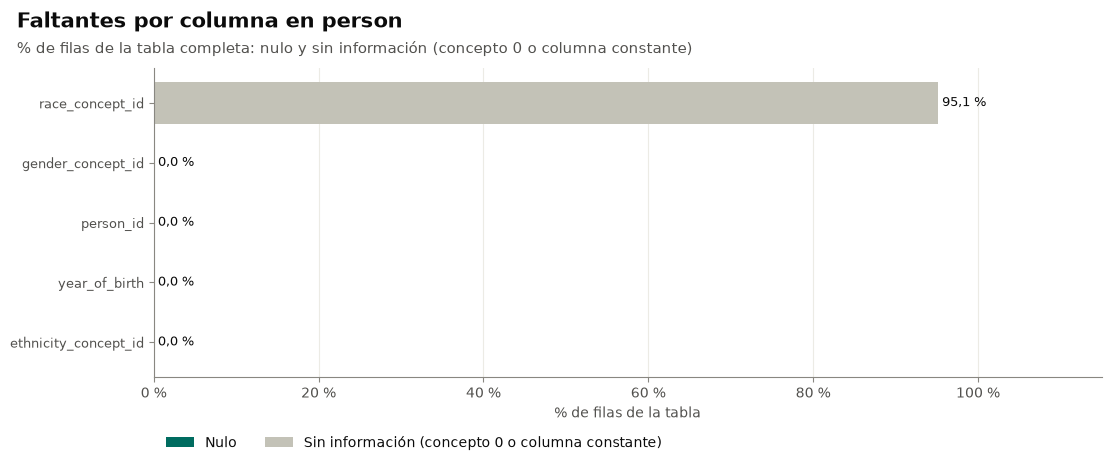

In [5]:
ver_faltantes('person')

### 1.1 Descripción: diccionario frente a columnas reales

In [6]:
mostrar_tabla(suprimir_pequenos(comparar_columnas(columnas_reales, 'person'), []), 'Diccionario frente a columnas reales de person')

**Diccionario frente a columnas reales de person**

,tipo_dato,estado
columna,,
person_id,integer,existe
gender_concept_id,integer,existe
year_of_birth,integer,existe
race_concept_id,integer,existe
ethnicity_concept_id,integer,existe


### 1.2 Calidad

Chequeos de valores extremos de `year_of_birth` y de conceptos 0, y rango de los años. Los nulos y valores distintos por columna están en `info()`.

In [7]:
calidad_person = mostrar_calidad('01t_person_calidad', 'person')

**Chequeos de calidad de person**

,n,n_casos,pct_casos
chequeo,,,
id_paciente_repetido,912205,0,0.00
anio_nacimiento_igual_a_1,912205,85,0.01
anio_nacimiento_antes_de_1900,912205,87,0.01
anio_nacimiento_futuro,912205,0,0.00
sexo_concepto_0,912205,129,0.01
raza_concepto_0,912205,867831,95.14
etnia_concepto_0,912205,0,0.00


**Rango de valores de person**

,valor
medida,
anio_nacimiento_minimo_valido,1901
anio_nacimiento_maximo,2026


### 1.3 Univariado

Año de nacimiento con una caja por sexo, y sexo, raza y etnia.

**Personas con año de nacimiento anterior a 1900**

,n_personas
anio_nacimiento,
1,85
1893,<10
1898,<10


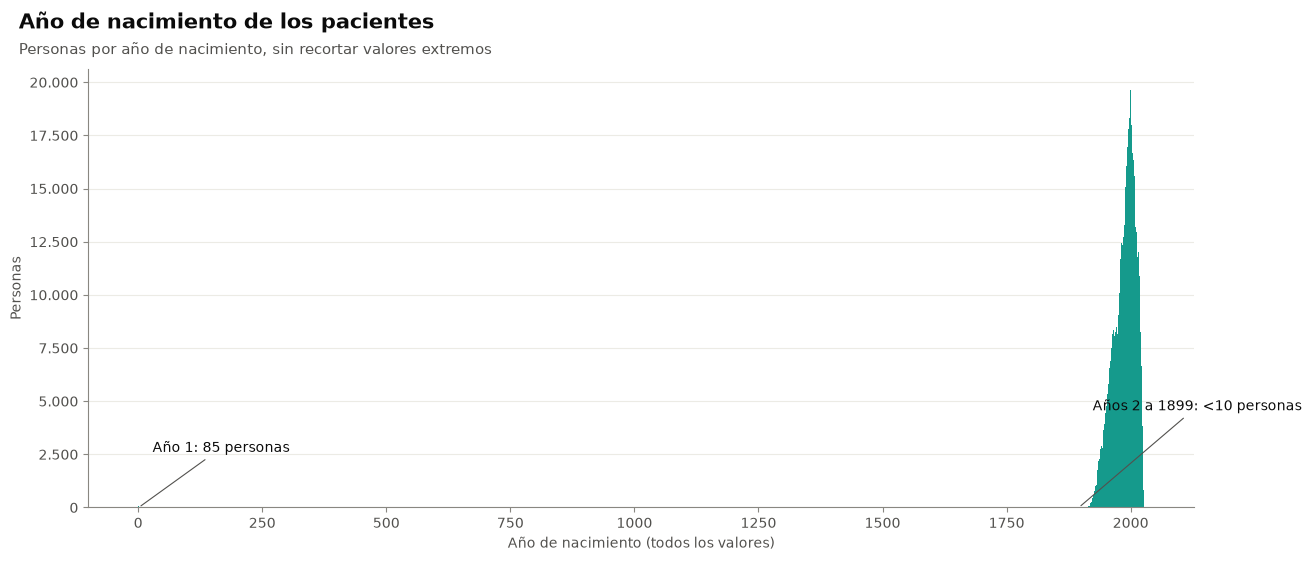

In [8]:
anio_sexo = consultar('01t_person_anio_sexo')
anio_sexo['sexo'] = anio_sexo['sexo'].map(nombre_sexo)
por_anio = anio_sexo.groupby('anio_nacimiento')['n_personas'].sum()
mostrar_tabla(suprimir_pequenos(por_anio[por_anio.index < 1900].rename('n_personas').to_frame(), ['n_personas']), 'Personas con año de nacimiento anterior a 1900')
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(por_anio.index, enmascarar_pequenos(por_anio, por_anio), width=1.0, color=VERDE, linewidth=0)
extremos = [
    ('Año 1', por_anio[por_anio.index == 1]),
    ('Años 2 a 1899', por_anio[(por_anio.index > 1) & (por_anio.index < 1900)]),
]
for i, (texto, parte) in enumerate(extremos):
    if parte.empty:
        continue
    x = float(np.median(parte.index))
    ax.annotate(f'{texto}: {conteo_seguro(parte.sum())} personas', xy=(x, 0), xytext=(10, 40 + 30 * i),
                textcoords='offset points', ha='left', fontsize=estilo.TAMANO_EJES, color=estilo.TEXTO,
                arrowprops={'arrowstyle': '-', 'color': TEXTO_SECUNDARIO, 'linewidth': 0.8})
formato_eje_anios(ax.xaxis)
ax.set_xlabel('Año de nacimiento (todos los valores)')
ax.set_ylabel('Personas')
titulo_hallazgo(fig, 'Año de nacimiento de los pacientes', 'Personas por año de nacimiento, sin recortar valores extremos')
guardar_figura(fig, '01_person_anio_nacimiento')
plt.show()

**Estadísticos de caja: año de nacimiento por sexo**

,n,q1,mediana,q3,whislo,whishi,minimo,maximo,n_atipicos
sexo,,,,,,,,,
Femenino,484053.0,1971.0,1990.0,2003.0,1923.0,2026.0,1.0,2026.0,1010.0
Masculino,428023.0,1975.0,1994.0,2007.0,1927.0,2026.0,1.0,2026.0,1514.0


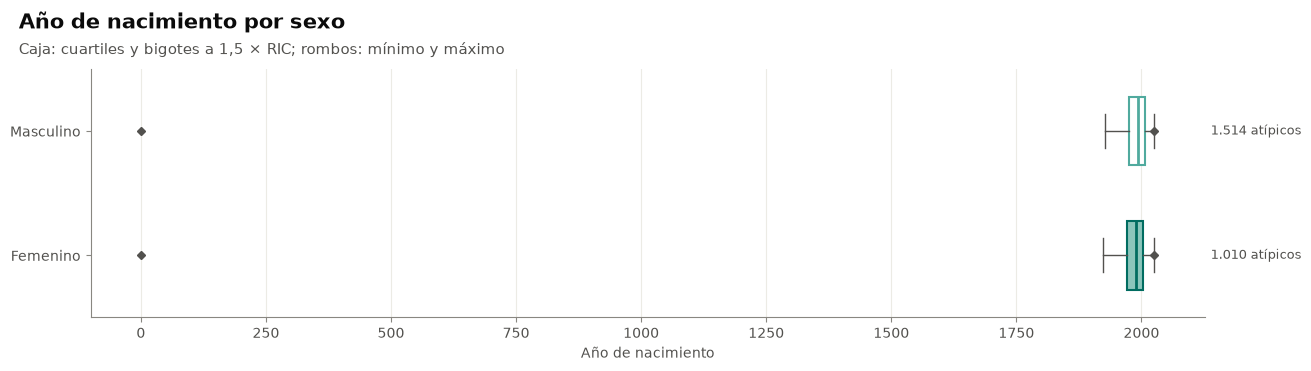

In [9]:
cajas, etiquetas = cajas_desde_frecuencias(anio_sexo, 'sexo', 'anio_nacimiento', 'n_personas', SEXOS)
mostrar_tabla(tabla_cajas(cajas, etiquetas, 'sexo'), 'Estadísticos de caja: año de nacimiento por sexo')
fig, ax = plt.subplots(figsize=(13, 3.6))
dibujar_cajas(ax, cajas, etiquetas, 'general', bordes=[COLOR_SEXO[s] for s in etiquetas],
              anillos=[not RELLENO_SEXO[s] for s in etiquetas])
formato_eje_anios(ax.xaxis)
ax.set_xlabel('Año de nacimiento')
titulo_hallazgo(fig, 'Año de nacimiento por sexo', 'Caja: cuartiles y bigotes a 1,5 × RIC; rombos: mínimo y máximo')
guardar_figura(fig, '01_person_anio_caja_sexo')
plt.show()

**Sexo, raza y etnia de los pacientes**

n_personas  pct_personas
variable concepto nombre_es                                         
etnia    38003563 Hispana o latina              910140         99.77
         38003564 No hispana ni latina            2065          0.23
raza     0        Sin dato                      867831         95.14
         8657     Indígena americana             27704          3.04
         8516     Negra o afrodescendiente       16670          1.83
sexo     8532     Femenino                      484053         53.06
         8507     Masculino                     428023         46.92
         0        Sin dato                         129          0.01

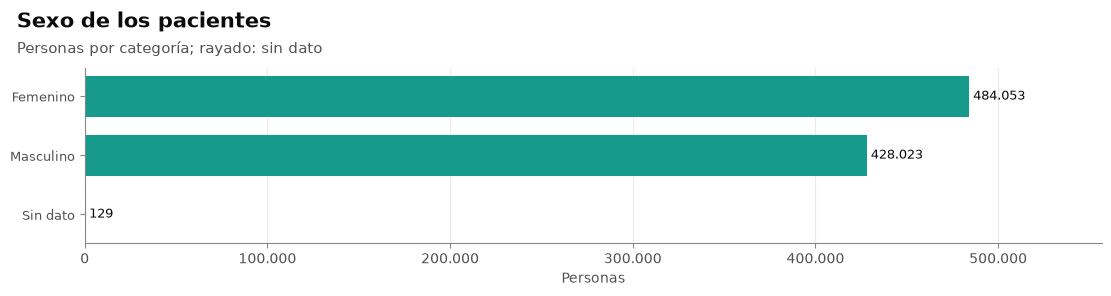

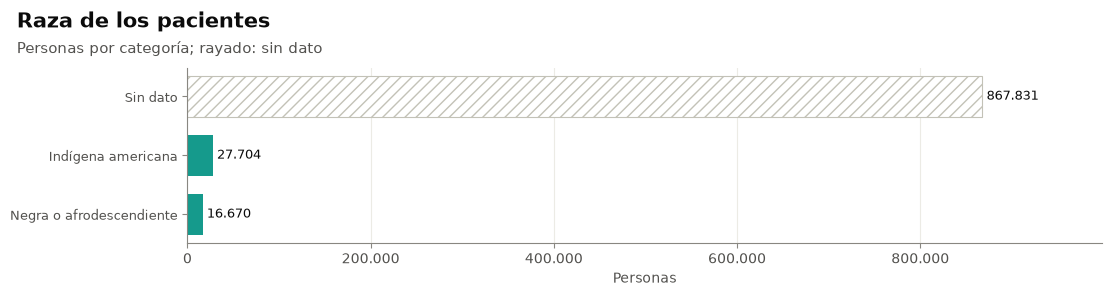

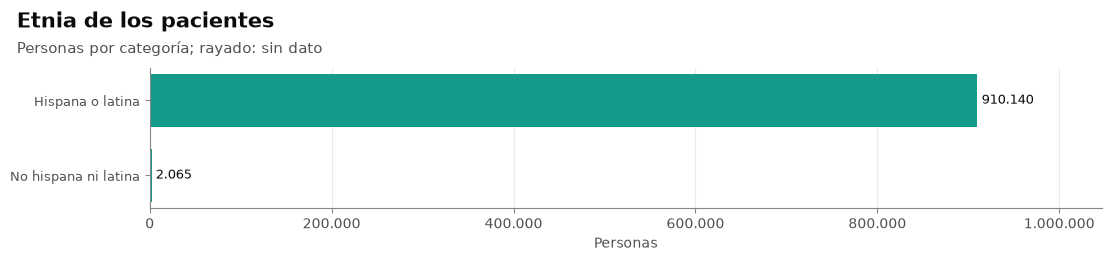

In [10]:
conceptos_person = consultar('01t_person_conceptos')
conceptos_person['nombre_es'] = conceptos_person['nombre'].map(nombre_raza_etnia)
conceptos_person.loc[conceptos_person['variable'] == 'sexo', 'nombre_es'] = (
    conceptos_person.loc[conceptos_person['variable'] == 'sexo', 'nombre'].map(nombre_sexo)
)
tabla_conceptos = conceptos_person.set_index(['variable', 'concepto', 'nombre_es']).drop(columns='nombre')
mostrar_tabla(tabla_segura(agregar_porcentaje(tabla_conceptos, 'n_personas', por='variable')), 'Sexo, raza y etnia de los pacientes')
for variable, titulo in [('sexo', 'Sexo'), ('raza', 'Raza'), ('etnia', 'Etnia')]:
    serie = conceptos_person[conceptos_person['variable'] == variable].groupby('nombre_es')['n_personas'].sum()
    serie = enmascarar_pequenos(serie, serie)
    fig, ax = figura_top(min(len(serie), 13), ancho=11)
    barras_top_n(ax, serie, color=VERDE, n=12, otros=True, sin_dato=ETIQUETAS_SIN_DATO)
    ax.set_xlabel('Personas')
    titulo_hallazgo(fig, f'{titulo} de los pacientes', 'Personas por categoría; rayado: sin dato')
    guardar_figura(fig, f'01_person_{variable}')
    plt.show()

### 1.4 Bivariado

1. Año de nacimiento × sexo.
2. Edad **al llegar a urgencias** × sexo. La edad es el año de la visita menos el año de nacimiento, para **todas** las visitas de urgencias.

**Personas por año de nacimiento y sexo**

sexo,Femenino,Masculino
anio_nacimiento,,
1,<10,<10
1893,<10,<10
1898,<10,<10
1901,<10,<10
1903,<10,<10
...,...,...
2022,3124,3529
2023,2419,2769
2024,1841,2012


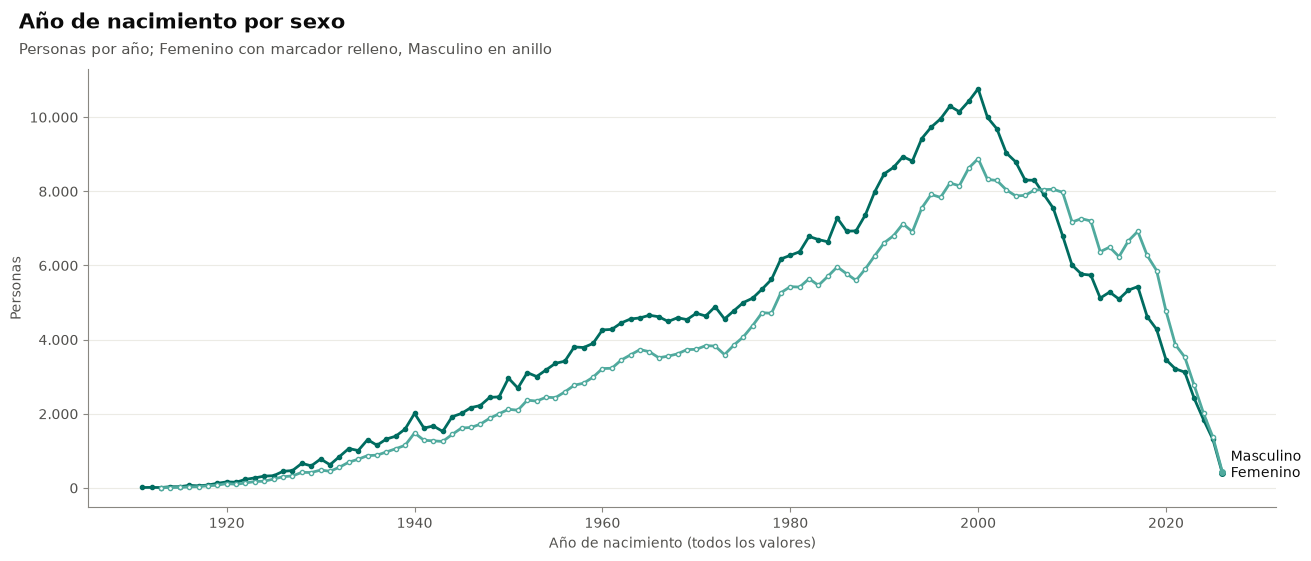

In [11]:
por_anio_sexo = anio_sexo[anio_sexo['sexo'].isin(SEXOS)].pivot_table(
    index='anio_nacimiento', columns='sexo', values='n_personas', aggfunc='sum', fill_value=0)
mostrar_tabla(suprimir_pequenos(por_anio_sexo, list(por_anio_sexo.columns)), 'Personas por año de nacimiento y sexo')
fig, ax = plt.subplots(figsize=(13, 5.5))
series = {}
for sexo in SEXOS:
    if sexo in por_anio_sexo.columns:
        valores = enmascarar_pequenos(por_anio_sexo[sexo], por_anio_sexo[sexo])
        ax.plot(valores.index, valores, color=COLOR_SEXO[sexo], marker='o', markersize=3,
                markerfacecolor=COLOR_SEXO[sexo] if RELLENO_SEXO[sexo] else FONDO)
        series[sexo] = (valores, COLOR_SEXO[sexo])
for sexo, (valores, color) in series.items():
    etiquetas_directas(ax, valores.index, {sexo: (valores, color)})
formato_eje_anios(ax.xaxis)
ax.set_xlabel('Año de nacimiento (todos los valores)')
ax.set_ylabel('Personas')
titulo_hallazgo(fig, 'Año de nacimiento por sexo', 'Personas por año; Femenino con marcador relleno, Masculino en anillo')
guardar_figura(fig, '01_person_anio_por_sexo')
plt.show()

**Visitas de urgencias según la edad al llegar**

,n_visitas,pct_visitas
edad_al_llegar,,
sin dato,0,0.0
negativa,<10,suprimido
0 a 110,598064,100.0
mayor a 110,23,0.0


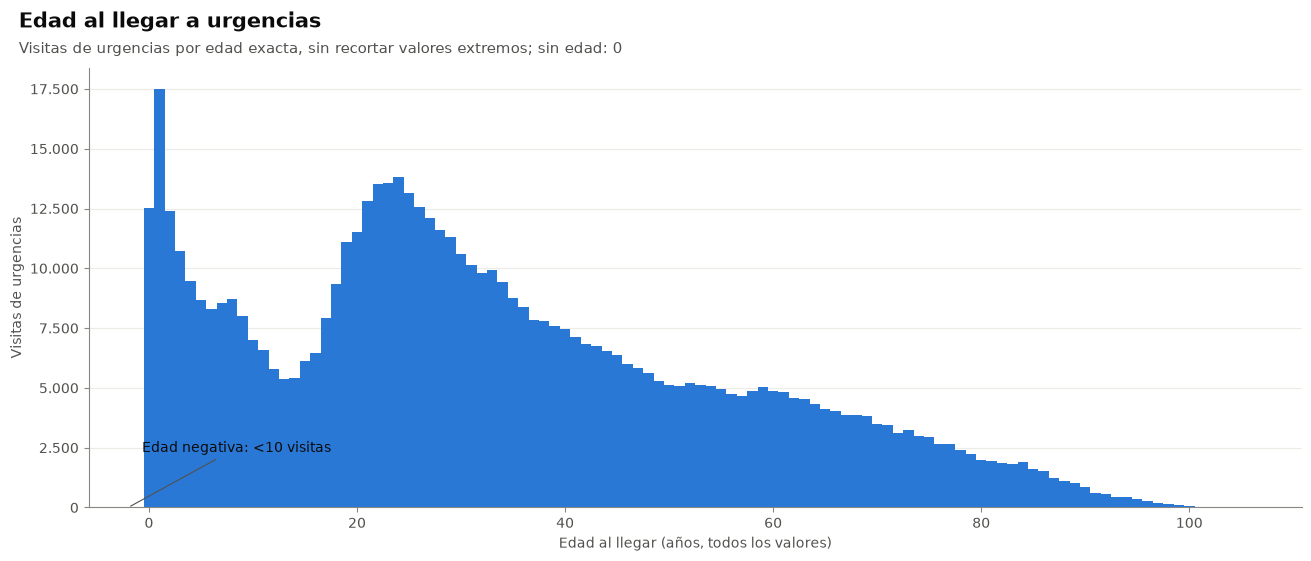

In [12]:
edad_sexo = consultar('01t_person_edad_llegada_sexo')
edad_sexo['sexo'] = edad_sexo['sexo'].map(nombre_sexo)
total_visitas_urg = edad_sexo['n_visitas'].sum()
categorias_edad = pd.Series({
    'sin dato': edad_sexo.loc[edad_sexo['edad'].isna(), 'n_visitas'].sum(),
    'negativa': edad_sexo.loc[edad_sexo['edad'] < 0, 'n_visitas'].sum(),
    '0 a 110': edad_sexo.loc[edad_sexo['edad'].between(0, 110), 'n_visitas'].sum(),
    'mayor a 110': edad_sexo.loc[edad_sexo['edad'] > 110, 'n_visitas'].sum(),
}, name='n_visitas').rename_axis('edad_al_llegar').to_frame()
mostrar_tabla(tabla_segura(agregar_porcentaje(categorias_edad, 'n_visitas'), conservar_ceros=True), 'Visitas de urgencias según la edad al llegar')
por_edad = edad_sexo.dropna(subset=['edad']).groupby('edad')['n_visitas'].sum()
fig, ax = plt.subplots(figsize=(13, 5.5))
ax.bar(por_edad.index, enmascarar_pequenos(por_edad, por_edad), width=1.0, color=AZUL, linewidth=0)
for i, (texto, mascara) in enumerate([('Edad negativa', por_edad.index < 0), ('Edad mayor a 110', por_edad.index > 110)]):
    parte = por_edad[mascara]
    if parte.empty:
        continue
    ax.annotate(f'{texto}: {conteo_seguro(parte.sum())} visitas', xy=(float(np.median(parte.index)), 0),
                xytext=(10, 40 + 30 * i), textcoords='offset points', fontsize=estilo.TAMANO_EJES, color=estilo.TEXTO,
                arrowprops={'arrowstyle': '-', 'color': TEXTO_SECUNDARIO, 'linewidth': 0.8})
ax.set_xlabel('Edad al llegar (años, todos los valores)')
ax.set_ylabel('Visitas de urgencias')
titulo_hallazgo(fig, 'Edad al llegar a urgencias', f"Visitas de urgencias por edad exacta, sin recortar valores extremos; sin edad: {conteo_seguro(categorias_edad.loc['sin dato', 'n_visitas'])}")
guardar_figura(fig, '01_urgencias_edad')
plt.show()

**Estadísticos de caja: edad al llegar a urgencias por sexo**

,n,q1,mediana,q3,whislo,whishi,minimo,maximo,n_atipicos
sexo,,,,,,,,,
Femenino,333411.0,19.0,30.0,49.0,-2.0,94.0,-2.0,2023.0,811.0
Masculino,264549.0,12.0,28.0,48.0,0.0,102.0,0.0,2022.0,26.0


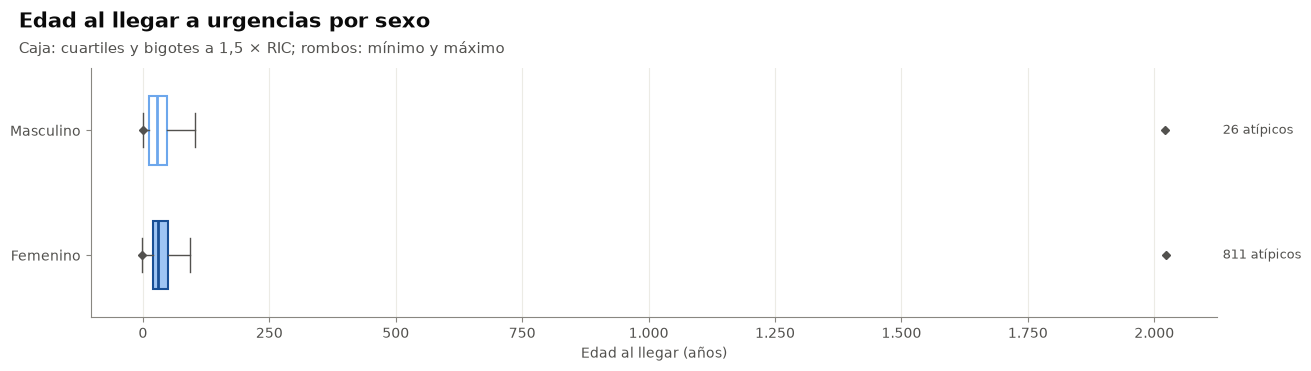

**Visitas de urgencias por tramo de 5 años de edad y sexo**

sexo,Femenino,Masculino
tramo_5,,
-5,<10,<10
0,29119,33463
5,19079,23131
10,14092,16048
15,24566,16392
20,40003,25240
25,37021,23686
30,29256,20620
35,23634,16710


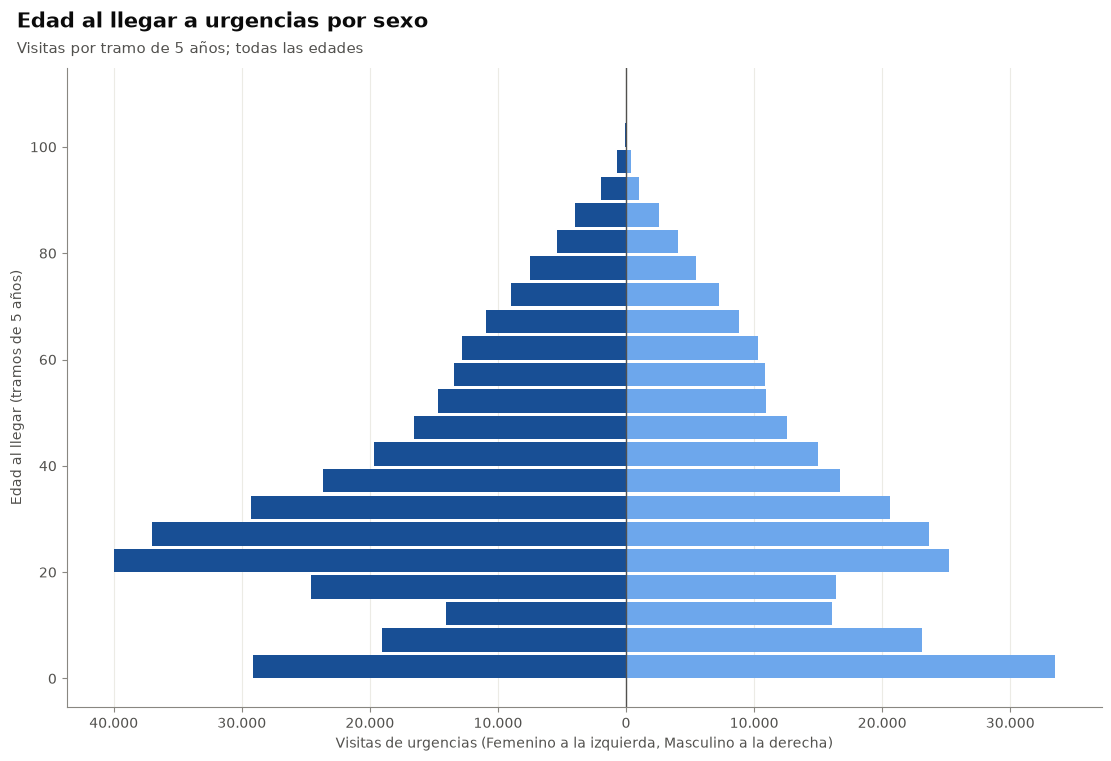

In [13]:
cajas, etiquetas = cajas_desde_frecuencias(edad_sexo.dropna(subset=['edad']), 'sexo', 'edad', 'n_visitas', SEXOS)
mostrar_tabla(tabla_cajas(cajas, etiquetas, 'sexo'), 'Estadísticos de caja: edad al llegar a urgencias por sexo')
fig, ax = plt.subplots(figsize=(13, 3.6))
dibujar_cajas(ax, cajas, etiquetas, 'urgencias', bordes=[COLOR_SEXO_URG[s] for s in etiquetas],
              anillos=[not RELLENO_SEXO[s] for s in etiquetas])
ax.set_xlabel('Edad al llegar (años)')
titulo_hallazgo(fig, 'Edad al llegar a urgencias por sexo', 'Caja: cuartiles y bigotes a 1,5 × RIC; rombos: mínimo y máximo')
guardar_figura(fig, '01_urgencias_edad_caja_sexo')
plt.show()

# Pirámide en tramos de 5 años calculados aquí (incluye los tramos negativos o mayores a 110 si existen).
edad_sexo['tramo_5'] = (edad_sexo['edad'] // 5 * 5)
piramide = edad_sexo[edad_sexo['sexo'].isin(SEXOS)].dropna(subset=['tramo_5']).pivot_table(
    index='tramo_5', columns='sexo', values='n_visitas', aggfunc='sum', fill_value=0)
piramide.index = piramide.index.astype(int)
mostrar_tabla(suprimir_pequenos(piramide, list(piramide.columns)), 'Visitas de urgencias por tramo de 5 años de edad y sexo')
fig, ax = plt.subplots(figsize=(11, max(6, 0.22 * len(piramide) + 2)))
for sexo, signo in [('Femenino', -1), ('Masculino', 1)]:
    if sexo in piramide.columns:
        valores = enmascarar_pequenos(piramide[sexo], piramide[sexo])
        ax.barh(piramide.index, signo * valores, height=4.4, align='edge', label=sexo, color=COLOR_SEXO_URG[sexo])
ax.axvline(0, color=TEXTO_SECUNDARIO, linewidth=1)
ax.xaxis.set_major_formatter(FuncFormatter(lambda x, _pos: fmt_entero(abs(x))))
ax.grid(False)
ax.grid(axis='x')
ax.set_xlabel('Visitas de urgencias (Femenino a la izquierda, Masculino a la derecha)')
ax.set_ylabel('Edad al llegar (tramos de 5 años)')
titulo_hallazgo(fig, 'Edad al llegar a urgencias por sexo', 'Visitas por tramo de 5 años; todas las edades')
guardar_figura(fig, '01_urgencias_piramide')
plt.show()

### 1.5 Observaciones

In [14]:
n_personas = calidad_person['n_filas']
raza = conceptos_person[conceptos_person['variable'] == 'raza']
etnia = conceptos_person[conceptos_person['variable'] == 'etnia']
etnia_principal = etnia.sort_values('n_personas', ascending=False).iloc[0]
observar('person', [
    ('year_of_birth', 'personas con año de nacimiento igual a 1', calidad_person['chequeo__anio_nacimiento_igual_a_1'], n_personas),
    ('year_of_birth', 'personas con año de nacimiento anterior a 1900', calidad_person['chequeo__anio_nacimiento_antes_de_1900'], n_personas),
    ('year_of_birth', 'personas con año de nacimiento futuro', calidad_person['chequeo__anio_nacimiento_futuro'], n_personas),
    ('race_concept_id', 'personas con raza sin información (concepto 0 o sin traducción)',
     raza.loc[raza['nombre_es'] == 'Sin dato', 'n_personas'].sum(), n_personas),
    ('ethnicity_concept_id', f'personas en la etnia más frecuente ({etnia_principal["nombre_es"]})',
     etnia_principal['n_personas'], n_personas),
    ('gender_concept_id', 'personas con sexo sin información', calidad_person['chequeo__sexo_concepto_0'], n_personas),
    ('edad al llegar', 'visitas de urgencias con edad negativa', categorias_edad.loc['negativa', 'n_visitas'], total_visitas_urg),
    ('edad al llegar', 'visitas de urgencias con edad mayor a 110', categorias_edad.loc['mayor a 110', 'n_visitas'], total_visitas_urg),
])

**Observaciones de person**

,columna,hallazgo,magnitud
0,year_of_birth,personas con año de nacimiento igual a 1,"0,0 % (85 de 912.205)"
1,year_of_birth,personas con año de nacimiento anterior a 1900,"0,0 % (87 de 912.205)"
2,year_of_birth,personas con año de nacimiento futuro,0 casos
3,race_concept_id,personas con raza sin información (concepto 0 o sin trad...,"95,1 % (867.831 de 912.205)"
4,ethnicity_concept_id,personas en la etnia más frecuente (Hispana o latina),"99,8 % (910.140 de 912.205)"
5,gender_concept_id,personas con sexo sin información,"0,0 % (129 de 912.205)"
6,edad al llegar,visitas de urgencias con edad negativa,<10 casos
7,edad al llegar,visitas de urgencias con edad mayor a 110,"0,0 % (23 de 598.088)"


## 2. `visit_occurrence`

### Ficha del dataset

In [15]:
ver_head('visit_occurrence')

**head(): primeras 5 filas de visit_occurrence, ordenadas por visit_occurrence_id**

,visit_occurrence_id,person_id,visit_concept_id,visit_start_datetime,visit_end_datetime,provider_id
0,128513,81081,581479,2026-04-17 14:00:00,2026-04-17 14:00:00,0
1,139799,81081,581479,2026-04-17 14:00:00,2026-04-17 14:00:00,0
2,656644,228854,9203,2023-01-05 08:41:13,2023-01-05 08:41:13,0
3,656645,503734,581479,2023-01-05 08:41:57,2023-01-05 08:41:57,0
4,656957,373829,581479,2023-01-02 13:30:00,2023-01-02 13:30:00,0


In [16]:
ver_info('visit_occurrence')

**info(): visit_occurrence · 1.706.001 filas × 6 columnas**

,columna,tipo de dato,no nulos,nulos,% nulos,valores distintos
0,visit_occurrence_id,integer,1706001,0,0.0,1706001
1,person_id,integer,1706001,0,0.0,304457
2,visit_concept_id,integer,1706001,0,0.0,5
3,visit_start_datetime,timestamp without time zone,1706001,0,0.0,420853
4,visit_end_datetime,timestamp without time zone,1706001,0,0.0,420853
5,provider_id,integer,1706001,0,0.0,1


In [17]:
ver_describe('visit_occurrence')

**describe(): columnas numéricas y fechas de visit_occurrence (sin columnas de ID)**

,visit_start_datetime,visit_end_datetime
estadístico,,
count,1.706.001,1.706.001
min,2023-01-01 00:21:55,2023-01-01 00:21:55
25%,2023-11-14 08:24:34,2023-11-14 08:24:34
50%,2024-10-03 07:39:48,2024-10-03 07:39:48
75%,2025-08-14 12:20:00,2025-08-14 12:20:00
max,2026-08-13 15:20:00,2026-08-13 15:20:00


**describe(): columnas categóricas de visit_occurrence (top traducido con concept)**

columna,visit_concept_id
estadístico,
count,1.706.001
unique,<10
top,Ambulatory Rehabilitation Visit (581479)
freq,1.089.461


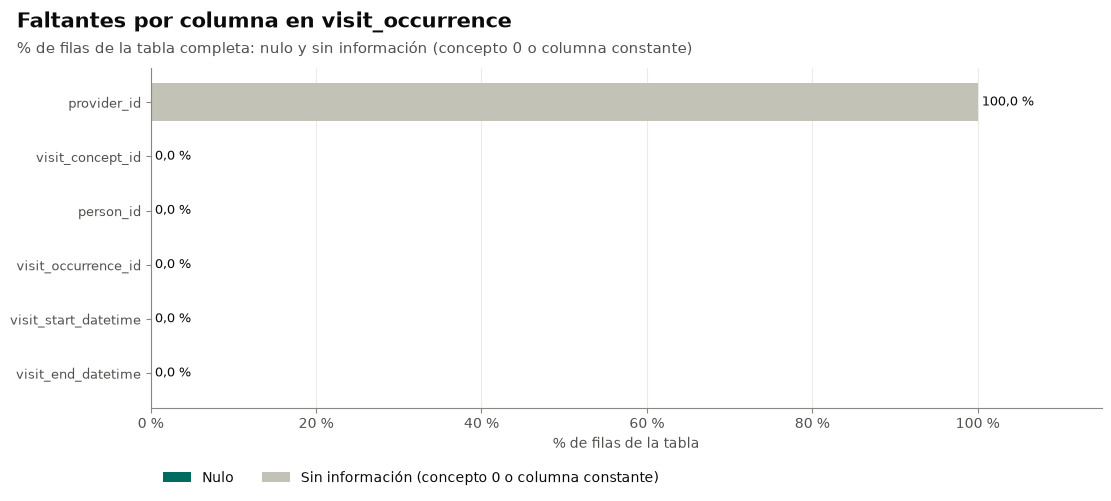

In [18]:
ver_faltantes('visit_occurrence')

### 2.1 Descripción: diccionario frente a columnas reales

In [19]:
mostrar_tabla(suprimir_pequenos(comparar_columnas(columnas_reales, 'visit_occurrence'), []), 'Diccionario frente a columnas reales de visit_occurrence')

**Diccionario frente a columnas reales de visit_occurrence**

,tipo_dato,estado
columna,,
visit_occurrence_id,integer,existe
person_id,integer,existe
visit_concept_id,integer,existe
visit_start_datetime,timestamp without time zone,existe
visit_end_datetime,timestamp without time zone,existe
provider_id,integer,existe
visit_type_concept_id,—,falta en la base
preceding_visit_occurrence_id,—,falta en la base


### 2.2 Calidad

Chequeos: visitas con fin igual o anterior al inicio y visitas que empiezan exactamente a medianoche. Los valores distintos de `provider_id` están en `info()`.

In [20]:
calidad_visit = mostrar_calidad('01t_visit_calidad', 'visit_occurrence')
duracion_visitas = consultar('01_duracion_visitas')
duracion_visitas['tipo_visita'] = [nombre_tipo_visita(c, n) for c, n in zip(duracion_visitas['concepto_visita'], duracion_visitas['tipo_visita'])]
mostrar_tabla(tabla_segura(duracion_visitas.set_index(['concepto_visita', 'tipo_visita'])), 'Duración registrada de las visitas por tipo de visita (horas)')

**Chequeos de calidad de visit_occurrence**

,n,n_casos,pct_casos
chequeo,,,
id_visita_repetido,1706001,0,0.00
fin_igual_a_inicio,1706001,1706001,100.00
fin_antes_de_inicio,1706001,0,0.00
inicio_a_medianoche,1706001,1136,0.07
paciente_inexistente,1706001,0,0.00


**Rango de valores de visit_occurrence**

,valor
medida,
primer_mes,2023-01-01
ultimo_mes,2026-08-01


**Duración registrada de las visitas por tipo de visita (horas)**

,,n,n_sin_fin,pct_sin_fin,n_negativas,pct_negativas,n_cero,pct_cero,p10_h,p50_h,p90_h,p99_h
concepto_visita,tipo_visita,,,,,,,,,,,
581479,Consulta externa (581479),1089461,<10,suprimido,<10,suprimido,1089461,100.0,0.0,0.0,0.0,0.0
9203,Urgencias (9203),598088,<10,suprimido,<10,suprimido,598088,100.0,0.0,0.0,0.0,0.0
3045729,Tratamiento urgente (3045729),17858,<10,suprimido,<10,suprimido,17858,100.0,0.0,0.0,0.0,0.0
9201,Hospitalización (9201),592,<10,suprimido,<10,suprimido,592,100.0,0.0,0.0,0.0,0.0
0,No matching concept (0),<10,<10,suprimido,<10,suprimido,<10,suprimido,suprimido,suprimido,suprimido,suprimido


### 2.3 Univariado

Tipo de visita, visitas por mes, hora de inicio, día de la semana y visitas por paciente.

**Visitas por tipo de visita**

,,,n_visitas,n_pacientes,pct_visitas
concepto_visita,tipo_visita,vocabulario,,,
581479,Consulta externa (581479),Visit,1089461,158563,63.86
9203,Urgencias (9203),Visit,598088,231083,35.06
3045729,Tratamiento urgente (3045729),LOINC,17858,15319,1.05
9201,Hospitalización (9201),Visit,592,521,0.03
0,No matching concept (0),None,<10,<10,suprimido


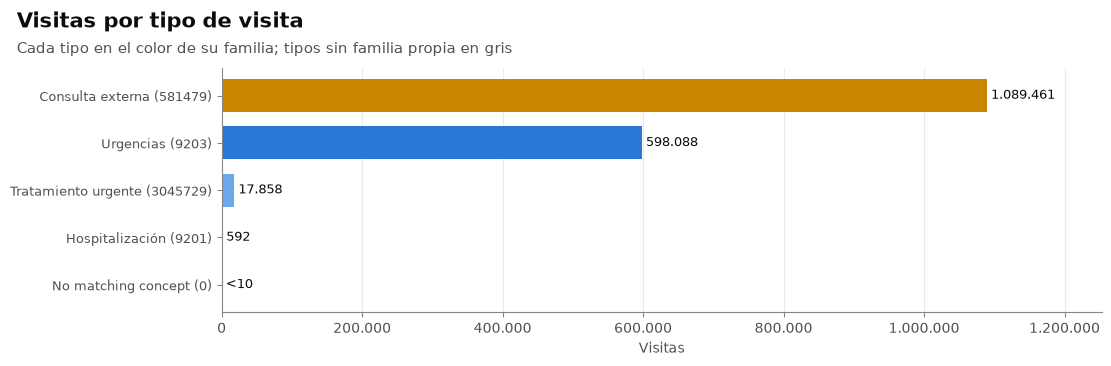

In [21]:
tipos_visita = consultar('01_tipos_visita')
tipos_visita['tipo_visita'] = [nombre_tipo_visita(c, n) for c, n in zip(tipos_visita['concepto_visita'], tipos_visita['tipo_visita'])]
tabla_tipos = tipos_visita.set_index(['concepto_visita', 'tipo_visita', 'vocabulario'])
mostrar_tabla(tabla_segura(agregar_porcentaje(tabla_tipos, 'n_visitas')), 'Visitas por tipo de visita')
serie = tipos_visita.set_index('tipo_visita')['n_visitas']
serie = enmascarar_pequenos(serie, serie).sort_values(ascending=False)
fig, ax = figura_top(min(len(serie), 11))
barras_top_n(ax, serie, color=colores_tipo_visita(serie.index), n=10, otros=True)
ax.set_xlabel('Visitas')
titulo_hallazgo(fig, 'Visitas por tipo de visita', 'Cada tipo en el color de su familia; tipos sin familia propia en gris')
guardar_figura(fig, '01_visit_tipos')
plt.show()

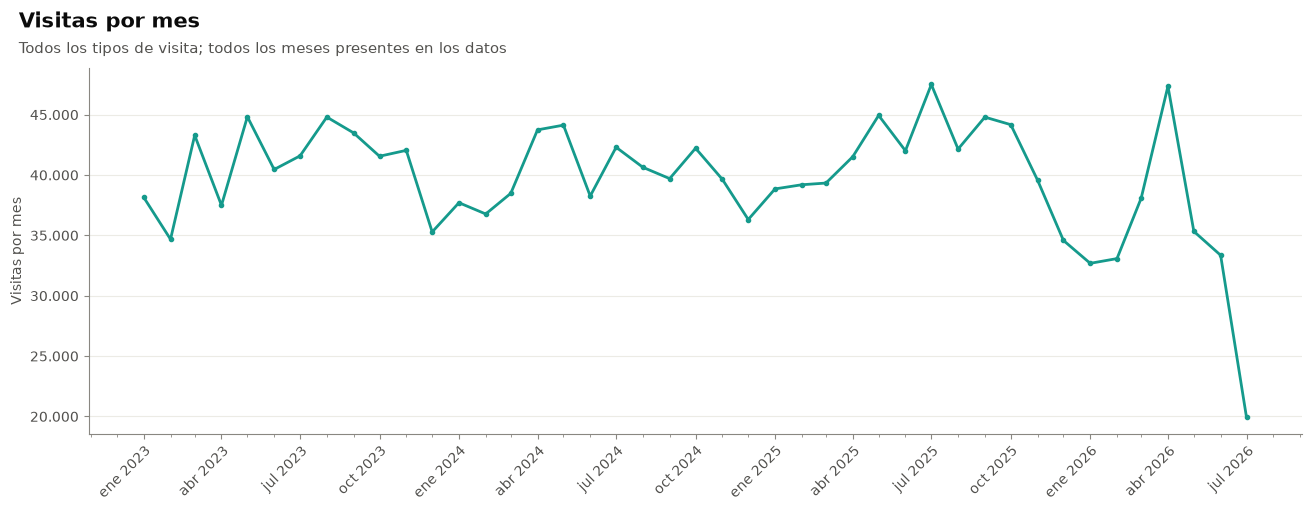

In [22]:
mensual = consultar('01_volumen_mensual')
mensual['mes'] = pd.to_datetime(mensual['mes'])
mensual['tipo_visita'] = [nombre_tipo_visita(c, n) for c, n in zip(mensual['concepto_visita'], mensual['tipo_visita'])]
total_mes = mensual.groupby('mes')['n_visitas'].sum()

fig, ax = plt.subplots(figsize=(13, 5))
serie = enmascarar_pequenos(total_mes, total_mes)
ax.plot(serie.index, serie, marker='o', markersize=3, color=VERDE)
ax.set_ylabel('Visitas por mes')
titulo_hallazgo(fig, 'Visitas por mes', 'Todos los tipos de visita; todos los meses presentes en los datos')
guardar_figura(fig, '01_visit_mensual_total')
plt.show()

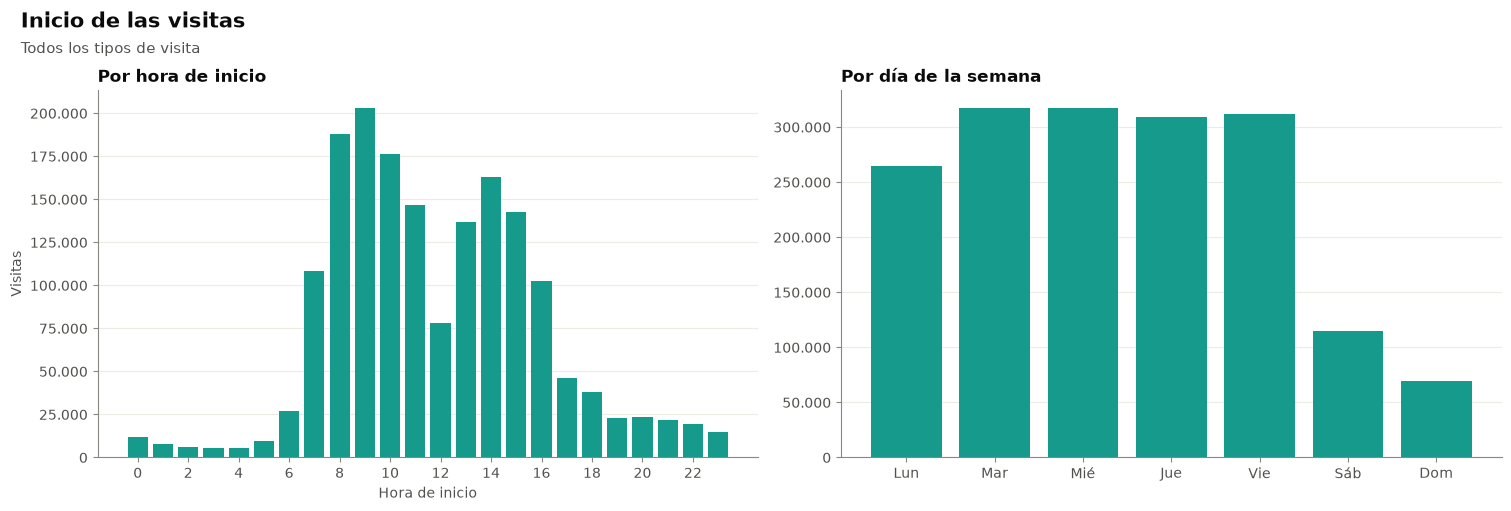

In [23]:
hora_dia_tipo = consultar('01t_visit_hora_dia_tipo')
hora_dia_tipo['tipo_visita'] = [nombre_tipo_visita(c, n) for c, n in zip(hora_dia_tipo['concepto_visita'], hora_dia_tipo['tipo_visita'])]
por_hora_total = hora_dia_tipo.groupby('hora')['n_visitas'].sum()
por_dia_total = hora_dia_tipo.groupby('dia_semana')['n_visitas'].sum()

fig, ejes = plt.subplots(1, 2, figsize=(15, 5))
ejes[0].bar(por_hora_total.index, enmascarar_pequenos(por_hora_total, por_hora_total), color=VERDE)
ejes[0].set_xticks(range(0, 24, 2))
ejes[0].set_xlabel('Hora de inicio')
ejes[0].set_ylabel('Visitas')
ejes[0].set_title('Por hora de inicio')
ejes[1].bar(por_dia_total.index, enmascarar_pequenos(por_dia_total, por_dia_total), color=VERDE)
ejes[1].set_xticks(range(7), DIAS_SEMANA)
ejes[1].set_title('Por día de la semana')
titulo_hallazgo(fig, 'Inicio de las visitas', 'Todos los tipos de visita')
guardar_figura(fig, '01_visit_hora_dia')
plt.show()

**Visitas por paciente**

n_pacientes  n_visitas  pct_pacientes  pct_visitas
alcance   visitas_por_paciente                                                    
todas     1                           51293    51293.0          16.85         3.01
          2                           89301   178602.0          29.33        10.47
          3                           39354   118062.0          12.93         6.92
          4-5                         49232   214309.0          16.17        12.56
          6-9                         38098   269802.0          12.51        15.81
          10+                         37179   873933.0          12.21        51.23
urgencias 1                           81868    81868.0          35.43        13.69
          2                           76503   153006.0          33.11        25.58
          3                           26494    79482.0          11.47        13.29
          4-5                         27018   116148.0          11.69        19.42
          6-9                         14260    98481.0           6.17        16.47
          10+                          4940    69103.0           2.14        11.55

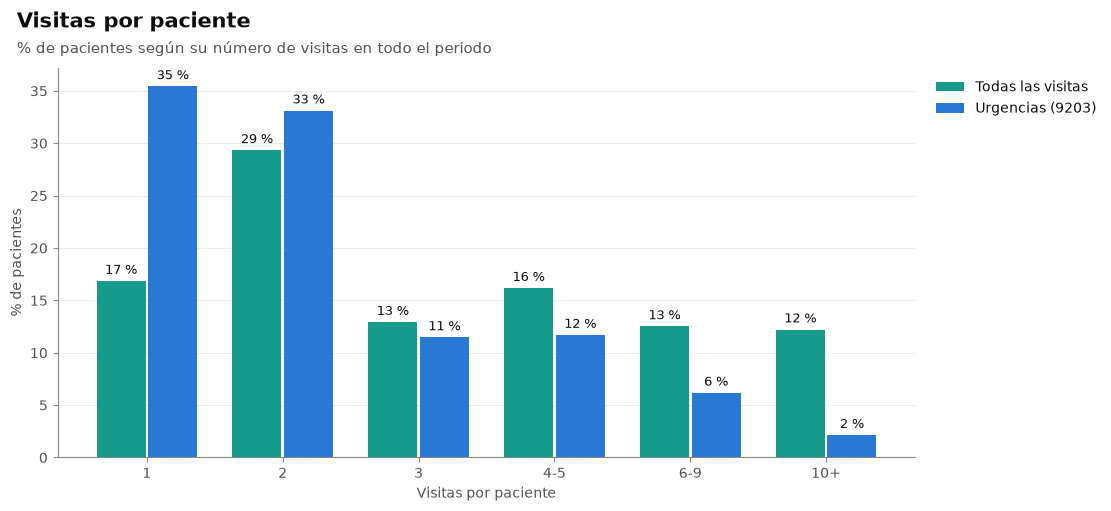

In [24]:
por_paciente = consultar('01t_visit_visitas_por_paciente')
por_paciente['visitas_por_paciente'] = pd.Categorical(por_paciente['visitas_por_paciente'], categories=ORDEN_CONTEO, ordered=True)
por_paciente = por_paciente.set_index(['alcance', 'visitas_por_paciente']).sort_index()
por_paciente = agregar_porcentaje(por_paciente, 'n_pacientes', por='alcance')
mostrar_tabla(tabla_segura(agregar_porcentaje(por_paciente, 'n_visitas', por='alcance')), 'Visitas por paciente')
fig, ax = plt.subplots(figsize=(11, 5))
x = np.arange(len(ORDEN_CONTEO) - 1)  # la categoría 0 no existe en esta consulta
for j, (alcance, color, texto) in enumerate([('todas', VERDE, 'Todas las visitas'), ('urgencias', AZUL, 'Urgencias (9203)')]):
    datos = por_paciente.xs(alcance, level='alcance').reindex(ORDEN_CONTEO[1:])
    valores = datos['pct_pacientes'].where(datos['n_pacientes'] >= config.MIN_CELDA)
    barras = ax.bar(x + (j - 0.5) * 0.38, valores, width=0.36, color=color, label=texto)
    rotular_barras(ax, barras, valores, formato=lambda v: fmt_pct(v, 0))
ax.set_xticks(x, ORDEN_CONTEO[1:])
ax.set_xlabel('Visitas por paciente')
ax.set_ylabel('% de pacientes')
leyenda_fuera(ax)
titulo_hallazgo(fig, 'Visitas por paciente', '% de pacientes según su número de visitas en todo el periodo')
guardar_figura(fig, '01_visit_visitas_por_paciente')
plt.show()

### 2.4 Bivariado

1. Tipo de visita × mes.
2. Tipo de visita × hora de inicio y día de la semana.
3. Tipo de visita × visitas sin ninguna etapa (`visit_detail`), en total y por mes.

**Visitas por mes y tipo de visita**

tipo_visita,Consulta externa (581479),Hospitalización (9201),No matching concept (0),Tratamiento urgente (3045729),Urgencias (9203)
mes,,,,,
2023-01-01,21022,<10,<10,392,16734
2023-02-01,19579,<10,<10,294,14802
2023-03-01,25762,<10,<10,270,17256
2023-04-01,21081,<10,<10,342,16066
2023-05-01,26210,10,<10,306,18302
2023-06-01,23624,<10,<10,228,16599
2023-07-01,25010,<10,<10,272,16300
2023-08-01,28344,20,<10,206,16231
2023-09-01,28248,22,<10,152,15068


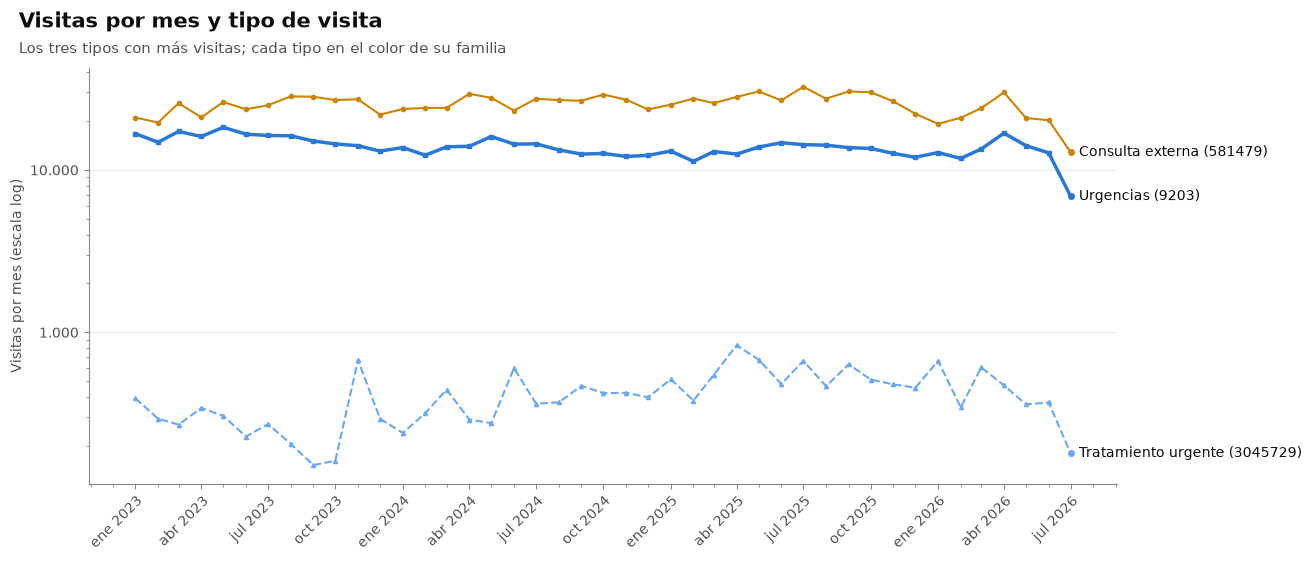

In [25]:
volumen_mensual = mensual.pivot_table(index='mes', columns='tipo_visita', values='n_visitas', aggfunc='sum', fill_value=0)
mostrar_tabla(suprimir_pequenos(volumen_mensual, list(volumen_mensual.columns)), 'Visitas por mes y tipo de visita')
principales = list(volumen_mensual.sum().sort_values(ascending=False).index[:3])
fig, ax = plt.subplots(figsize=(13, 5.5))
series = {}
for i, tipo in enumerate(principales):
    valores = enmascarar_pequenos(volumen_mensual[tipo], volumen_mensual[tipo])
    color = colores_tipo_visita([tipo])[0]
    ax.plot(valores.index, valores, marker=MARCADORES[i], markersize=3, color=color,
            linewidth=2.5 if es_urgencias(tipo) else 1.5, linestyle=linea_tipo_visita(tipo))
    series[tipo] = (valores, color)
etiquetas_directas(ax, volumen_mensual.index, series)
ax.set_yscale('log')
ax.set_ylabel('Visitas por mes (escala log)')
titulo_hallazgo(fig, 'Visitas por mes y tipo de visita', 'Los tres tipos con más visitas; cada tipo en el color de su familia')
guardar_figura(fig, '01_visit_mensual_tipo')
plt.show()

**Visitas por hora de inicio y tipo de visita**

tipo_visita,Consulta externa (581479),Urgencias (9203),Tratamiento urgente (3045729)
hora,,,
0,1248,9627,857
1,86,7025,654
2,70,5800,441
3,60,5238,290
4,54,5125,228
5,500,8682,206
6,8311,18416,286
7,75080,32855,271
8,146024,41461,493


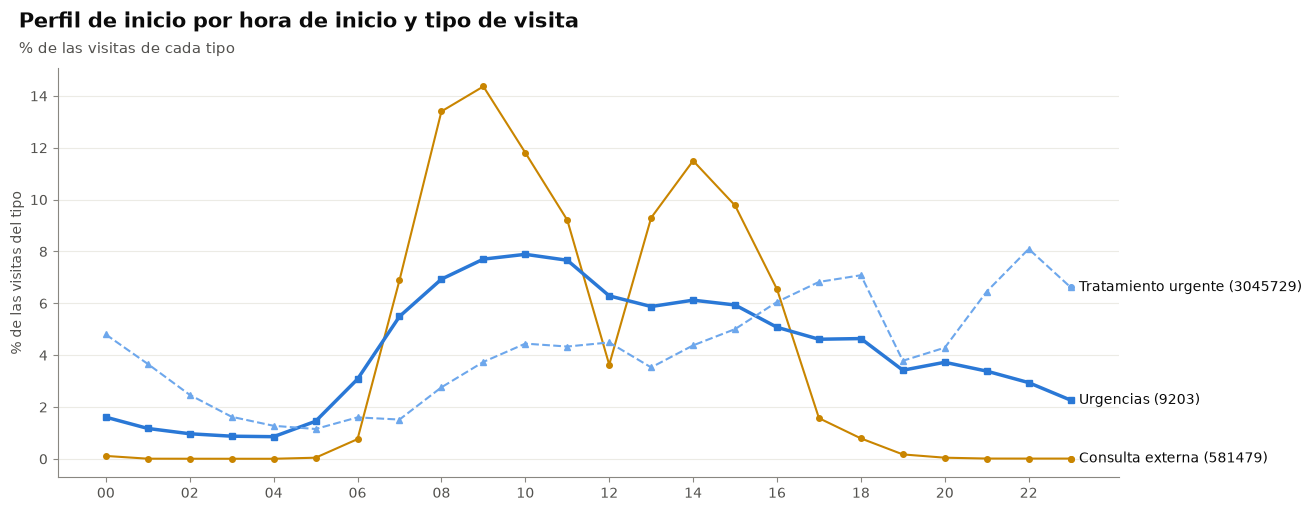

**Visitas por día de la semana y tipo de visita**

tipo_visita,Consulta externa (581479),Urgencias (9203),Tratamiento urgente (3045729)
dia_semana,,,
0,163688,98629,2491
1,219634,95157,2723
2,223838,91021,2712
3,218117,88252,2614
4,223410,86145,2643
5,39901,72412,2584
6,873,66472,2091


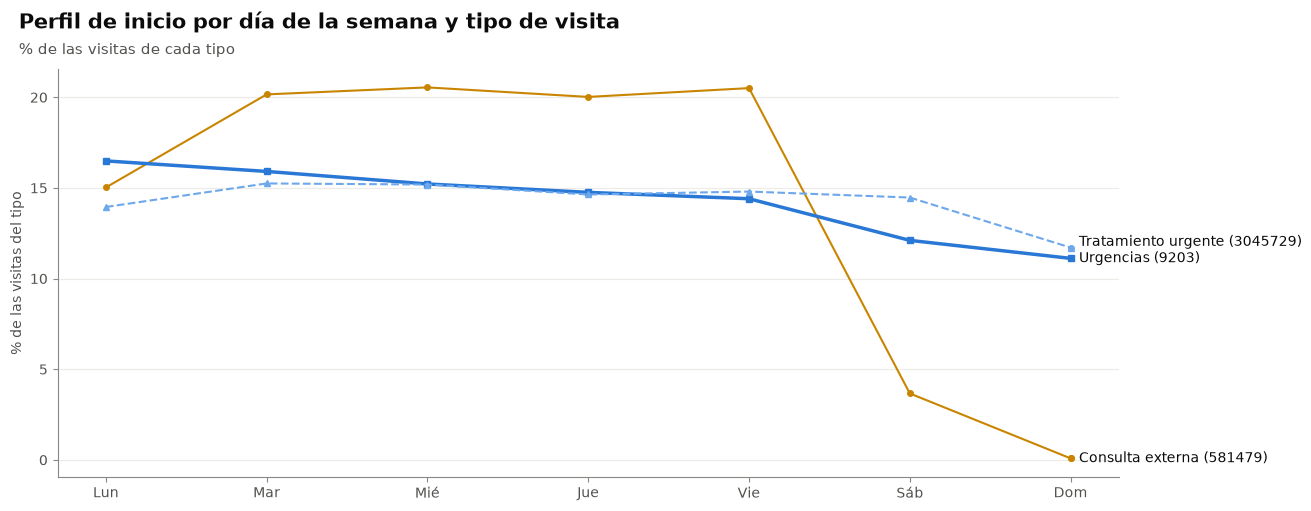

In [26]:
principales = list(hora_dia_tipo.groupby('tipo_visita')['n_visitas'].sum().sort_values(ascending=False).index[:3])
for columna, ticks, etiquetas_x, titulo, nombre in [
    ('hora', range(0, 24, 2), [f'{h:02d}' for h in range(0, 24, 2)], 'hora de inicio', 'hora'),
    ('dia_semana', range(7), DIAS_SEMANA, 'día de la semana', 'dia'),
]:
    conteos = hora_dia_tipo.pivot_table(index=columna, columns='tipo_visita', values='n_visitas', aggfunc='sum',
                                        fill_value=0)[principales]
    mostrar_tabla(suprimir_pequenos(conteos, list(conteos.columns)), f'Visitas por {titulo} y tipo de visita')
    pct = enmascarar_pequenos(100 * conteos / conteos.sum(), conteos)
    fig, ax = plt.subplots(figsize=(13, 5))
    series = {}
    for i, tipo in enumerate(principales):
        color = colores_tipo_visita([tipo])[0]
        ax.plot(pct.index, pct[tipo], marker=MARCADORES[i], markersize=4, color=color,
                linewidth=2.5 if es_urgencias(tipo) else 1.5, linestyle=linea_tipo_visita(tipo))
        series[tipo] = (pct[tipo], color)
    etiquetas_directas(ax, pct.index, series)
    ax.set_xticks(list(ticks), etiquetas_x)
    ax.set_ylabel('% de las visitas del tipo')
    titulo_hallazgo(fig, f'Perfil de inicio por {titulo} y tipo de visita', '% de las visitas de cada tipo')
    guardar_figura(fig, f'01_visit_perfil_{nombre}_tipo')
    plt.show()

**Visitas sin ninguna etapa por tipo de visita**

,n,n_sin_etapas,pct_sin_etapas
tipo_visita,,,
Consulta externa (581479),1089461,29893,2.74
Urgencias (9203),598088,53373,8.92
Tratamiento urgente (3045729),17858,51,0.29
Hospitalización (9201),592,<10,suprimido
No matching concept (0),<10,<10,suprimido


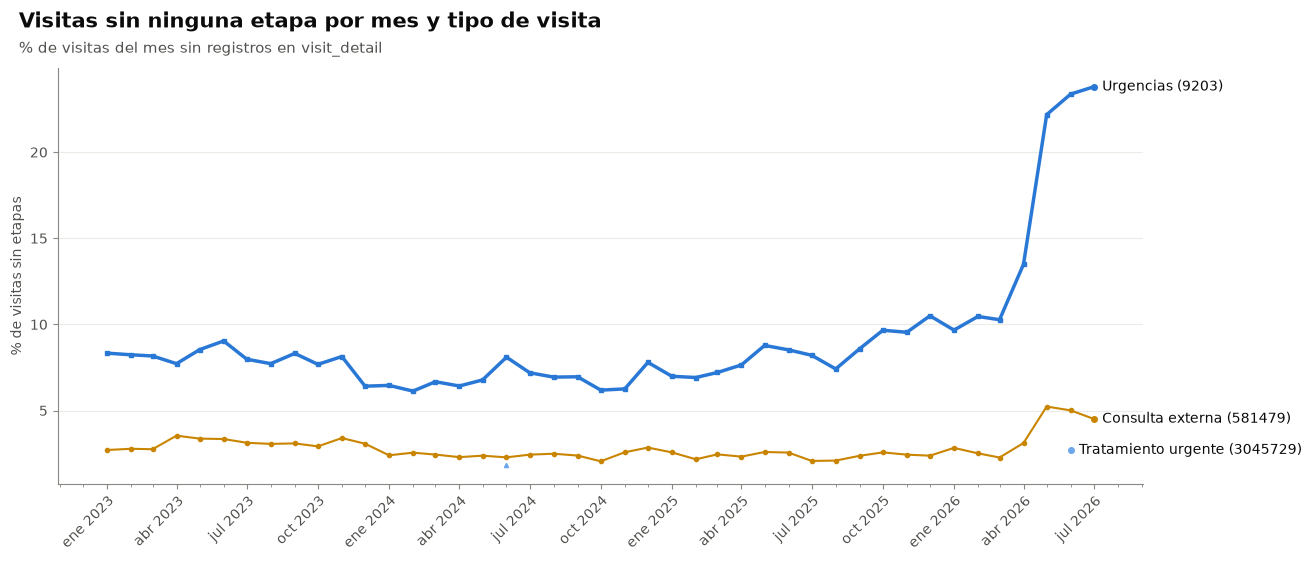

In [27]:
conteos_visita = consultar('01t_conteos_por_visita')
conteos_visita['tipo_visita'] = [nombre_tipo_visita(c, n) for c, n in zip(conteos_visita['concepto_visita'], conteos_visita['tipo_visita'])]
etapas_visita = conteos_visita[conteos_visita['variable'] == 'etapas']
sin_etapas_tipo = etapas_visita.groupby('tipo_visita').apply(
    lambda d: pd.Series({'n': d['n_visitas'].sum(), 'n_sin_etapas': d.loc[d['k'] == 0, 'n_visitas'].sum()}),
    include_groups=False,
)
sin_etapas_tipo['pct_sin_etapas'] = 100 * sin_etapas_tipo['n_sin_etapas'] / sin_etapas_tipo['n']
sin_etapas_tipo = sin_etapas_tipo.sort_values('n', ascending=False)
mostrar_tabla(tabla_segura(sin_etapas_tipo), 'Visitas sin ninguna etapa por tipo de visita')
sin_etapas_mes = consultar('01t_visit_sin_etapas_mes')
sin_etapas_mes['mes'] = pd.to_datetime(sin_etapas_mes['mes'])
sin_etapas_mes['tipo_visita'] = [nombre_tipo_visita(c, n) for c, n in zip(sin_etapas_mes['concepto_visita'], sin_etapas_mes['tipo_visita'])]
principales = list(sin_etapas_tipo.index[:3])
fig, ax = plt.subplots(figsize=(13, 5.5))
series = {}
for i, tipo in enumerate(principales):
    parte = sin_etapas_mes[sin_etapas_mes['tipo_visita'] == tipo].set_index('mes')
    pct = (100 * parte['n_sin_etapas'] / parte['n']).where(parte['n_sin_etapas'] >= config.MIN_CELDA)
    color = colores_tipo_visita([tipo])[0]
    ax.plot(pct.index, pct, marker=MARCADORES[i], markersize=3, color=color, linewidth=2.5 if es_urgencias(tipo) else 1.5, linestyle=linea_tipo_visita(tipo))
    series[tipo] = (pct, color)
for tipo, (pct, color) in series.items():
    etiquetas_directas(ax, pct.index, {tipo: (pct, color)})
ax.set_ylabel('% de visitas sin etapas')
titulo_hallazgo(fig, 'Visitas sin ninguna etapa por mes y tipo de visita', '% de visitas del mes sin registros en visit_detail')
guardar_figura(fig, '01_visit_sin_etapas_mes')
plt.show()

### 2.5 Observaciones

In [28]:
n_visitas = calidad_visit['n_filas']
provider_visit = faltantes[(faltantes['tabla'] == 'visit_occurrence') & (faltantes['columna'] == 'provider_id')].iloc[0]
urg_sin_etapas = sin_etapas_tipo[[es_urgencias(t) for t in sin_etapas_tipo.index]]
items = [
    ('visit_end_datetime', 'visitas con fin igual al inicio', calidad_visit['chequeo__fin_igual_a_inicio'], n_visitas),
    ('visit_end_datetime', 'visitas con fin anterior al inicio', calidad_visit['chequeo__fin_antes_de_inicio'], n_visitas),
    ('provider_id', 'valores distintos', fmt_entero(provider_visit['valores_distintos'])),
    ('visit_start_datetime', 'visitas que empiezan exactamente a medianoche', calidad_visit['chequeo__inicio_a_medianoche'], n_visitas),
    ('visit_start_datetime', 'meses cubiertos',
     f"de {fmt_mes(pd.Timestamp(calidad_visit['rango__primer_mes']))} a {fmt_mes(pd.Timestamp(calidad_visit['rango__ultimo_mes']))}"),
]
if not urg_sin_etapas.empty:
    items.append(('visit_detail (relación)', 'visitas de urgencias sin ninguna etapa',
                  urg_sin_etapas['n_sin_etapas'].iloc[0], urg_sin_etapas['n'].iloc[0]))
observar('visit_occurrence', items)

**Observaciones de visit_occurrence**

,columna,hallazgo,magnitud
0,visit_end_datetime,visitas con fin igual al inicio,"100,0 % (1.706.001 de 1.706.001)"
1,visit_end_datetime,visitas con fin anterior al inicio,0 casos
2,provider_id,valores distintos,1
3,visit_start_datetime,visitas que empiezan exactamente a medianoche,"0,1 % (1.136 de 1.706.001)"
4,visit_start_datetime,meses cubiertos,de ene 2023 a ago 2026
5,visit_detail (relación),visitas de urgencias sin ninguna etapa,"8,9 % (53.373 de 598.088)"


**Interpretación del equipo:** _(completar al revisar los resultados)_

## 3. `visit_detail`

### Ficha del dataset

In [29]:
ver_head('visit_detail')

**head(): primeras 5 filas de visit_detail, ordenadas por visit_detail_id**

,visit_detail_id,visit_occurrence_id,visit_detail_concept_id,visit_detail_start_datetime,visit_detail_end_datetime,provider_id
0,1,1504394,581479,2026-07-17 14:03:22,2026-07-17 14:03:22,0
1,2,3262158,581479,2026-07-17 14:03:22,2026-07-17 14:03:22,0
2,3,3262117,581479,2026-07-17 13:36:36,2026-07-17 13:36:36,0
3,4,1504353,581479,2026-07-17 13:36:36,2026-07-17 13:36:36,0
4,5,1504348,581479,2026-07-17 13:29:37,2026-07-17 13:29:37,0


In [30]:
ver_info('visit_detail')

**info(): visit_detail · 3.281.613 filas × 6 columnas**

,columna,tipo de dato,no nulos,nulos,% nulos,valores distintos
0,visit_detail_id,integer,3281613,0,0.0,3281613
1,visit_occurrence_id,integer,3281613,0,0.0,1622756
2,visit_detail_concept_id,integer,3281613,0,0.0,4
3,visit_detail_start_datetime,timestamp without time zone,3281613,0,0.0,855998
4,visit_detail_end_datetime,timestamp without time zone,3281613,0,0.0,829982
5,provider_id,integer,3281613,0,0.0,1


In [31]:
ver_describe('visit_detail')

**describe(): columnas numéricas y fechas de visit_detail (sin columnas de ID)**

,visit_detail_start_datetime,visit_detail_end_datetime
estadístico,,
count,3.281.613,3.281.613
min,2023-01-01 00:21:55,2023-01-01 00:23:39
25%,2023-11-01 07:00:00,2023-11-01 08:53:12
50%,2024-09-04 08:20:00,2024-09-04 10:00:00
75%,2025-07-10 06:14:24,2025-07-10 08:40:00
max,2026-07-17 18:58:39,2026-07-18 05:42:56.741644


**describe(): columnas categóricas de visit_detail (top traducido con concept)**

columna,visit_detail_concept_id
estadístico,
count,3.281.613
unique,<10
top,Ambulatory Rehabilitation Visit (581479)
freq,1.539.340


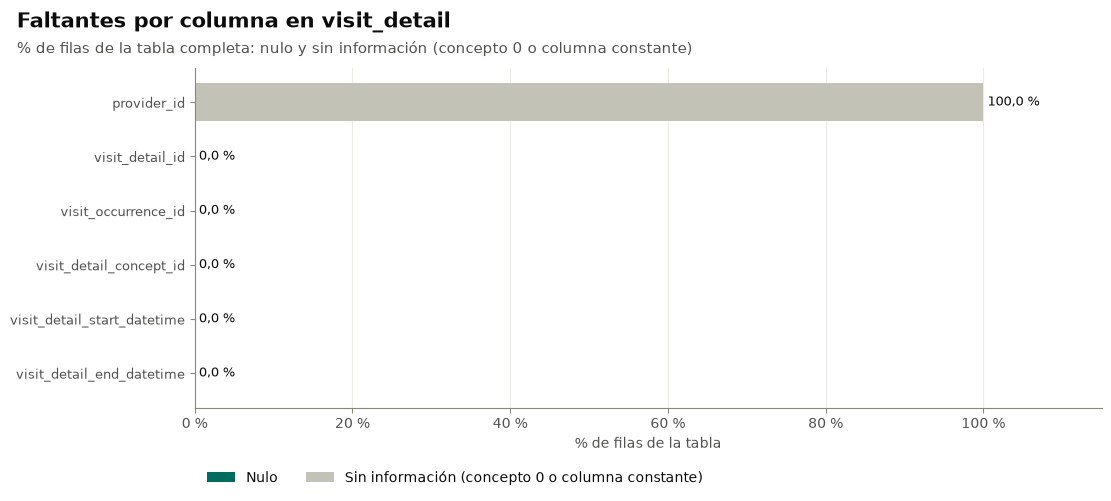

In [32]:
ver_faltantes('visit_detail')

### 3.1 Descripción: diccionario frente a columnas reales

In [33]:
mostrar_tabla(suprimir_pequenos(comparar_columnas(columnas_reales, 'visit_detail'), []), 'Diccionario frente a columnas reales de visit_detail')

**Diccionario frente a columnas reales de visit_detail**

,tipo_dato,estado
columna,,
visit_detail_id,integer,existe
visit_occurrence_id,integer,existe
visit_detail_concept_id,integer,existe
visit_detail_start_datetime,timestamp without time zone,existe
visit_detail_end_datetime,timestamp without time zone,existe
provider_id,integer,existe


### 3.2 Calidad

In [34]:
calidad_detail = mostrar_calidad('01t_detail_calidad', 'visit_detail')

**Chequeos de calidad de visit_detail**

,n,n_casos,pct_casos
chequeo,,,
id_etapa_repetido,3281613,0,0.00
fin_antes_de_inicio,3281613,0,0.00
duracion_cero,3281613,2097541,63.92
visita_inexistente,3281613,117,0.00
etapa_inicia_mas_de_1h_antes_de_su_visita,3281613,954931,29.10


**Rango de valores de visit_detail**

,valor
medida,
primer_mes,2023-01-01
ultimo_mes,2026-07-01


**Etapas que empiezan más de 1 h antes de su visita, por tipo de etapa**

,,n,n_inicia_antes,pct_inicia_antes
concepto_etapa,etapa,,,
9201,Hospitalización en piso (9201),108510,31457,28.99
9203,Ingreso por urgencias (9203),481481,94923,19.71
581479,Ingreso ambulatorio (581479),1539339,479784,31.17
3045729,Movimiento o etapa (3045729),1152166,348767,30.27


**Etapas que empiezan más de 1 h antes de su visita, por tipo de etapa y tipo de visita**

n n_inicia_antes pct_inicia_antes
etapa                          tipo_visita                                                           
Hospitalización en piso (9201) Hospitalización (9201)             737             15             2.04
                               Urgencias (9203)                 74006          10492            14.18
                               Consulta externa (581479)        25859          20599            79.66
                               Tratamiento urgente (3045729)     7908            351             4.44
Ingreso por urgencias (9203)   Hospitalización (9201)              31             30            96.77
                               Urgencias (9203)                419140          32622             7.78
                               Consulta externa (581479)        61387          61354            99.95
                               Tratamiento urgente (3045729)      923            917            99.35
Ingreso ambulatorio (581479)   No matching concept (0)            <10            <10        suprimido
                               Hospitalización (9201)             195            195            100.0
                               Urgencias (9203)                167902         167855            99.97
                               Consulta externa (581479)      1366121         306632            22.45
                               Tratamiento urgente (3045729)     5120           5101            99.63
Movimiento o etapa (3045729)   Hospitalización (9201)             110            107            97.27
                               Urgencias (9203)                855250         118405            13.84
                               Consulta externa (581479)       259806         226734            87.27
                               Tratamiento urgente (3045729)    37000           3521             9.52

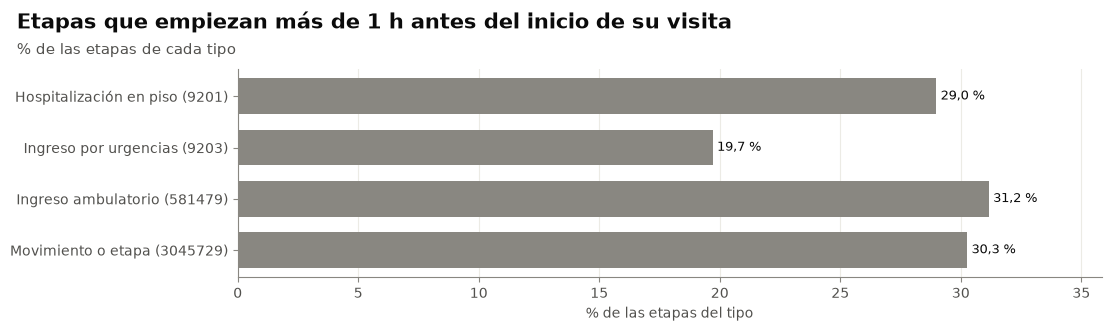

In [35]:
inicio_antes = consultar('01t_detail_inicio_antes_visita')
inicio_antes['etapa'] = [nombre_etapa(c, n) for c, n in zip(inicio_antes['concepto_etapa'], inicio_antes['etapa'])]
inicio_antes['tipo_visita'] = [nombre_tipo_visita(c, n) for c, n in zip(inicio_antes['concepto_visita'], inicio_antes['tipo_visita'])]
por_etapa_antes = inicio_antes.groupby(['concepto_etapa', 'etapa'])[['n', 'n_inicia_antes']].sum()
por_etapa_antes['pct_inicia_antes'] = 100 * por_etapa_antes['n_inicia_antes'] / por_etapa_antes['n']
mostrar_tabla(tabla_segura(por_etapa_antes), 'Etapas que empiezan más de 1 h antes de su visita, por tipo de etapa')
detalle_antes = inicio_antes.set_index(['etapa', 'tipo_visita']).drop(columns=['concepto_etapa', 'concepto_visita'])
detalle_antes['pct_inicia_antes'] = 100 * detalle_antes['n_inicia_antes'] / detalle_antes['n']
mostrar_tabla(tabla_segura(detalle_antes), 'Etapas que empiezan más de 1 h antes de su visita, por tipo de etapa y tipo de visita')
datos = por_etapa_antes.reset_index()
valores = datos['pct_inicia_antes'].where(datos['n_inicia_antes'] >= config.MIN_CELDA)
fig, ax = figura_top(len(datos))
y = np.arange(len(datos))[::-1]
barras = ax.barh(y, valores.fillna(0), height=0.7,
                 color=estilo.COLOR_EVENTO_PREVIO)
rotular_barras(ax, barras, valores, formato=fmt_pct, horizontal=True)
ax.set_yticks(y, datos['etapa'])
ax.set_xlim(0, max(1, np.nanmax(valores.to_numpy()) if valores.notna().any() else 1) * 1.15)
ax.grid(False)
ax.grid(axis='x')
ax.set_xlabel('% de las etapas del tipo')
titulo_hallazgo(fig, 'Etapas que empiezan más de 1 h antes del inicio de su visita', '% de las etapas de cada tipo')
guardar_figura(fig, '01_detail_inicio_antes_visita')
plt.show()

### 3.3 Univariado

Tipo de etapa, etapas por visita (con caja por tipo de visita) y duración de las etapas: las de duración 0 van en una barra propia («0 h») junto al histograma en escala log de las positivas, y las cajas usan las duraciones positivas.

**Etapas por tipo**

,,,n_detalles,n_visitas,pct_detalles
concepto_etapa,etapa,vocabulario,,,
581479,Ingreso ambulatorio (581479),Visit,1539340,1230996,46.91
3045729,Movimiento o etapa (3045729),LOINC,1152191,642577,35.11
9203,Ingreso por urgencias (9203),Visit,481481,448544,14.67
9201,Hospitalización en piso (9201),Visit,108601,69344,3.31


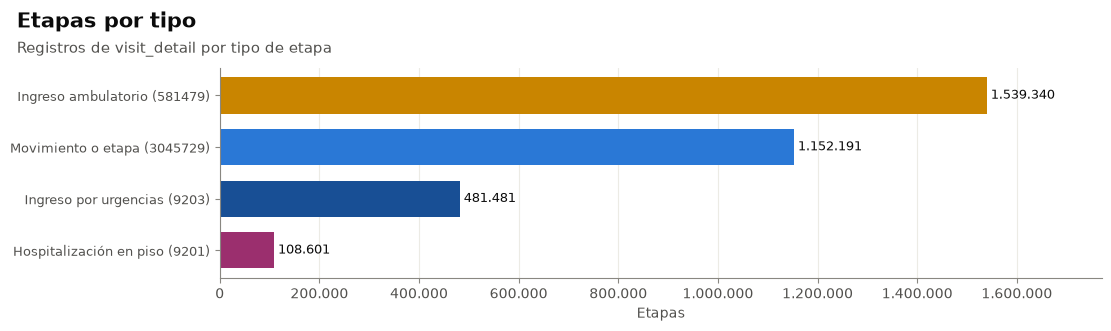

In [36]:
tipos_etapa = consultar('01_tipos_etapa')
tipos_etapa['etapa'] = [nombre_etapa(c, n) for c, n in zip(tipos_etapa['concepto_etapa'], tipos_etapa['etapa'])]
mostrar_tabla(tabla_segura(agregar_porcentaje(tipos_etapa.set_index(['concepto_etapa', 'etapa', 'vocabulario']), 'n_detalles')), 'Etapas por tipo')
serie = enmascarar_pequenos(tipos_etapa.set_index('etapa')['n_detalles'], tipos_etapa.set_index('etapa')['n_detalles'])
fig, ax = figura_top(len(serie))
barras_top_n(ax, serie, color=[estilo.COLOR_ETAPA.get(int(c), CLARO) for c in tipos_etapa['concepto_etapa']],
             n=len(serie), otros=False)
ax.set_xlabel('Etapas')
titulo_hallazgo(fig, 'Etapas por tipo', 'Registros de visit_detail por tipo de etapa')
guardar_figura(fig, '01_detail_tipos')
plt.show()

**Etapas por visita según el tipo de visita**

,Consulta externa (581479),Urgencias (9203),Tratamiento urgente (3045729)
etapas_por_visita,,,
0,29893,53373,51
1,589941,135629,2734
2,371565,135948,6137
3,51682,129474,4479
4-5,36545,104620,3264
6-9,9168,37473,1133
10+,667,1571,60


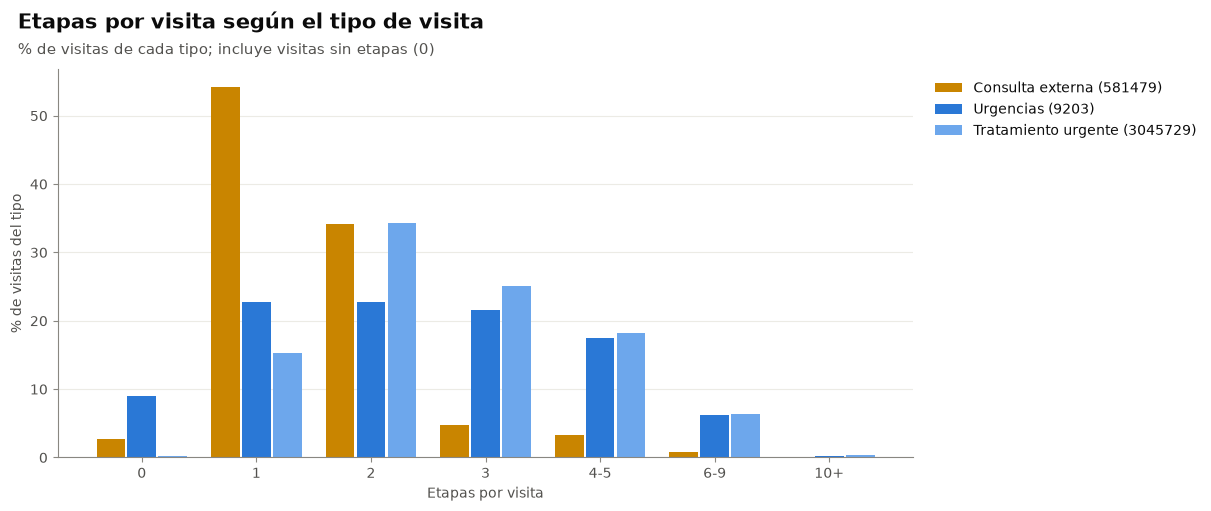

**Estadísticos de caja: etapas por visita**

,n,q1,mediana,q3,whislo,whishi,minimo,maximo,n_atipicos
tipo_visita,,,,,,,,,
Consulta externa (581479),1089461.0,1.0,1.0,2.0,0.0,3.0,0.0,34.0,46380.0
Urgencias (9203),598088.0,1.0,2.0,3.0,0.0,6.0,0.0,23.0,18049.0
Tratamiento urgente (3045729),17858.0,2.0,3.0,3.0,1.0,4.0,0.0,16.0,2479.0


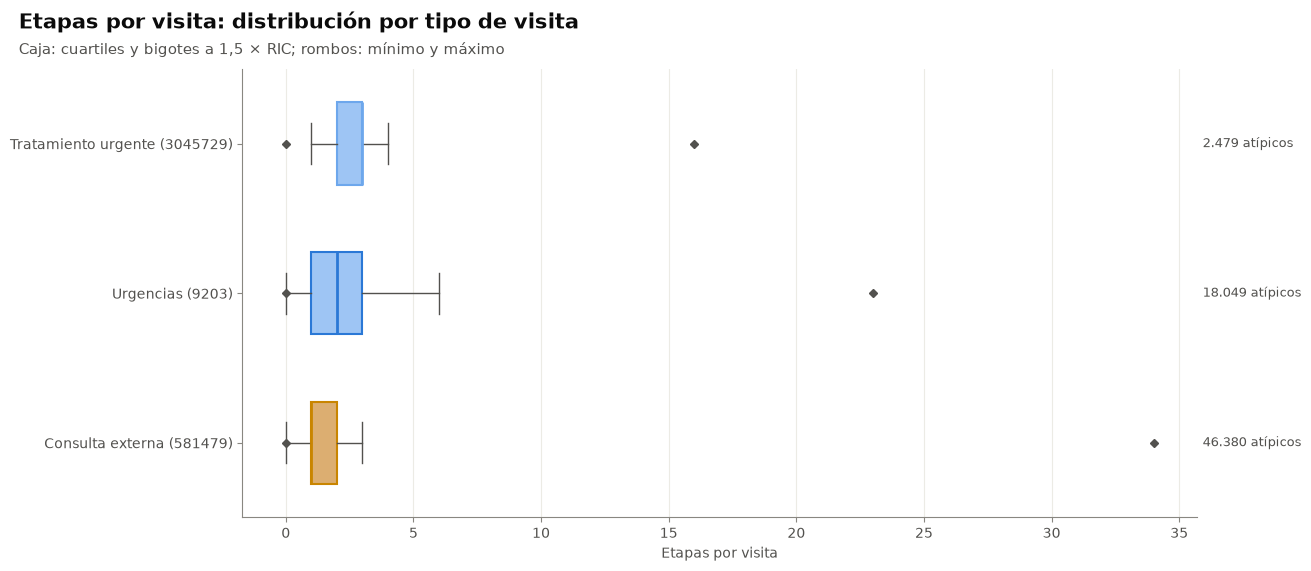

In [37]:
tipos_principales = list(etapas_visita.groupby('tipo_visita')['n_visitas'].sum().sort_values(ascending=False).index[:3])
matriz_etapas = pd.DataFrame({
    tipo: categorizar_conteos(etapas_visita[etapas_visita['tipo_visita'] == tipo]) for tipo in tipos_principales
}).rename_axis('etapas_por_visita')
mostrar_tabla(suprimir_pequenos(matriz_etapas, list(matriz_etapas.columns)), 'Etapas por visita según el tipo de visita')
pct = enmascarar_pequenos(100 * matriz_etapas / matriz_etapas.sum(), matriz_etapas)
fig, ax = plt.subplots(figsize=(12, 5))
x = np.arange(len(pct))
for j, tipo in enumerate(tipos_principales):
    color = colores_tipo_visita([tipo])[0]
    ax.bar(x + (j - 1) * 0.27, pct[tipo], width=0.25, color=color, label=tipo)
ax.set_xticks(x, pct.index.astype(str))
ax.set_xlabel('Etapas por visita')
ax.set_ylabel('% de visitas del tipo')
leyenda_fuera(ax)
titulo_hallazgo(fig, 'Etapas por visita según el tipo de visita', '% de visitas de cada tipo; incluye visitas sin etapas (0)')
guardar_figura(fig, '01_detail_etapas_por_visita')
plt.show()

cajas, etiquetas = cajas_desde_frecuencias(etapas_visita, 'tipo_visita', 'k', 'n_visitas', tipos_principales)
mostrar_tabla(tabla_cajas(cajas, etiquetas, 'tipo_visita'), 'Estadísticos de caja: etapas por visita')
fig, ax = plt.subplots(figsize=(13, 1.2 * len(cajas) + 2))
dibujar_cajas(ax, cajas, etiquetas, familias_tipo_visita(etiquetas), bordes=colores_tipo_visita(etiquetas))
ax.set_xlabel('Etapas por visita')
titulo_hallazgo(fig, 'Etapas por visita: distribución por tipo de visita', 'Caja: cuartiles y bigotes a 1,5 × RIC; rombos: mínimo y máximo')
guardar_figura(fig, '01_detail_etapas_caja_tipo')
plt.show()

**Duración de las etapas por tipo (horas; percentiles sobre duraciones positivas)**

,,n,n_sin_fin,n_negativas,n_cero,n_positivas,p00,p01,p25,p50,p75,p99,p100,n_atipicos
concepto_etapa,etapa,,,,,,,,,,,,,
581479,Ingreso ambulatorio (581479),1539340,0,0,1539340,0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,0
3045729,Movimiento o etapa (3045729),1152191,0,0,443359,708832,0.00,0.01,1.50,3.43,8.32,99.50,28070.29,75315
9203,Ingreso por urgencias (9203),481481,0,0,111309,370172,0.01,0.02,0.05,0.06,0.08,0.21,20730.34,18803
9201,Hospitalización en piso (9201),108601,0,0,3533,105068,0.00,0.02,22.08,47.08,97.15,554.85,11213.59,9166


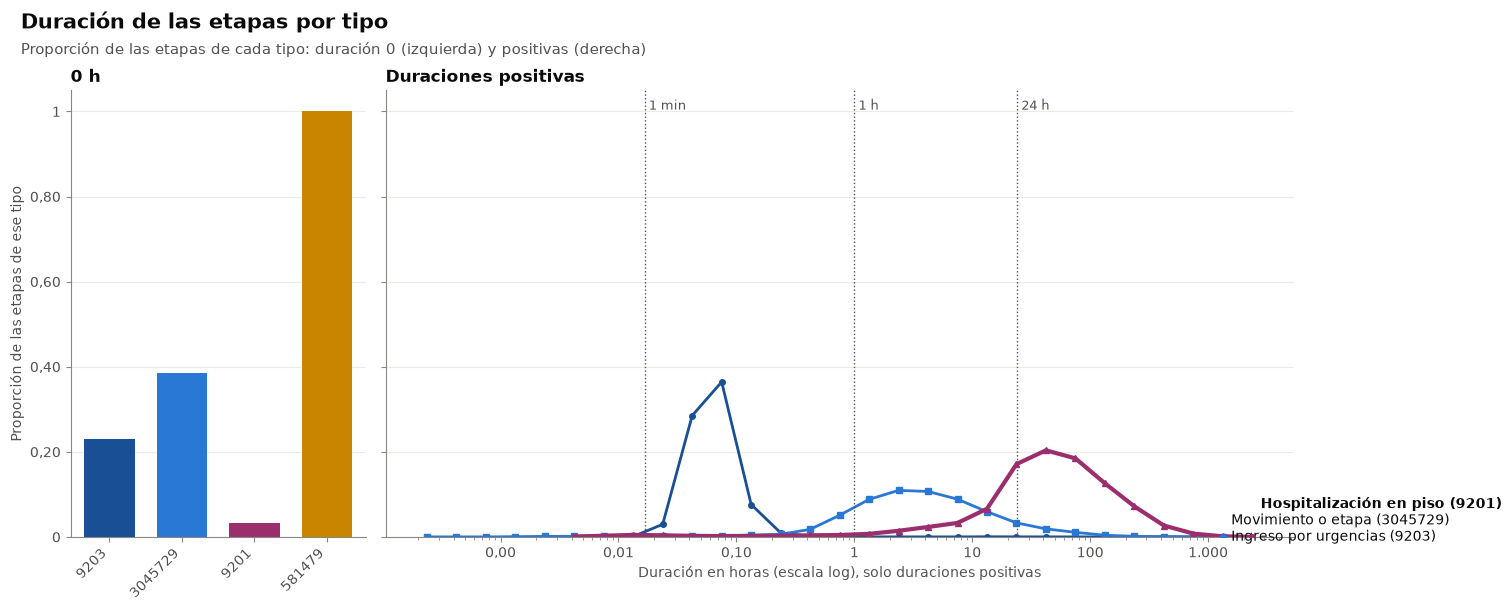

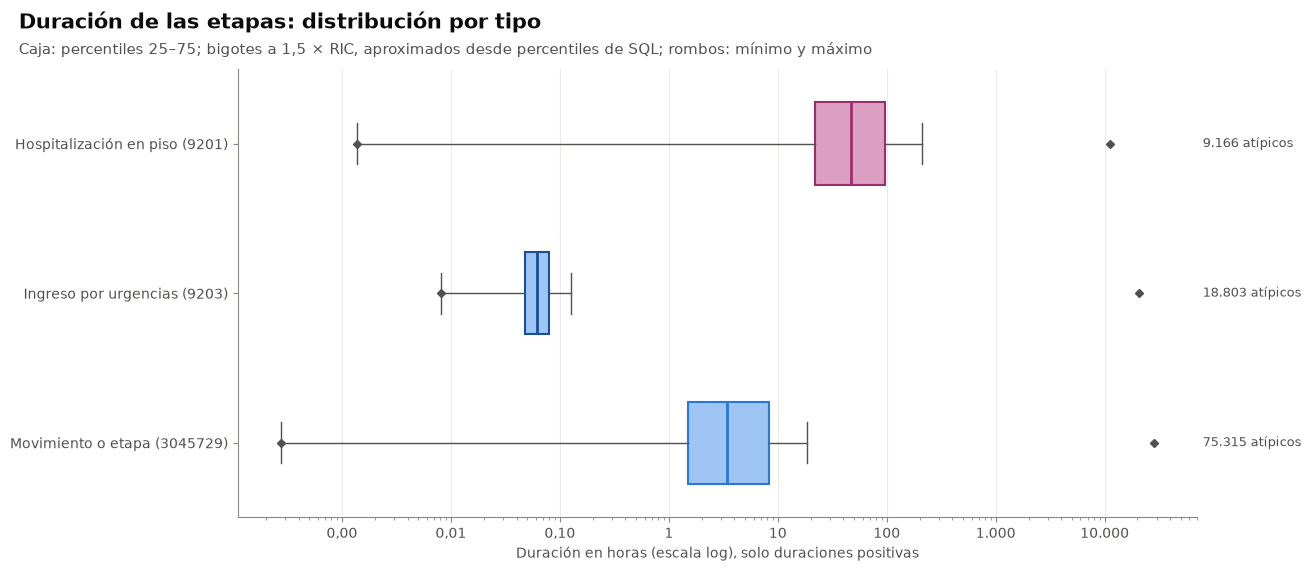

In [38]:
duracion = consultar('01t_detail_duracion_percentiles')
duracion['etapa'] = [nombre_etapa(c, n) for c, n in zip(duracion['concepto_etapa'], duracion['etapa'])]
mostrar_tabla(tabla_segura(duracion.set_index(['concepto_etapa', 'etapa']), conservar_ceros=True), 'Duración de las etapas por tipo (horas; percentiles sobre duraciones positivas)')
histograma = consultar('01_histograma_duracion_etapas')
histograma['bin_log10_h'] = histograma['bin_log10_h'].astype(float)
etapas_graf = [c for c in [config.CONCEPTO_URGENCIAS, config.CONCEPTO_SEGMENTO, config.CONCEPTO_PISO,
                            config.CONCEPTO_AMBULATORIO] if c in set(duracion['concepto_etapa'])]
total_etapa = duracion.set_index('concepto_etapa')['n']

fig, (ax_cero, ax_log) = plt.subplots(1, 2, figsize=(15, 6), sharey=True, gridspec_kw={'width_ratios': [1.3, 4]})
x = np.arange(len(etapas_graf))
cero = duracion.set_index('concepto_etapa').reindex(etapas_graf)
proporcion_cero = (cero['n_cero'] / cero['n']).where(cero['n_cero'] >= config.MIN_CELDA)
ax_cero.bar(x, proporcion_cero, color=[estilo.COLOR_ETAPA[c] for c in etapas_graf], width=0.7)
ax_cero.set_xticks(x, [str(c) for c in etapas_graf], rotation=45, ha='right')
ax_cero.set_title('0 h')
ax_cero.set_ylabel('Proporción de las etapas de ese tipo')
for i, concepto in enumerate(etapas_graf):
    datos = histograma[histograma['concepto_etapa'] == concepto].sort_values('bin_log10_h')
    if datos.empty:
        continue
    proporcion = (datos['n_detalles'] / total_etapa[concepto]).where(datos['n_detalles'] >= config.MIN_CELDA)
    centro_bin = 10 ** (datos['bin_log10_h'] + 0.125)
    color = estilo.COLOR_ETAPA[concepto]
    ax_log.plot(centro_bin, proporcion, marker=MARCADORES[i], markersize=4, color=color,
                linewidth=3 if concepto == config.CONCEPTO_PISO else 2)
    etiquetas_directas(ax_log, centro_bin, {nombre_etapa(concepto): (proporcion, color)},
                       negrita=[nombre_etapa(config.CONCEPTO_PISO)])
for horas, texto in [(1 / 60, '1 min'), (1, '1 h'), (24, '24 h')]:
    ax_log.axvline(horas, color=TEXTO_SECUNDARIO, linestyle=':', linewidth=1)
    ax_log.annotate(texto, xy=(horas, 1), xycoords=('data', 'axes fraction'), xytext=(3, -14),
                    textcoords='offset points', color=TEXTO_SECUNDARIO, fontsize=estilo.TAMANO_NOTA)
ax_log.set_xscale('log')
ax_log.set_xlabel('Duración en horas (escala log), solo duraciones positivas')
ax_log.set_title('Duraciones positivas')
titulo_hallazgo(fig, 'Duración de las etapas por tipo', 'Proporción de las etapas de cada tipo: duración 0 (izquierda) y positivas (derecha)')
guardar_figura(fig, '01_detail_duracion_etapas')
plt.show()

positivas = duracion[duracion['n_positivas'] >= config.MIN_CELDA]
cajas = [estadisticos_caja_desde_percentiles(f.drop('n').rename({'n_positivas': 'n'})) for _, f in positivas.iterrows()]
fig, ax = plt.subplots(figsize=(13, 1.2 * len(cajas) + 2))
dibujar_cajas(ax, cajas, list(positivas['etapa']), [estilo.familia_de_etapa(c) for c in positivas['concepto_etapa']],
              escala_log=True, bordes=[estilo.COLOR_ETAPA.get(int(c), OSCURO) for c in positivas['concepto_etapa']])
ax.set_xlabel('Duración en horas (escala log), solo duraciones positivas')
titulo_hallazgo(fig, 'Duración de las etapas: distribución por tipo', 'Caja: percentiles 25–75; bigotes a 1,5 × RIC, aproximados desde percentiles de SQL; rombos: mínimo y máximo')
guardar_figura(fig, '01_detail_duracion_caja')
plt.show()

### 3.4 Bivariado

1. Etapa × tipo de visita.
2. Etapa × mes.

In [39]:
etapas_por_tipo = consultar('01_etapas_por_tipo_visita')
etapas_por_tipo['tipo_visita'] = [nombre_tipo_visita(c, n) for c, n in zip(etapas_por_tipo['concepto_visita'], etapas_por_tipo['tipo_visita'])]
etapas_por_tipo['etapa'] = [nombre_etapa(c, n) for c, n in zip(etapas_por_tipo['concepto_etapa'], etapas_por_tipo['etapa'])]
mostrar_tabla(tabla_segura(etapas_por_tipo.set_index(['tipo_visita', 'etapa']).drop(columns=['concepto_visita', 'concepto_etapa'])), 'Etapas por tipo de visita')

**Etapas por tipo de visita**

n_detalles n_visitas
tipo_visita                   etapa                                              
No matching concept (0)       Ingreso ambulatorio (581479)          <10       <10
Hospitalización (9201)        Hospitalización en piso (9201)        737       589
                              Ingreso ambulatorio (581479)          195       195
                              Movimiento o etapa (3045729)          110        73
                              Ingreso por urgencias (9203)           31        31
Urgencias (9203)              Movimiento o etapa (3045729)       855250    470002
                              Ingreso por urgencias (9203)       419140    386203
                              Ingreso ambulatorio (581479)       167902    167516
                              Hospitalización en piso (9201)      74006     47754
Consulta externa (581479)     Ingreso ambulatorio (581479)      1366121   1058171
                              Movimiento o etapa (3045729)       259806    154690
                              Ingreso por urgencias (9203)        61387     61387
                              Hospitalización en piso (9201)      25859     15839
Tratamiento urgente (3045729) Movimiento o etapa (3045729)        37000     17790
                              Hospitalización en piso (9201)       7908      5108
                              Ingreso ambulatorio (581479)         5120      5112
                              Ingreso por urgencias (9203)          923       923

**Etapas por mes de inicio y tipo de etapa**

concepto_etapa,Hospitalización en piso (9201),Ingreso por urgencias (9203),Ingreso ambulatorio (581479),Movimiento o etapa (3045729)
mes,,,,
2023-01-01,2805,15118,30431,30460
2023-02-01,2312,13024,28287,26577
2023-03-01,2598,15257,37188,31128
2023-04-01,2586,14308,30042,29517
2023-05-01,2517,16253,37530,31704
2023-06-01,2413,14364,33865,29003
2023-07-01,2577,14197,35960,30332
2023-08-01,2578,14170,40804,31129
2023-09-01,2414,12860,40663,29124


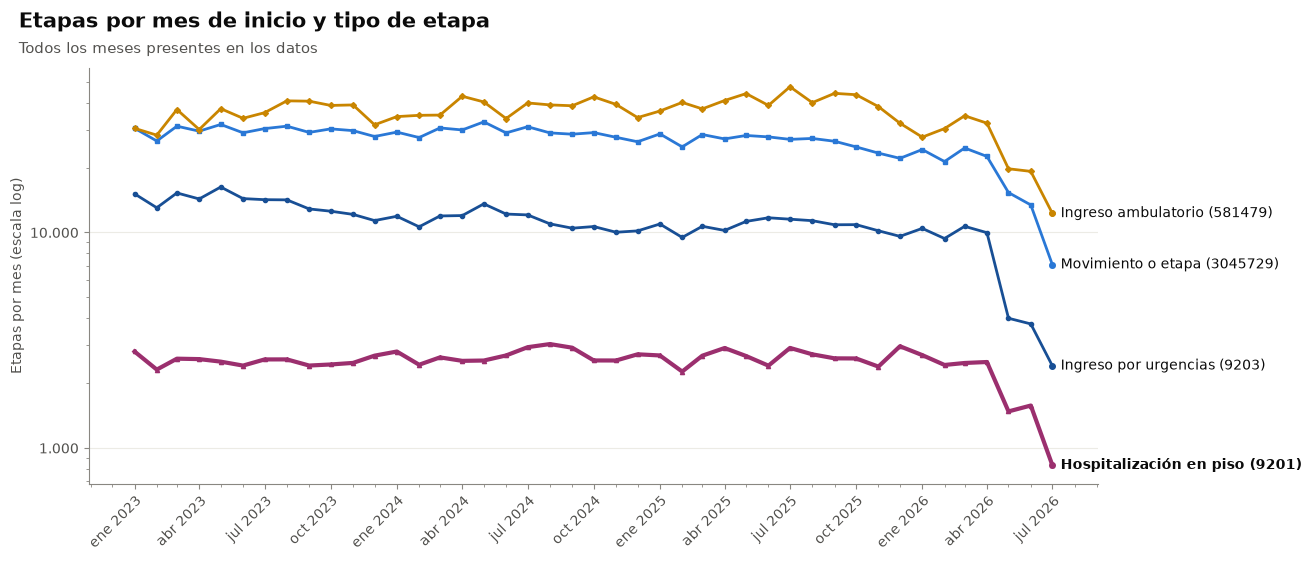

In [40]:
detalle_mensual = consultar('01t_detail_mensual')
detalle_mensual['mes'] = pd.to_datetime(detalle_mensual['mes'])
matriz_mes = detalle_mensual.pivot_table(index='mes', columns='concepto_etapa', values='n_etapas', aggfunc='sum', fill_value=0)
mostrar_tabla(suprimir_pequenos(matriz_mes.rename(columns=nombre_etapa), [nombre_etapa(c) for c in matriz_mes.columns]), 'Etapas por mes de inicio y tipo de etapa')
fig, ax = plt.subplots(figsize=(13, 5.5))
for i, concepto in enumerate([c for c in etapas_graf if c in matriz_mes.columns]):
    valores = enmascarar_pequenos(matriz_mes[concepto], matriz_mes[concepto])
    color = estilo.COLOR_ETAPA[concepto]
    ax.plot(valores.index, valores, marker=MARCADORES[i], markersize=3, color=color,
            linewidth=3 if concepto == config.CONCEPTO_PISO else 2)
    etiquetas_directas(ax, valores.index, {nombre_etapa(concepto): (valores, color)},
                       negrita=[nombre_etapa(config.CONCEPTO_PISO)])
ax.set_yscale('log')
ax.set_ylabel('Etapas por mes (escala log)')
titulo_hallazgo(fig, 'Etapas por mes de inicio y tipo de etapa', 'Todos los meses presentes en los datos')
guardar_figura(fig, '01_detail_mensual')
plt.show()

### 3.5 Observaciones

In [41]:
n_etapas = calidad_detail['n_filas']
provider_detail = faltantes[(faltantes['tabla'] == 'visit_detail') & (faltantes['columna'] == 'provider_id')].iloc[0]
items = [
    ('provider_id', 'valores distintos', fmt_entero(provider_detail['valores_distintos'])),
    ('visit_detail_start_datetime', 'etapas que empiezan más de 1 h antes del inicio de su visita',
     calidad_detail['chequeo__etapa_inicia_mas_de_1h_antes_de_su_visita'], n_etapas),
    ('visit_detail_end_datetime', 'etapas con fin anterior al inicio', calidad_detail['chequeo__fin_antes_de_inicio'], n_etapas),
    ('visit_detail_end_datetime', 'etapas con duración 0', calidad_detail['chequeo__duracion_cero'], n_etapas),
]
for (concepto, etapa), fila in por_etapa_antes.iterrows():
    items.append(('visit_detail_start_datetime', f'{etapa}: empiezan más de 1 h antes de su visita', fila['n_inicia_antes'], fila['n']))
for _, fila in duracion.iterrows():
    items.append(('visit_detail_end_datetime', f"{fila['etapa']}: duración 0", fila['n_cero'], fila['n']))
observar('visit_detail', items)

**Observaciones de visit_detail**

,columna,hallazgo,magnitud
0,provider_id,valores distintos,1
1,visit_detail_start_datetime,etapas que empiezan más de 1 h antes del inicio de su vi...,"29,1 % (954.931 de 3.281.613)"
2,visit_detail_end_datetime,etapas con fin anterior al inicio,0 casos
3,visit_detail_end_datetime,etapas con duración 0,"63,9 % (2.097.541 de 3.281.613)"
4,visit_detail_start_datetime,Hospitalización en piso (9201): empiezan más de 1 h ante...,"29,0 % (31.457 de 108.510)"
5,visit_detail_start_datetime,Ingreso por urgencias (9203): empiezan más de 1 h antes ...,"19,7 % (94.923 de 481.481)"
6,visit_detail_start_datetime,Ingreso ambulatorio (581479): empiezan más de 1 h antes ...,"31,2 % (479.784 de 1.539.339)"
7,visit_detail_start_datetime,Movimiento o etapa (3045729): empiezan más de 1 h antes ...,"30,3 % (348.767 de 1.152.166)"
8,visit_detail_end_datetime,Ingreso ambulatorio (581479): duración 0,"100,0 % (1.539.340 de 1.539.340)"
9,visit_detail_end_datetime,Movimiento o etapa (3045729): duración 0,"38,5 % (443.359 de 1.152.191)"


**Interpretación del equipo:** _(completar al revisar los resultados)_

## 4. `condition_occurrence`

### Ficha del dataset

In [42]:
ver_head('condition_occurrence')

**head(): primeras 5 filas de condition_occurrence, ordenadas por condition_occurrence_id**

,condition_occurrence_id,person_id,visit_occurrence_id,condition_concept_id,condition_start_datetime,condition_type_concept_id
0,377,18635,2415503,0,2023-01-20 16:59:10,0
1,391,18635,2417969,0,2023-01-24 16:53:57,0
2,392,18635,2419614,0,2023-01-26 17:39:23,0
3,393,18635,2428139,0,2023-02-08 17:10:06,0
4,410,18635,2451270,0,2023-03-16 17:34:24,0


In [43]:
ver_info('condition_occurrence')

**info(): condition_occurrence · 38.636.063 filas × 6 columnas**

,columna,tipo de dato,no nulos,nulos,% nulos,valores distintos
0,condition_occurrence_id,integer,38636063,0,0.000000,38636063
1,person_id,integer,38636063,0,0.000000,206395
2,visit_occurrence_id,integer,37812634,823429,2.131245,566003
3,condition_concept_id,integer,38636063,0,0.000000,4145
4,condition_start_datetime,timestamp without time zone,38636063,0,0.000000,6020908
5,condition_type_concept_id,integer,38636063,0,0.000000,1


In [44]:
ver_describe('condition_occurrence')

**describe(): columnas numéricas y fechas de condition_occurrence (sin columnas de ID)**

,condition_start_datetime
estadístico,
count,38.636.063
min,2023-01-01 00:01:50
25%,2023-10-31 16:09:18
50%,2024-09-28 11:18:19
75%,2025-08-09 14:13:19
max,2033-05-29 09:38:26


**describe(): columnas categóricas de condition_occurrence (top traducido con concept)**

columna,condition_concept_id,condition_type_concept_id
estadístico,,
count,38.636.063,38.636.063
unique,4.145,<10
top,No matching concept (0),No matching concept (0)
freq,14.605.421,38.636.063


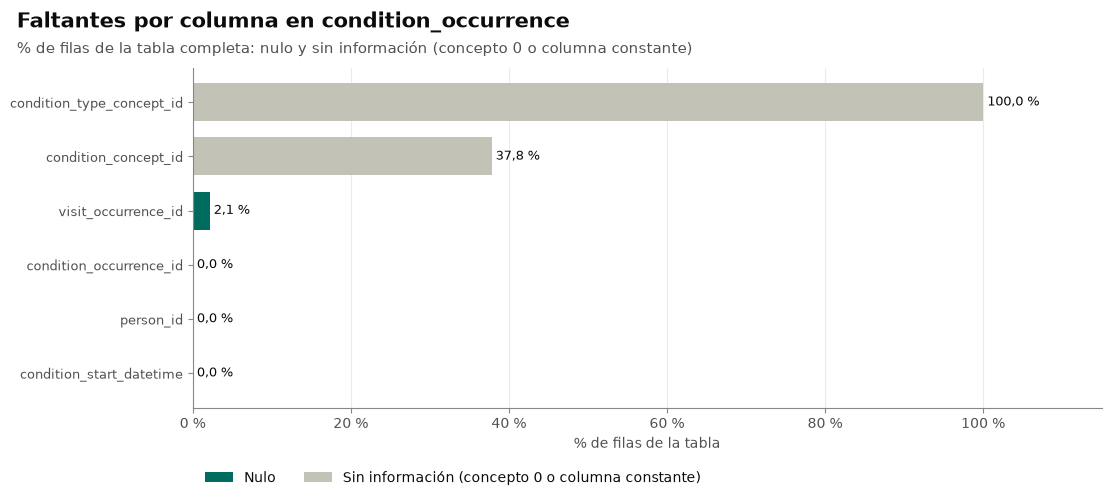

In [45]:
ver_faltantes('condition_occurrence')

### 4.1 Descripción: diccionario frente a columnas reales

In [46]:
mostrar_tabla(suprimir_pequenos(comparar_columnas(columnas_reales, 'condition_occurrence'), []), 'Diccionario frente a columnas reales de condition_occurrence')

**Diccionario frente a columnas reales de condition_occurrence**

,tipo_dato,estado
columna,,
condition_occurrence_id,integer,existe
person_id,integer,existe
visit_occurrence_id,integer,existe
condition_concept_id,integer,existe
condition_start_datetime,timestamp without time zone,existe
condition_type_concept_id,integer,no está en el diccionario


### 4.2 Calidad

Incluye el concepto 0, los valores distintos de `condition_type_concept_id` y las fechas posteriores a la última visita registrada.

In [47]:
calidad_condition = mostrar_calidad('01t_condition_calidad', 'condition_occurrence')

**Chequeos de calidad de condition_occurrence**

,n,n_casos,pct_casos
chequeo,,,
concepto_0,38636063,14605421,37.80
concepto_sin_traduccion,38636063,0,0.00
visita_inexistente,38636063,84789,0.22
fecha_posterior_a_la_ultima_visita,38636063,82,0.00
fecha_anterior_a_la_primera_visita,38636063,76,0.00


**Rango de valores de condition_occurrence**

,valor
medida,
primer_mes,2023-01-01
ultimo_mes,2033-05-01


### 4.3 Univariado

Top 30 diagnósticos (sin el concepto 0, con «Otros» al final) y diagnósticos por visita, con caja por tipo de visita.

**Top 30 diagnósticos (sin concepto 0)**

,,,,n_registros
concepto,diagnostico,vocabulario,dominio,
443600,Localized infection of skin AND/OR subcutaneous tissue,SNOMED,Condition,1219221
81902,Urinary tract infectious disease,SNOMED,Condition,1121314
201690,Renal colic,SNOMED,Condition,644595
381316,Cerebrovascular accident,SNOMED,Condition,470296
319835,Congestive heart failure,SNOMED,Condition,415160
201618,Disorder of intestine,SNOMED,Condition,384458
200219,Abdominal pain,SNOMED,Condition,361687
192671,Gastrointestinal hemorrhage,SNOMED,Condition,332929
378253,Headache,SNOMED,Condition,276920


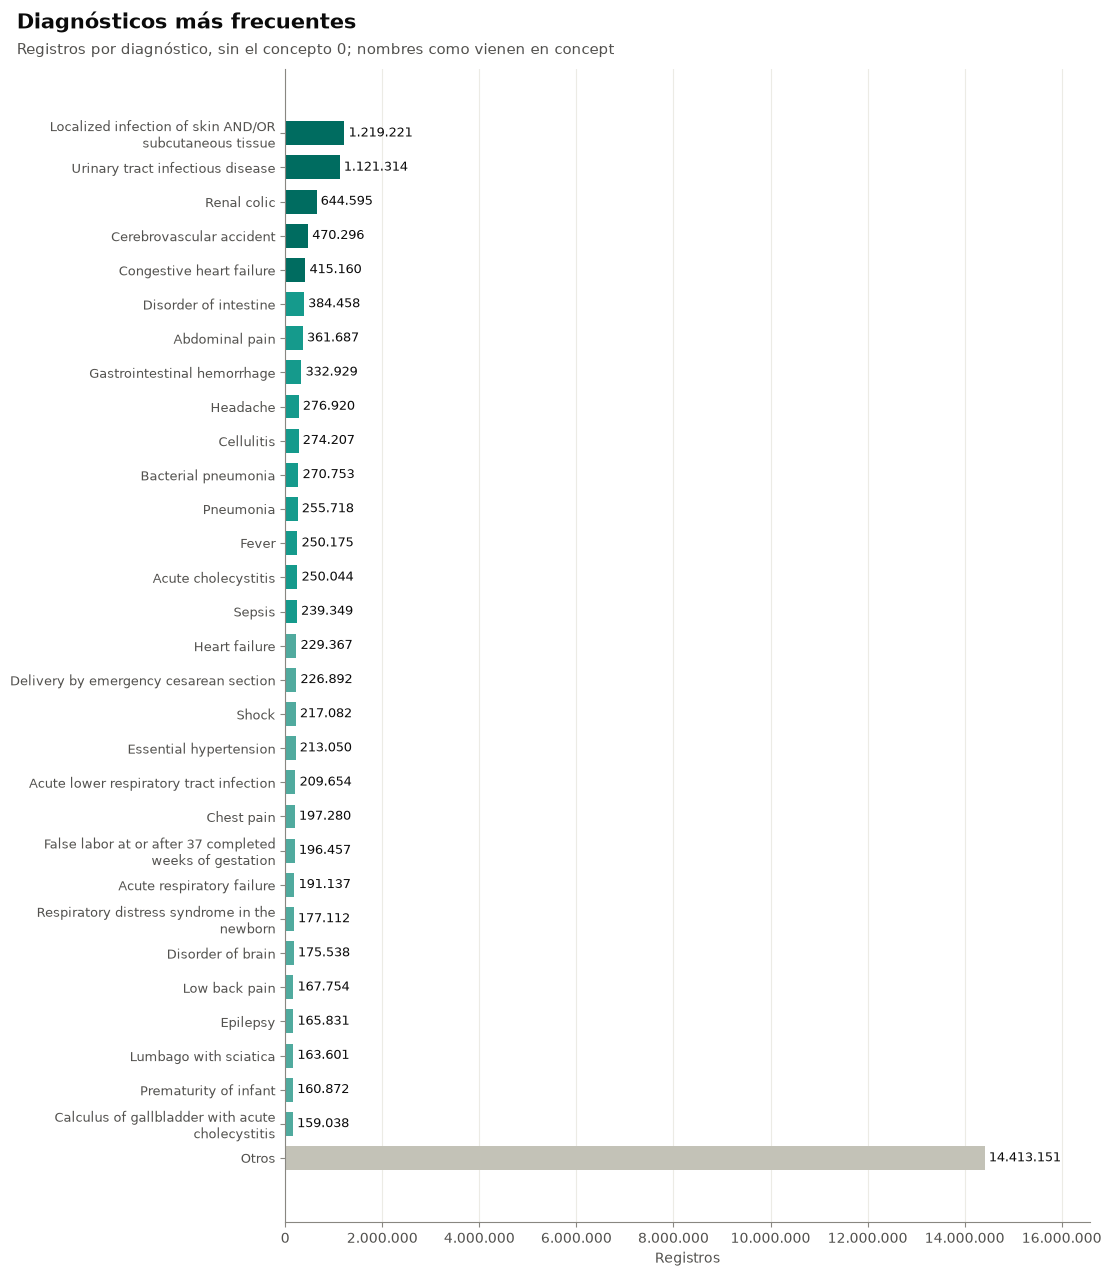

In [48]:
top_dx = consultar('01t_condition_top30')
mostrar_tabla(tabla_segura(top_dx.set_index(['concepto', 'diagnostico', 'vocabulario', 'dominio'])), 'Top 30 diagnósticos (sin concepto 0)')
fila_dx = faltantes[(faltantes['tabla'] == 'condition_occurrence') & (faltantes['columna'] == 'condition_concept_id')].iloc[0]
total_con_concepto = fila_dx['n'] - fila_dx['n_nulos'] - fila_dx['n_concepto_0']
serie = enmascarar_pequenos(top_dx.set_index('diagnostico')['n_registros'], top_dx.set_index('diagnostico')['n_registros'])
fig, ax = figura_top(len(serie) + 1)
barras_top_n(ax, serie, familia='general', n=30, otros=True, total=total_con_concepto)
ax.set_xlabel('Registros')
titulo_hallazgo(fig, 'Diagnósticos más frecuentes', 'Registros por diagnóstico, sin el concepto 0; nombres como vienen en concept')
guardar_figura(fig, '01_condition_top30')
plt.show()

**Registros de diagnóstico frente a diagnósticos distintos por visita**

variable,n_distintos_por_visita,n_registros,registros_por_diagnostico_distinto
tipo_visita,,,
Urgencias (9203),215258,19884145,92.37
Tratamiento urgente (3045729),8228,2446125,297.29
Consulta externa (581479),182279,779329,4.28
Hospitalización (9201),499,36482,73.11
No matching concept (0),<10,<10,suprimido


**Diagnósticos distintos por visita según el tipo de visita**

,Consulta externa (581479),Urgencias (9203),Tratamiento urgente (3045729)
diagnosticos_distintos_por_visita,,,
0,938918,427814,12689
1,126012,135049,3213
2,18781,28222,1249
3,4374,4784,403
4-5,1373,2153,294
6-9,<10,66,10
10+,<10,<10,<10


**Estadísticos de caja: diagnósticos distintos por visita**

,n,q1,mediana,q3,whislo,whishi,minimo,maximo,n_atipicos
tipo_visita,,,,,,,,,
Consulta externa (581479),1089461.0,0.0,0.0,0.0,0.0,0.0,0.0,6.0,150543.0
Urgencias (9203),598088.0,0.0,0.0,1.0,0.0,2.0,0.0,7.0,7003.0
Tratamiento urgente (3045729),17858.0,0.0,0.0,1.0,0.0,2.0,0.0,7.0,707.0


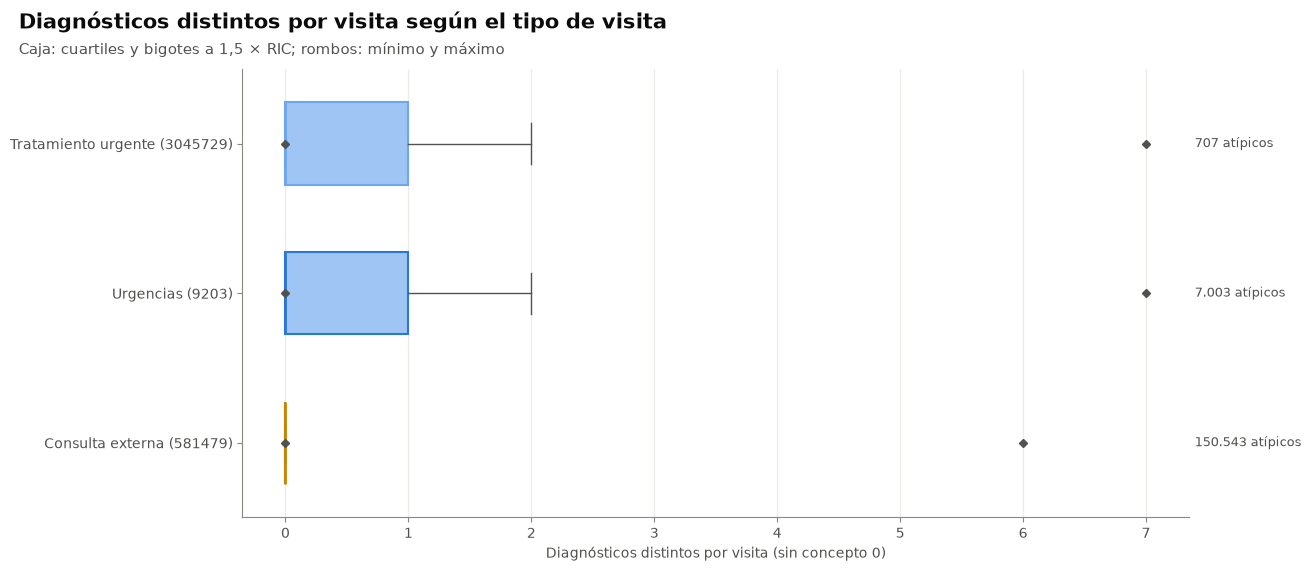

In [49]:
dx_visita = conteos_visita[conteos_visita['variable'].isin(['registros_diagnostico', 'diagnosticos_distintos'])]
repetidos = dx_visita.assign(total=dx_visita['k'] * dx_visita['n_visitas']).pivot_table(
    index='tipo_visita', columns='variable', values='total', aggfunc='sum', fill_value=0)
repetidos = repetidos.rename(columns={'registros_diagnostico': 'n_registros', 'diagnosticos_distintos': 'n_distintos_por_visita'})
repetidos['registros_por_diagnostico_distinto'] = repetidos['n_registros'] / repetidos['n_distintos_por_visita']
mostrar_tabla(tabla_segura(repetidos.sort_values('n_registros', ascending=False)), 'Registros de diagnóstico frente a diagnósticos distintos por visita')
distintos = dx_visita[dx_visita['variable'] == 'diagnosticos_distintos']
matriz_dx = pd.DataFrame({
    tipo: categorizar_conteos(distintos[distintos['tipo_visita'] == tipo]) for tipo in tipos_principales
}).rename_axis('diagnosticos_distintos_por_visita')
mostrar_tabla(suprimir_pequenos(matriz_dx, list(matriz_dx.columns)), 'Diagnósticos distintos por visita según el tipo de visita')
cajas, etiquetas = cajas_desde_frecuencias(distintos, 'tipo_visita', 'k', 'n_visitas', tipos_principales)
mostrar_tabla(tabla_cajas(cajas, etiquetas, 'tipo_visita'), 'Estadísticos de caja: diagnósticos distintos por visita')
fig, ax = plt.subplots(figsize=(13, 1.2 * len(cajas) + 2))
dibujar_cajas(ax, cajas, etiquetas, familias_tipo_visita(etiquetas), bordes=colores_tipo_visita(etiquetas))
ax.set_xlabel('Diagnósticos distintos por visita (sin concepto 0)')
titulo_hallazgo(fig, 'Diagnósticos distintos por visita según el tipo de visita', 'Caja: cuartiles y bigotes a 1,5 × RIC; rombos: mínimo y máximo')
guardar_figura(fig, '01_condition_por_visita_caja')
plt.show()

### 4.4 Bivariado

1. Top 15 diagnósticos en visitas de urgencias frente a ambulatorias (una figura por tipo).
2. Diagnósticos por mes y tipo de visita, con el porcentaje de concepto 0 por mes.

**Top 15 diagnósticos en urgencias y en consulta externa**

n_registros  pct_registros
tipo_visita rango concepto diagnostico                                                                       
ambulatoria 1     4245842  Umbilical hernia                                              27451           3.52
            2     197236   Uterine leiomyoma                                             26900           3.45
            3     198803   Benign prostatic hyperplasia                                  26810           3.44
            4     4338031  Mixed anxiety and depressive disorder                         25715           3.30
            5     4066112  Delivery by emergency cesarean section                        15603           2.00
            6     40484028 Dental caries extending into dentin                           15358           1.97
            7     4288544  Inguinal hernia                                               14783           1.90
            8     444239   Postprocedural state finding                                  12600           1.62
            9     4061457  Delivery by elective cesarean section                         12455           1.60
            10    4036803  General examination of patient                                11816           1.52
            11    193277   Deliveries by cesarean                                        11443           1.47
            12    45765728 Supervision of high risk pregnancy                            11396           1.46
            13    194133   Low back pain                                                  9929           1.27
            14    320128   Essential hypertension                                         8676           1.11
            15    4145627  Biliary calculus                                               8337           1.07
urgencias   1     443600   Localized infection of skin AND/OR subcutaneous tissue      1101947           5.54
            2     81902    Urinary tract infectious disease                            1027907           5.17
            3     201690   Renal colic                                                  609347           3.06
            4     319835   Congestive heart failure                                     379285           1.91
            5     201618   Disorder of intestine                                        373315           1.88
            6     381316   Cerebrovascular accident                                     372063           1.87
            7     200219   Abdominal pain                                               320816           1.61
            8     192671   Gastrointestinal hemorrhage                                  282582           1.42
            9     378253   Headache                                                     265169           1.33
            10    435613   Cellulitis                                                   252768           1.27
            11    257315   Bacterial pneumonia                                          245925           1.24
            12    437663   Fever                                                        234677           1.18
            13    198809   Acute cholecystitis                                          230953           1.16
            14    255848   Pneumonia                                                    230660           1.16
            15    316139   Heart failure                                                211655           1.06

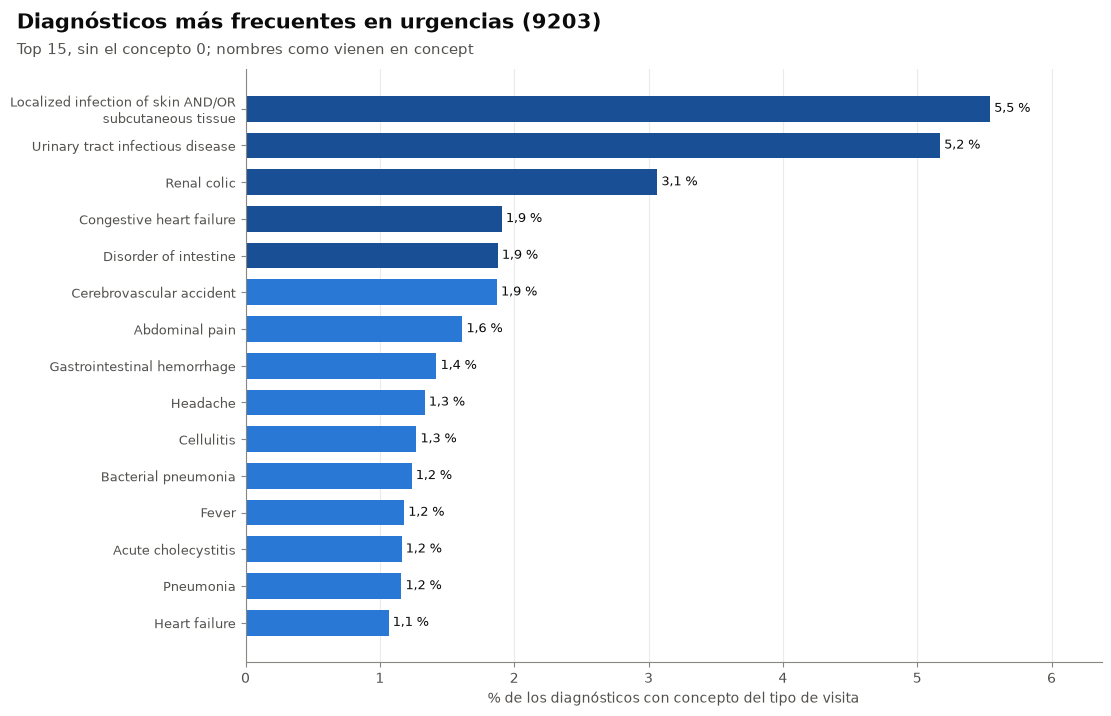

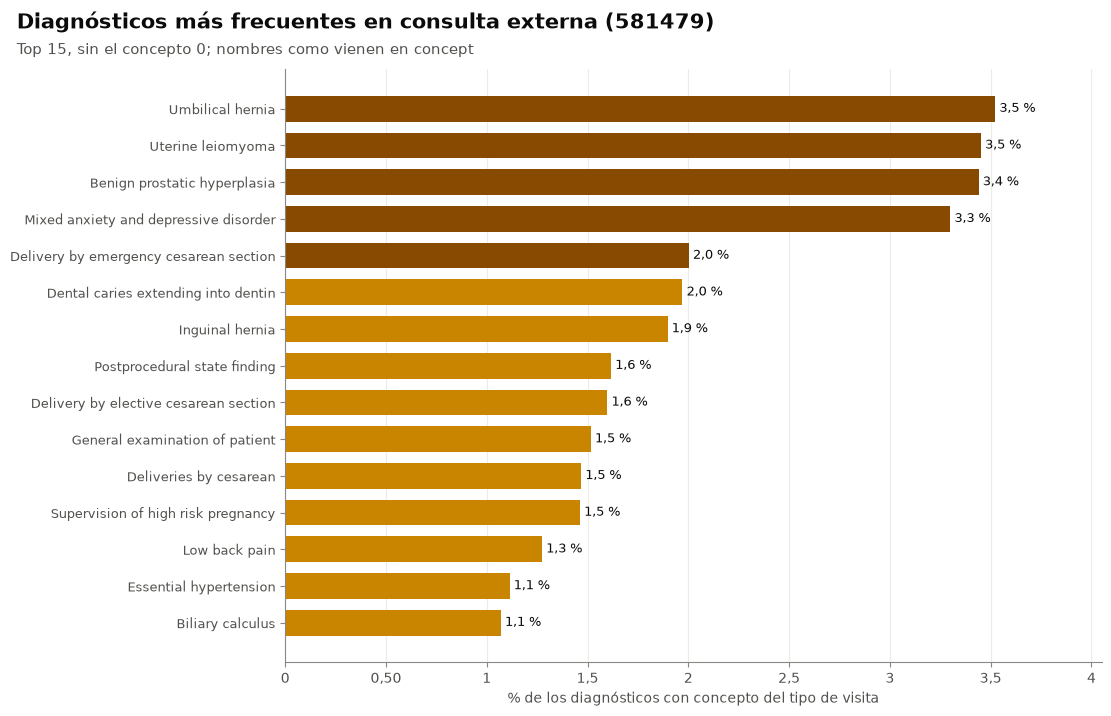

In [50]:
top_urg_amb = consultar('01t_condition_top_urg_amb')
mostrar_tabla(tabla_segura(top_urg_amb.set_index(['tipo_visita', 'rango', 'concepto', 'diagnostico'])), 'Top 15 diagnósticos en urgencias y en consulta externa')
for tipo, familia_panel, texto in [('urgencias', 'urgencias', 'urgencias (9203)'), ('ambulatoria', 'ambulatorio', 'consulta externa (581479)')]:
    parte = top_urg_amb[top_urg_amb['tipo_visita'] == tipo].set_index('diagnostico')
    if parte.empty:
        continue
    serie = parte['pct_registros'].where(parte['n_registros'] >= config.MIN_CELDA)
    fig, ax = figura_top(len(serie))
    barras_top_n(ax, serie, familia=familia_panel, n=15, otros=False, formato=fmt_pct)
    ax.set_xlabel('% de los diagnósticos con concepto del tipo de visita')
    titulo_hallazgo(fig, f'Diagnósticos más frecuentes en {texto}', 'Top 15, sin el concepto 0; nombres como vienen en concept')
    guardar_figura(fig, f'01_condition_top_{tipo}')
    plt.show()

**Diagnósticos por mes y tipo de visita**

tipo_visita,(sin visita),Consulta externa (581479),Hospitalización (9201),Tratamiento urgente (3045729),Urgencias (9203)
mes,,,,,
2023-01-01,127822,177651,<10,61102,657489
2023-02-01,68159,137276,1317,71642,592943
2023-03-01,43836,171341,483,85129,751430
2023-04-01,32420,133066,<10,48743,603757
2023-05-01,46153,132909,317,38628,689163
...,...,...,...,...,...
2032-06-01,<10,<10,<10,<10,<10
2032-09-01,<10,<10,<10,<10,<10
2032-11-01,<10,<10,<10,<10,<10


**Diagnósticos con concepto 0 por mes**

,n,n_concepto_0,pct_concepto_0
mes,,,
2023-01-01,1024064,459669,44.89
2023-02-01,871337,342065,39.26
2023-03-01,1052219,467733,44.45
2023-04-01,817986,317193,38.78
2023-05-01,907170,314302,34.65
...,...,...,...
2032-06-01,<10,<10,suprimido
2032-09-01,<10,<10,suprimido
2032-11-01,<10,<10,suprimido


/var/home/luencaro/Programing/College/2026-30/Data Challenge HUN/patient-flow-HUN/src/graficos.py:625: UserWarning: Figura 01_condition_mensual: 14 pares de textos superpuestos, por ejemplo «ene 2023» y «abr 2023»; «abr 2023» y «jul 2023»; «jul 2023» y «oct 2023»; «oct 2023» y «ene 2024»; «ene 2024» y «abr 2024».
  revisar_solapes(fig, nombre)


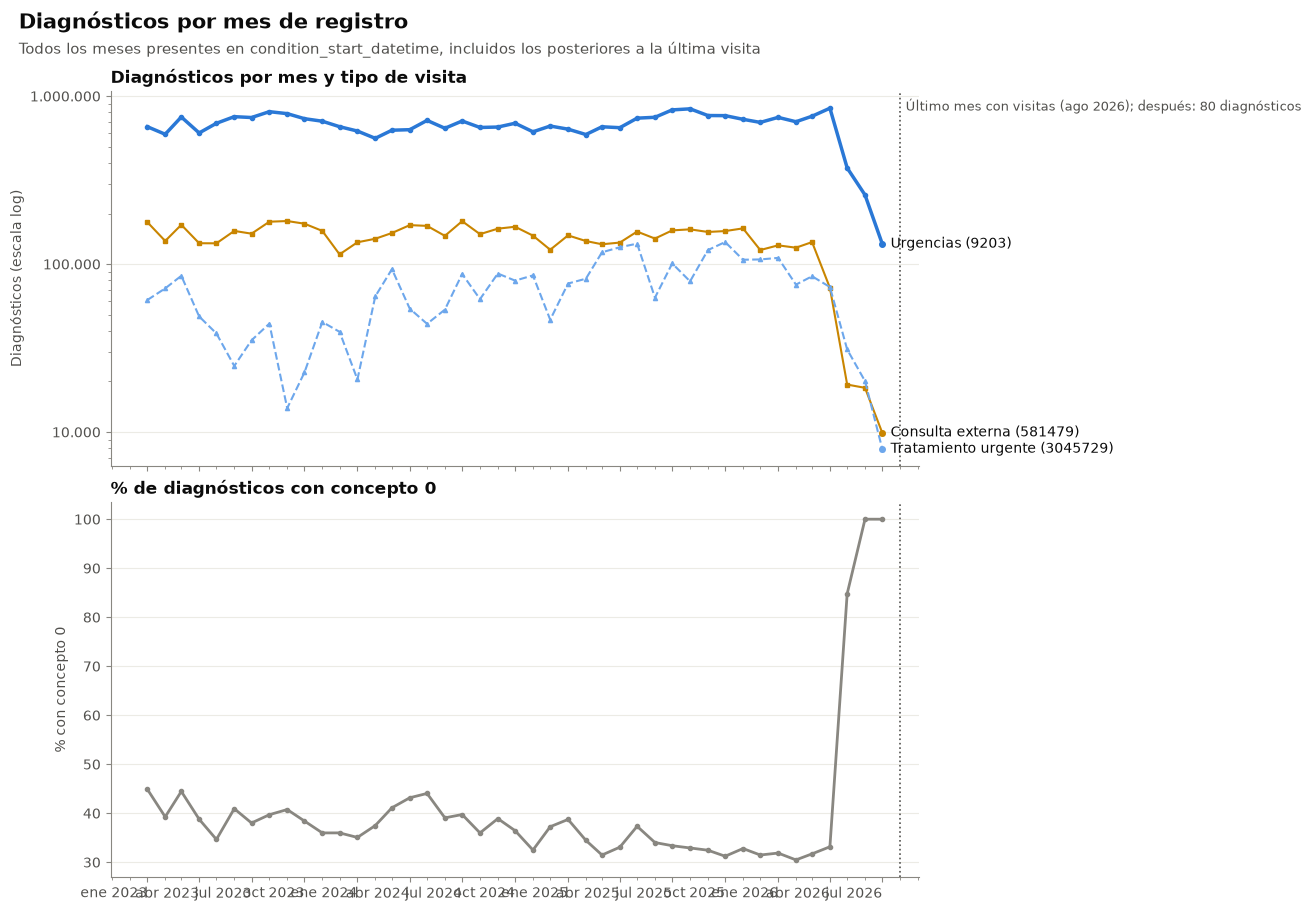

In [51]:
dx_mensual = consultar('01t_condition_mensual')
dx_mensual['mes'] = pd.to_datetime(dx_mensual['mes'])
dx_mensual['tipo_visita'] = [nombre_tipo_visita(None, n) for n in dx_mensual['tipo_visita']]
matriz_dx_mes = dx_mensual.pivot_table(index='mes', columns='tipo_visita', values='n_registros', aggfunc='sum', fill_value=0)
mostrar_tabla(suprimir_pequenos(matriz_dx_mes, list(matriz_dx_mes.columns)), 'Diagnósticos por mes y tipo de visita')
concepto_0_mes = dx_mensual.groupby('mes')[['n_registros', 'n_concepto_0']].sum().rename(columns={'n_registros': 'n'})
concepto_0_mes['pct_concepto_0'] = 100 * concepto_0_mes['n_concepto_0'] / concepto_0_mes['n']
mostrar_tabla(tabla_segura(concepto_0_mes), 'Diagnósticos con concepto 0 por mes')
ultimo_mes_visitas = pd.Timestamp(calidad_visit['rango__ultimo_mes'])
posteriores = concepto_0_mes.loc[concepto_0_mes.index > ultimo_mes_visitas, 'n'].sum()
principales = list(matriz_dx_mes.sum().sort_values(ascending=False).index[:3])
fig, ejes = plt.subplots(2, 1, figsize=(13, 9), sharex=True)
series = {}
for i, tipo in enumerate(principales):
    valores = enmascarar_pequenos(matriz_dx_mes[tipo], matriz_dx_mes[tipo])
    color = colores_tipo_visita([tipo])[0]
    ejes[0].plot(valores.index, valores, marker=MARCADORES[i], markersize=3, color=color,
                 linewidth=2.5 if es_urgencias(tipo) else 1.5, linestyle=linea_tipo_visita(tipo))
    etiquetas_directas(ejes[0], valores.index, {tipo: (valores, color)})
ejes[0].set_yscale('log')
ejes[0].set_ylabel('Diagnósticos (escala log)')
ejes[0].set_title('Diagnósticos por mes y tipo de visita')
ejes[1].plot(concepto_0_mes.index, concepto_0_mes['pct_concepto_0'].where(concepto_0_mes['n_concepto_0'] >= config.MIN_CELDA),
             marker='o', markersize=3, color=MEDIO)
ejes[1].set_ylabel('% con concepto 0')
ejes[1].set_title('% de diagnósticos con concepto 0')
for ax in ejes:
    ax.axvline(ultimo_mes_visitas, color=TEXTO_SECUNDARIO, linestyle=':', linewidth=1.2)
ejes[0].annotate(f'Último mes con visitas ({fmt_mes(ultimo_mes_visitas)}); después: {conteo_seguro(posteriores)} diagnósticos',
                 xy=(ultimo_mes_visitas, 1), xycoords=('data', 'axes fraction'), xytext=(4, -14),
                 textcoords='offset points', fontsize=estilo.TAMANO_NOTA, color=TEXTO_SECUNDARIO)
titulo_hallazgo(fig, 'Diagnósticos por mes de registro', 'Todos los meses presentes en condition_start_datetime, incluidos los posteriores a la última visita')
guardar_figura(fig, '01_condition_mensual')
plt.show()

### 4.5 Observaciones

In [52]:
n_dx = calidad_condition['n_filas']
tipo_dx = faltantes[(faltantes['tabla'] == 'condition_occurrence') & (faltantes['columna'] == 'condition_type_concept_id')].iloc[0]
items = [
    ('condition_type_concept_id', 'valores distintos', fmt_entero(tipo_dx['valores_distintos'])),
    ('condition_concept_id', 'diagnósticos con concepto 0', calidad_condition['chequeo__concepto_0'], n_dx),
    ('condition_start_datetime', 'diagnósticos con fecha posterior a la última visita registrada',
     calidad_condition['chequeo__fecha_posterior_a_la_ultima_visita'], n_dx),
    ('condition_start_datetime', 'mes más reciente con diagnósticos', fmt_mes(pd.Timestamp(calidad_condition['rango__ultimo_mes']))),
    ('visit_occurrence_id', 'diagnósticos sin visita asociada', calidad_condition['nulos__visit_occurrence_id'], n_dx),
]
for tipo, fila in repetidos.sort_values('n_registros', ascending=False).head(2).iterrows():
    items.append(('condition_concept_id', f'{tipo}: registros de diagnóstico por cada diagnóstico distinto de la visita',
                  estilo.fmt_decimal(fila['registros_por_diagnostico_distinto'], 2)))
observar('condition_occurrence', items)

**Observaciones de condition_occurrence**

,columna,hallazgo,magnitud
0,condition_type_concept_id,valores distintos,1
1,condition_concept_id,diagnósticos con concepto 0,"37,8 % (14.605.421 de 38.636.063)"
2,condition_start_datetime,diagnósticos con fecha posterior a la última visita regi...,"0,0 % (82 de 38.636.063)"
3,condition_start_datetime,mes más reciente con diagnósticos,may 2033
4,visit_occurrence_id,diagnósticos sin visita asociada,"2,1 % (823.429 de 38.636.063)"
5,condition_concept_id,Urgencias (9203): registros de diagnóstico por cada diag...,"92,37"
6,condition_concept_id,Tratamiento urgente (3045729): registros de diagnóstico ...,"297,29"


**Interpretación del equipo:** _(completar al revisar los resultados)_

## 5. `procedure_occurrence`

### Ficha del dataset

In [53]:
ver_head('procedure_occurrence')

**head(): primeras 5 filas de procedure_occurrence, ordenadas por procedure_occurrence_id**

,procedure_occurrence_id,person_id,visit_occurrence_id,procedure_concept_id,procedure_date
0,438161,1146,2980041,3040972,None
1,439286,1532,2558767,21492357,None
2,439287,1532,2671519,4185866,None
3,439288,1532,2916188,21492357,None
4,440381,1898,2521897,3040972,None


In [54]:
ver_info('procedure_occurrence')

**info(): procedure_occurrence · 47.042.032 filas × 5 columnas**

,columna,tipo de dato,no nulos,nulos,% nulos,valores distintos
0,procedure_occurrence_id,integer,47042032,0,0.000000,47042032
1,person_id,integer,47042032,0,0.000000,153428
2,visit_occurrence_id,integer,46671320,370712,0.788044,662782
3,procedure_concept_id,integer,47042032,0,0.000000,158
4,procedure_date,date,0,47042032,100.000000,0


In [55]:
ver_describe('procedure_occurrence')

**describe(): columnas numéricas y fechas de procedure_occurrence (sin columnas de ID)**

,procedure_date
estadístico,
count,0


**describe(): columnas categóricas de procedure_occurrence (top traducido con concept)**

columna,procedure_concept_id
estadístico,
count,47.042.032
unique,158
top,"Glucose measurement, blood (4144235)"
freq,4.812.788


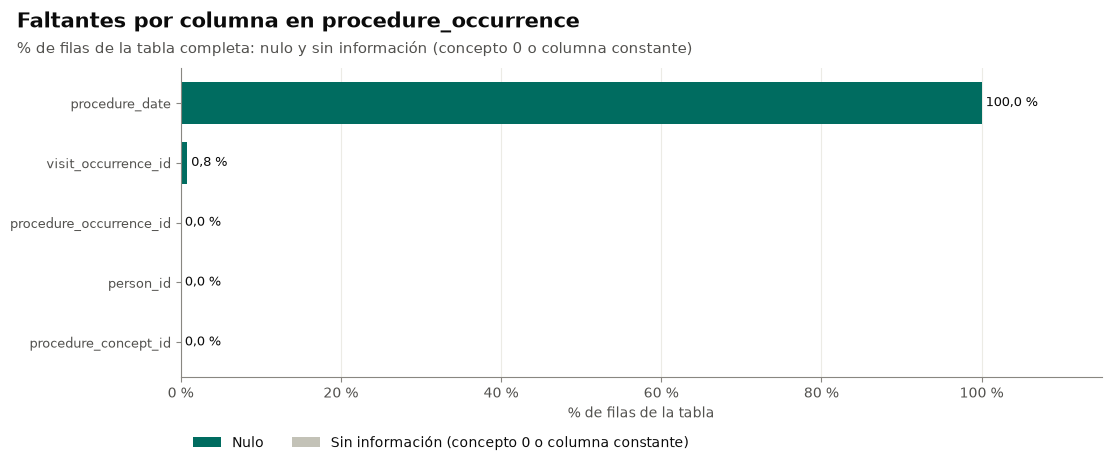

In [56]:
ver_faltantes('procedure_occurrence')

### 5.1 Descripción: diccionario frente a columnas reales

In [57]:
mostrar_tabla(suprimir_pequenos(comparar_columnas(columnas_reales, 'procedure_occurrence'), []), 'Diccionario frente a columnas reales de procedure_occurrence')

**Diccionario frente a columnas reales de procedure_occurrence**

,tipo_dato,estado
columna,,
procedure_occurrence_id,integer,existe
person_id,integer,existe
visit_occurrence_id,integer,existe
procedure_concept_id,integer,existe
procedure_date,date,no está en el diccionario
procedure_datetime,—,falta en la base
procedure_type_concept_id,—,falta en la base


### 5.2 Calidad

Incluye `procedure_date`, la única fecha de la tabla.

In [58]:
calidad_procedure = mostrar_calidad('01t_procedure_calidad', 'procedure_occurrence')

**Chequeos de calidad de procedure_occurrence**

,n,n_casos,pct_casos
chequeo,,,
concepto_0,47042032,0,0.00
concepto_sin_traduccion,47042032,0,0.00
visita_inexistente,47042032,52483,0.11


**Rango de valores de procedure_occurrence**

,valor
medida,


### 5.3 Univariado

Top 30 procedimientos (sin el concepto 0) y procedimientos por visita, con caja por tipo de visita.

**Top 30 procedimientos (sin concepto 0)**

,,,,n_registros
concepto,procedimiento,vocabulario,dominio,
4144235,"Glucose measurement, blood",SNOMED,Measurement,4812788
4016928,"Hemogram, automated, with RBC, WBC, Hgb, Hct, Indices, Platelet count, and automated complete WBC differential",SNOMED,Measurement,2953663
3003184,Emergency department Medical records,LOINC,Measurement,2951054
4194672,Specialized medical examination,SNOMED,Procedure,2827605
3040972,Emergency department Consult note,LOINC,Note,2500072
4324383,Creatinine measurement,SNOMED,Measurement,2368474
3024641,Urea nitrogen [Moles/volume] in Serum or Plasma,LOINC,Measurement,2342467
4154489,Serum potassium measurement,SNOMED,Measurement,1982374
3019550,Sodium [Moles/volume] in Serum or Plasma,LOINC,Measurement,1898733


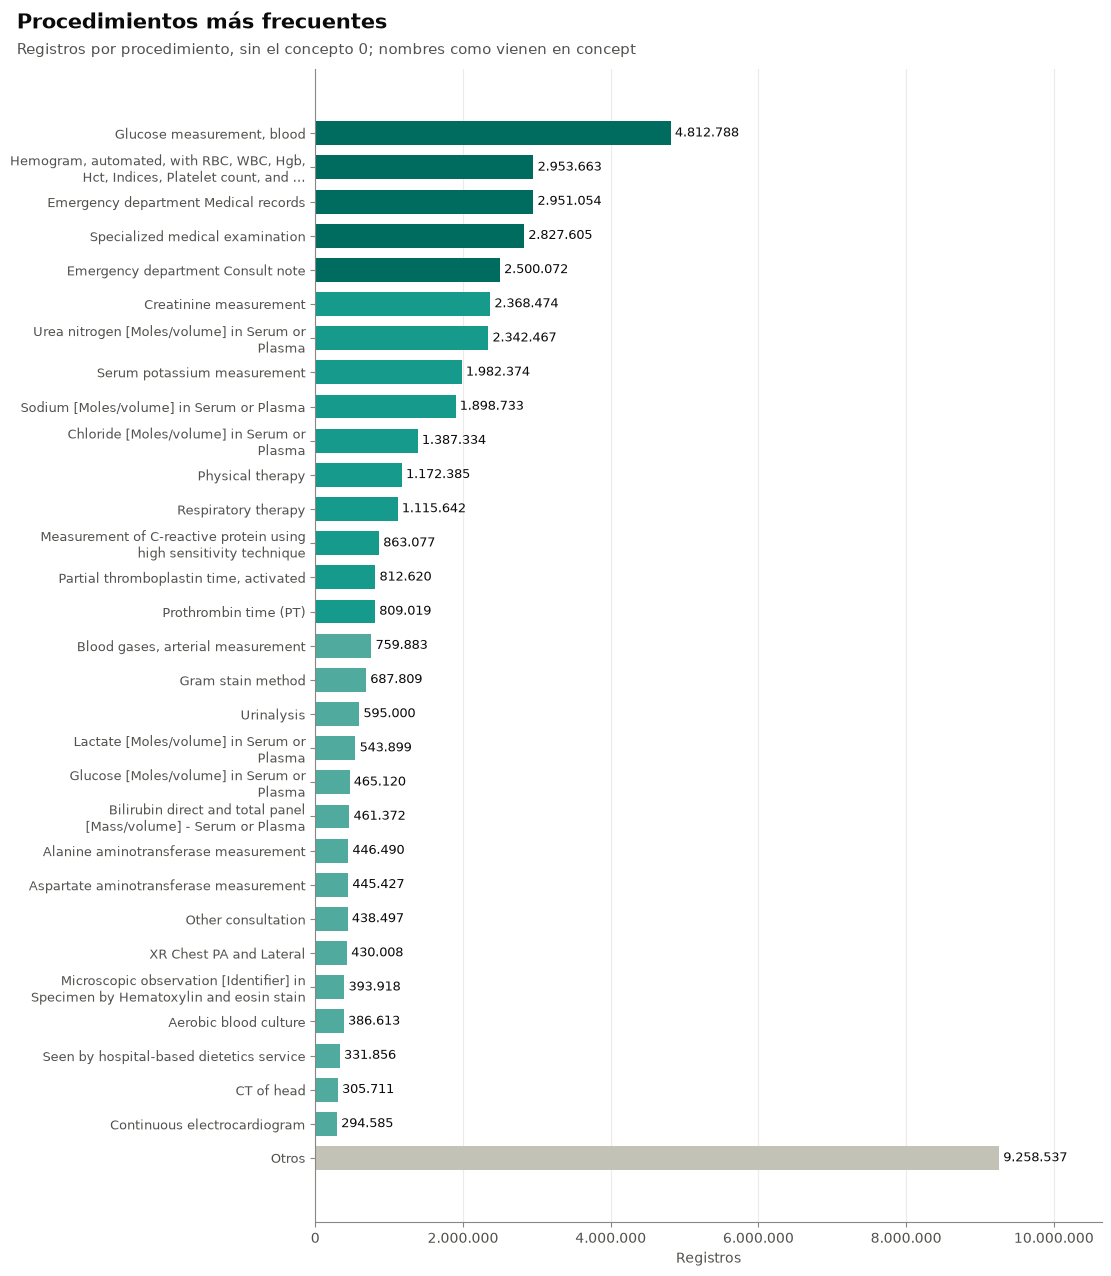

In [59]:
top_proc = consultar('01t_procedure_top30')
mostrar_tabla(tabla_segura(top_proc.set_index(['concepto', 'procedimiento', 'vocabulario', 'dominio'])), 'Top 30 procedimientos (sin concepto 0)')
fila_proc = faltantes[(faltantes['tabla'] == 'procedure_occurrence') & (faltantes['columna'] == 'procedure_concept_id')].iloc[0]
total_con_concepto = fila_proc['n'] - fila_proc['n_nulos'] - fila_proc['n_concepto_0']
serie = enmascarar_pequenos(top_proc.set_index('procedimiento')['n_registros'], top_proc.set_index('procedimiento')['n_registros'])
fig, ax = figura_top(len(serie) + 1)
barras_top_n(ax, serie, familia='general', n=30, otros=True, total=total_con_concepto)
ax.set_xlabel('Registros')
titulo_hallazgo(fig, 'Procedimientos más frecuentes', 'Registros por procedimiento, sin el concepto 0; nombres como vienen en concept')
guardar_figura(fig, '01_procedure_top30')
plt.show()

**Procedimientos por visita según el tipo de visita**

,Consulta externa (581479),Urgencias (9203),Tratamiento urgente (3045729)
procedimientos_por_visita,,,
0,738712,295463,8731
1,416,198,<10
2,121851,763,753
3,77555,40487,1156
4-5,35527,62040,628
6-9,14703,32385,379
10+,100697,166752,6205


**Estadísticos de caja: procedimientos por visita**

,n,q1,mediana,q3,whislo,whishi,minimo,maximo,n_atipicos
tipo_visita,,,,,,,,,
Consulta externa (581479),1089461.0,0.0,0.0,2.0,0.0,5.0,0.0,53636.0,115400.0
Urgencias (9203),598088.0,0.0,3.0,12.0,0.0,30.0,0.0,51304.0,104083.0
Tratamiento urgente (3045729),17858.0,0.0,2.0,42.0,0.0,105.0,0.0,15568.0,2836.0


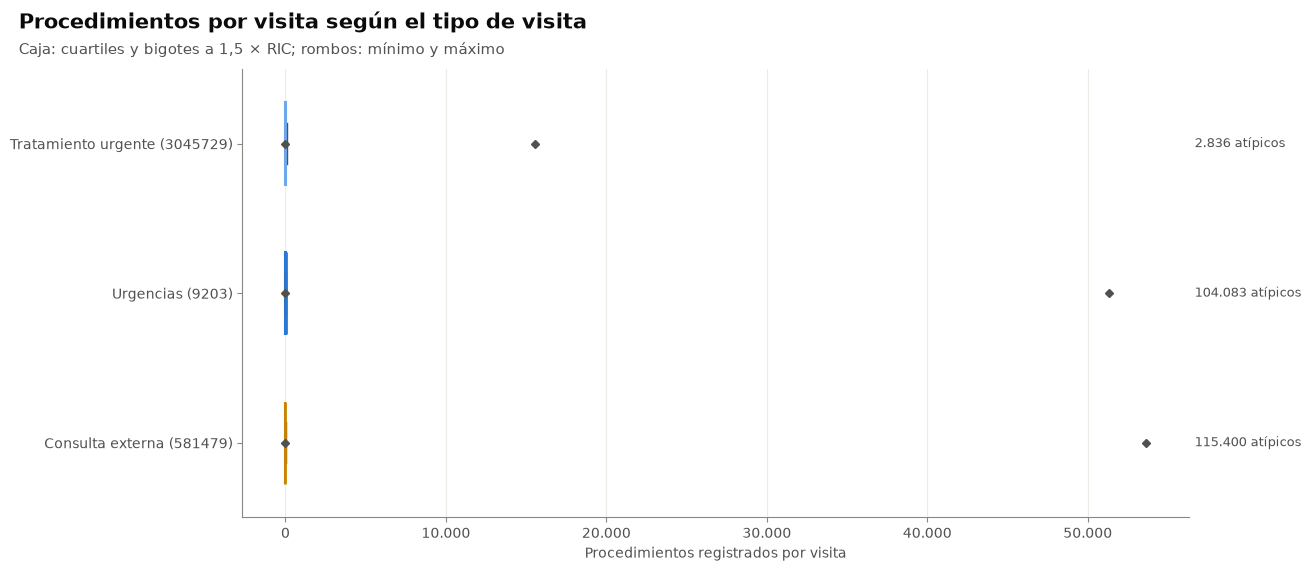

In [60]:
proc_visita = conteos_visita[conteos_visita['variable'] == 'procedimientos']
matriz_proc = pd.DataFrame({
    tipo: categorizar_conteos(proc_visita[proc_visita['tipo_visita'] == tipo]) for tipo in tipos_principales
}).rename_axis('procedimientos_por_visita')
mostrar_tabla(suprimir_pequenos(matriz_proc, list(matriz_proc.columns)), 'Procedimientos por visita según el tipo de visita')
cajas, etiquetas = cajas_desde_frecuencias(proc_visita, 'tipo_visita', 'k', 'n_visitas', tipos_principales)
mostrar_tabla(tabla_cajas(cajas, etiquetas, 'tipo_visita'), 'Estadísticos de caja: procedimientos por visita')
fig, ax = plt.subplots(figsize=(13, 1.2 * len(cajas) + 2))
dibujar_cajas(ax, cajas, etiquetas, familias_tipo_visita(etiquetas), bordes=colores_tipo_visita(etiquetas))
ax.set_xlabel('Procedimientos registrados por visita')
titulo_hallazgo(fig, 'Procedimientos por visita según el tipo de visita', 'Caja: cuartiles y bigotes a 1,5 × RIC; rombos: mínimo y máximo')
guardar_figura(fig, '01_procedure_por_visita_caja')
plt.show()

### 5.4 Bivariado

1. Top 15 procedimientos en urgencias frente a ambulatorias (una figura por tipo).
2. Dominio del concepto × tipo de visita.

**Top 15 procedimientos en urgencias y en consulta externa**

n_registros  pct_registros
tipo_visita rango concepto procedimiento                                                dominio                                
ambulatoria 1     4144235  Glucose measurement, blood                                   Measurement      1549781           9.89
            2     4016928  Hemogram, automated, with RBC, WBC, Hgb, Hct, Indices, Pl... Measurement       972699           6.21
            3     3003184  Emergency department Medical records                         Measurement       937903           5.99
            4     4194672  Specialized medical examination                              Procedure         899269           5.74
            5     3040972  Emergency department Consult note                            Note              796896           5.09
            6     4324383  Creatinine measurement                                       Measurement       767503           4.90
            7     3024641  Urea nitrogen [Moles/volume] in Serum or Plasma              Measurement       754580           4.82
            8     4154489  Serum potassium measurement                                  Measurement       636647           4.06
            9     3019550  Sodium [Moles/volume] in Serum or Plasma                     Measurement       612424           3.91
            10    3014576  Chloride [Moles/volume] in Serum or Plasma                   Measurement       443161           2.83
            11    706553   Physical therapy                                             Meas Value        376503           2.40
            12    4203780  Respiratory therapy                                          Procedure         365576           2.33
            13    46272908 Measurement of C-reactive protein using high sensitivity ... Measurement       278554           1.78
            14    4175016  Partial thromboplastin time, activated                       Measurement       261950           1.67
            15    3034426  Prothrombin time (PT)                                        Measurement       260809           1.66
urgencias   1     4144235  Glucose measurement, blood                                   Measurement      2986315          10.31
            2     3003184  Emergency department Medical records                         Measurement      1887478           6.52
            3     4016928  Hemogram, automated, with RBC, WBC, Hgb, Hct, Indices, Pl... Measurement      1826057           6.31
            4     4194672  Specialized medical examination                              Procedure        1767138           6.10
            5     3040972  Emergency department Consult note                            Note             1606896           5.55
            6     4324383  Creatinine measurement                                       Measurement      1484271           5.13
            7     3024641  Urea nitrogen [Moles/volume] in Serum or Plasma              Measurement      1471616           5.08
            8     4154489  Serum potassium measurement                                  Measurement      1230663           4.25
            9     3019550  Sodium [Moles/volume] in Serum or Plasma                     Measurement      1178433           4.07
            10    3014576  Chloride [Moles/volume] in Serum or Plasma                   Measurement       869925           3.00
            11    706553   Physical therapy                                             Meas Value        712202           2.46
            12    4203780  Respiratory therapy                                          Procedure         677443           2.34
            13    46272908 Measurement of C-reactive protein using high sensitivity ... Measurement       543968           1.88
            14    4175016  Partial thromboplastin time, activated                       Measurement       509061           1.76
            15    3034426  Prothrombin time (PT)                                        Measurement       507222           1.75

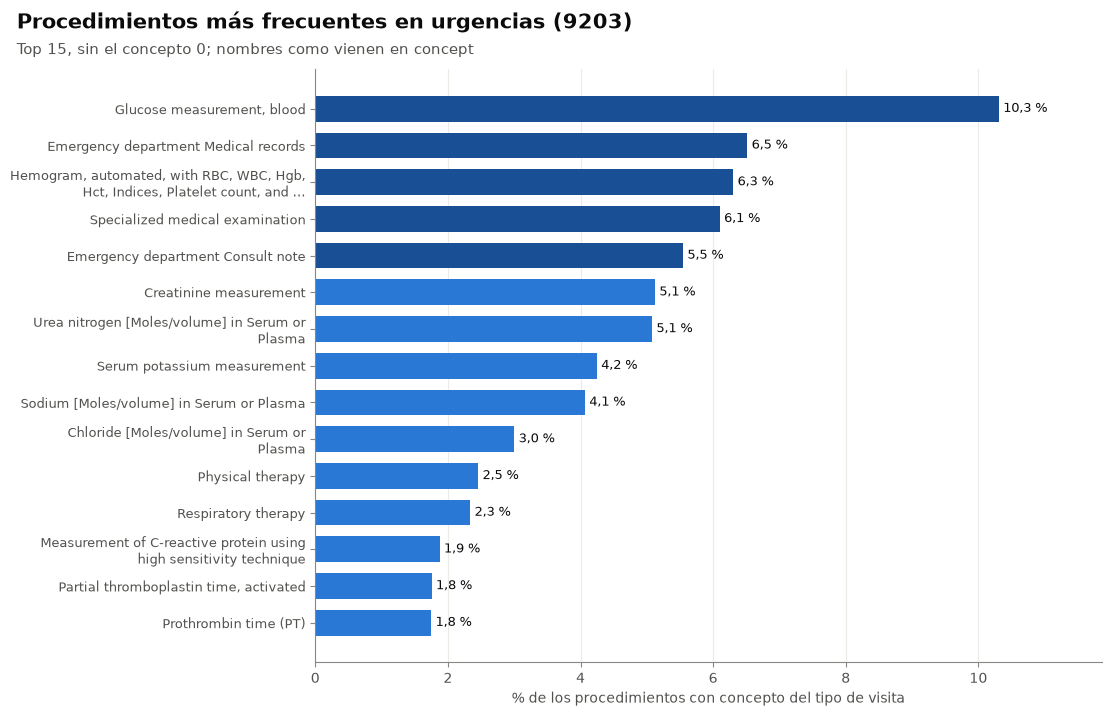

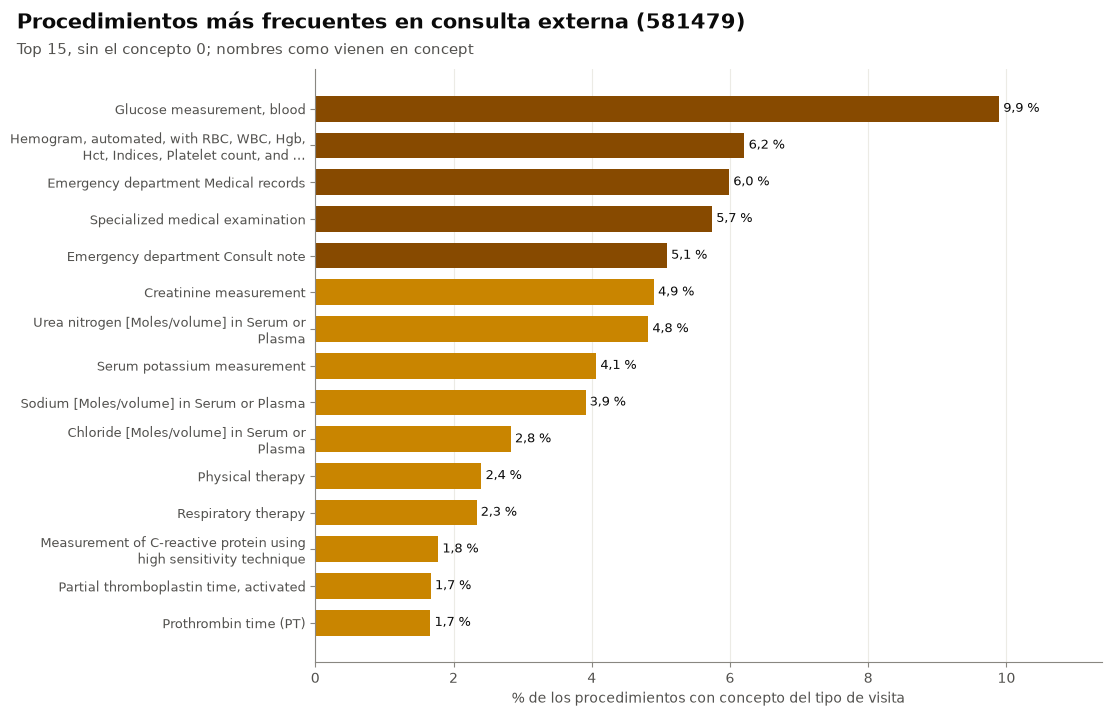

In [61]:
top_proc_urg_amb = consultar('01t_procedure_top_urg_amb')
mostrar_tabla(tabla_segura(top_proc_urg_amb.set_index(['tipo_visita', 'rango', 'concepto', 'procedimiento', 'dominio'])), 'Top 15 procedimientos en urgencias y en consulta externa')
for tipo, familia_panel, texto in [('urgencias', 'urgencias', 'urgencias (9203)'), ('ambulatoria', 'ambulatorio', 'consulta externa (581479)')]:
    parte = top_proc_urg_amb[top_proc_urg_amb['tipo_visita'] == tipo].set_index('procedimiento')
    if parte.empty:
        continue
    serie = parte['pct_registros'].where(parte['n_registros'] >= config.MIN_CELDA)
    fig, ax = figura_top(len(serie))
    barras_top_n(ax, serie, familia=familia_panel, n=15, otros=False, formato=fmt_pct)
    ax.set_xlabel('% de los procedimientos con concepto del tipo de visita')
    titulo_hallazgo(fig, f'Procedimientos más frecuentes en {texto}', 'Top 15, sin el concepto 0; nombres como vienen en concept')
    guardar_figura(fig, f'01_procedure_top_{tipo}')
    plt.show()

**Procedimientos por dominio y tipo de visita**

tipo_visita,(sin visita),Consulta externa (581479),Hospitalización (9201),Tratamiento urgente (3045729),Urgencias (9203)
dominio,,,,,
Meas Value,54710,511623,1987,86561,878523
Measurement,216734,10178320,24694,1377101,19397495
Note,59936,875254,450,42025,1626401
Observation,14584,618349,1936,71775,1107398
Procedure,77231,3480976,6397,382066,5949506


**% de procedimientos por dominio dentro de cada tipo de visita**

tipo_visita,(sin visita),Consulta externa (581479),Hospitalización (9201),Tratamiento urgente (3045729),Urgencias (9203)
dominio,,,,,
Meas Value,12.9,3.3,5.6,4.4,3.0
Measurement,51.2,65.0,69.6,70.3,67.0
Note,14.2,5.6,1.3,2.1,5.6
Observation,3.4,3.9,5.5,3.7,3.8
Procedure,18.2,22.2,18.0,19.5,20.5


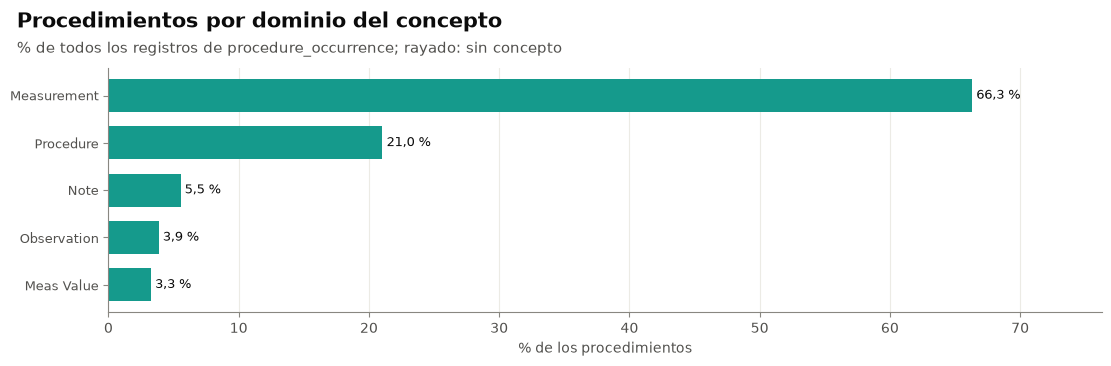

In [62]:
dominio_tipo = consultar('01t_procedure_dominio_tipo')
dominio_tipo['tipo_visita'] = [nombre_tipo_visita(None, n) for n in dominio_tipo['tipo_visita']]
matriz_dominio = dominio_tipo.pivot_table(index='dominio', columns='tipo_visita', values='n_registros', aggfunc='sum', fill_value=0)
mostrar_tabla(suprimir_pequenos(matriz_dominio, list(matriz_dominio.columns)), 'Procedimientos por dominio y tipo de visita')
pct_dominio = (100 * matriz_dominio / matriz_dominio.sum()).where(matriz_dominio >= config.MIN_CELDA)
mostrar_tabla(suprimir_pequenos(pct_dominio.round(1), []), '% de procedimientos por dominio dentro de cada tipo de visita')
por_dominio = matriz_dominio.sum(axis=1)
serie = enmascarar_pequenos(100 * por_dominio / por_dominio.sum(), por_dominio)
fig, ax = figura_top(len(serie))
barras_top_n(ax, serie, color=VERDE, n=len(serie), otros=False, formato=fmt_pct, sin_dato=ETIQUETAS_SIN_DATO)
ax.set_xlabel('% de los procedimientos')
titulo_hallazgo(fig, 'Procedimientos por dominio del concepto', '% de todos los registros de procedure_occurrence; rayado: sin concepto')
guardar_figura(fig, '01_procedure_dominio')
plt.show()

### 5.5 Observaciones

In [63]:
n_proc = calidad_procedure['n_filas']
items = [
    ('procedure_date', 'procedimientos sin fecha', calidad_procedure['nulos__procedure_date'], n_proc),
    ('procedure_concept_id', 'procedimientos con concepto 0', calidad_procedure['chequeo__concepto_0'], n_proc),
]
for dominio, n in por_dominio.sort_values(ascending=False).head(3).items():
    items.append(('procedure_concept_id', f'procedimientos de dominio {dominio}', n, por_dominio.sum()))
observar('procedure_occurrence', items)

**Observaciones de procedure_occurrence**

,columna,hallazgo,magnitud
0,procedure_date,procedimientos sin fecha,"100,0 % (47.042.032 de 47.042.032)"
1,procedure_concept_id,procedimientos con concepto 0,0 casos
2,procedure_concept_id,procedimientos de dominio Measurement,"66,3 % (31.194.344 de 47.042.032)"
3,procedure_concept_id,procedimientos de dominio Procedure,"21,0 % (9.896.176 de 47.042.032)"
4,procedure_concept_id,procedimientos de dominio Note,"5,5 % (2.604.066 de 47.042.032)"


**Interpretación del equipo:** _(completar al revisar los resultados)_

## 6. `measurement`

### Ficha del dataset

In [64]:
ver_head('measurement')

**head(): primeras 5 filas de measurement, ordenadas por measurement_id**

,measurement_id,person_id,visit_occurrence_id,measurement_concept_id,measurement_datetime,value_as_number,measurement_source_value_extended
0,384,1269,2491698,0,2023-05-16 16:17:58,0.0,GAMMA GLUTAMIL TRANSFERSA (GGT) : 18.51 U/L VALOR D...
1,385,1269,2491698,0,2023-05-16 16:15:44,0.0,FOSFATASA ALCALINA: 258.96 U/L VALORES DE REFER...
2,386,1269,2491698,0,2023-05-16 16:11:58,0.0,BILIRRUBINA TOTAL: 0.57 mg/dl REF:Hasta 1.0 BILI...
3,387,1269,2491698,0,2023-05-16 16:12:30,0.0,CLORO: 96.7 mmol/L VALORES REFERENCIA: 98 -107
4,388,1269,2491698,0,2023-05-16 16:11:22,0.0,PROTEINA C REACTIVA: 2.0 mg/L VALOR RE...


In [65]:
ver_info('measurement')

**info(): measurement · 16.575.888 filas × 7 columnas**

,columna,tipo de dato,no nulos,nulos,% nulos,valores distintos
0,measurement_id,integer,16575888,0,0.000000,16575888
1,person_id,integer,16575888,0,0.000000,112634
2,visit_occurrence_id,integer,16267452,308436,1.860751,184757
3,measurement_concept_id,integer,16575888,0,0.000000,72
4,measurement_datetime,timestamp without time zone,16575888,0,0.000000,1047162
5,value_as_number,numeric,10202646,6373242,38.448872,6264
6,measurement_source_value_extended,text,16575888,0,0.000000,512414


In [66]:
ver_describe('measurement')

**describe(): columnas numéricas y fechas de measurement (sin columnas de ID)**

,value_as_number,measurement_datetime
estadístico,,
count,10.202.646,16.575.888
mean,25.444403,NaN
std,57.680214,NaN
min,0.0,2023-01-01 00:08:11
25%,0.14,2023-11-18 18:38:41
50%,4.54,2024-10-01 19:03:16
75%,22.8,2025-07-30 04:38:48
max,1699.0,2026-07-17 18:58:28


**describe(): columnas categóricas de measurement (top traducido con concept)**

columna,measurement_concept_id
estadístico,
count,16.575.888
unique,72
top,No matching concept (0)
freq,8.876.114


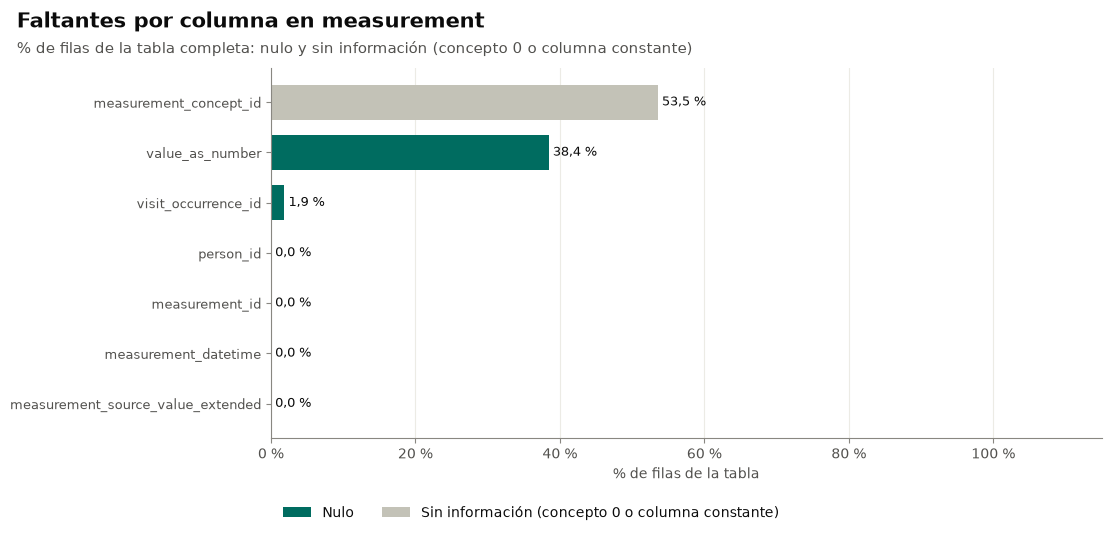

In [67]:
ver_faltantes('measurement')

### 6.1 Descripción: diccionario frente a columnas reales

In [68]:
mostrar_tabla(suprimir_pequenos(comparar_columnas(columnas_reales, 'measurement'), []), 'Diccionario frente a columnas reales de measurement')

**Diccionario frente a columnas reales de measurement**

,tipo_dato,estado
columna,,
measurement_id,integer,existe
person_id,integer,existe
visit_occurrence_id,integer,existe
measurement_concept_id,integer,existe
measurement_datetime,timestamp without time zone,existe
value_as_number,numeric,existe
measurement_source_value_extended,text,no está en el diccionario
unit_concept_id,—,falta en la base
measurement_type_concept_id,—,falta en la base


### 6.2 Calidad

In [69]:
calidad_measurement = mostrar_calidad('01t_measurement_calidad', 'measurement')

**Chequeos de calidad de measurement**

,n,n_casos,pct_casos
chequeo,,,
concepto_0,16575888,8876114,53.55
concepto_0_con_texto,16575888,8876114,53.55
concepto_sin_traduccion,16575888,0,0.00
con_valor_numerico,16575888,10202646,61.55
visita_inexistente,16575888,16239,0.10


**Rango de valores de measurement**

,valor
medida,
primer_mes,2023-01-01
ultimo_mes,2026-07-01


### 6.3 Univariado

Registros por vocabulario, top 30 mediciones y `value_as_number` de las 10 mediciones más frecuentes con valor (una caja por medición, cada una en su escala).

**Mediciones por vocabulario**

,n_registros,n_conceptos,pct_registros
vocabulario,,,
None,8876114,<10,53.55
SNOMED,7053374,50,42.55
LOINC,643972,20,3.88
ICD10CM,2428,<10,0.01


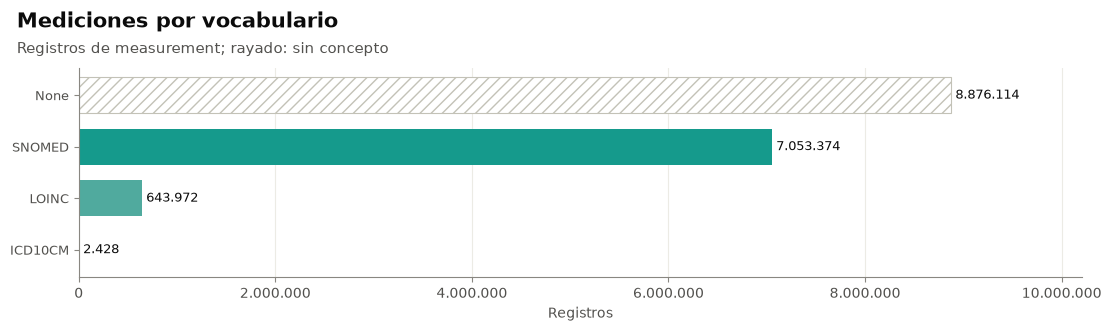

In [70]:
vocabularios = consultar('01_mediciones_vocabulario').set_index('vocabulario')
mostrar_tabla(tabla_segura(agregar_porcentaje(vocabularios, 'n_registros')), 'Mediciones por vocabulario')
serie = enmascarar_pequenos(vocabularios['n_registros'], vocabularios['n_registros'])
fig, ax = figura_top(len(serie))
barras_top_n(ax, serie, color=[estilo.COLOR_VOCABULARIO.get(v, VERDE) for v in serie.index], n=len(serie), otros=False,
             sin_dato=ETIQUETAS_SIN_DATO)
ax.set_xlabel('Registros')
titulo_hallazgo(fig, 'Mediciones por vocabulario', 'Registros de measurement; rayado: sin concepto')
guardar_figura(fig, '01_measurement_vocabulario')
plt.show()

**Top 30 mediciones**

,,,,n_registros,n_con_valor,n_visitas,pct_con_valor
concepto_medicion,medicion,vocabulario,dominio,,,,
0,No matching concept,None,Metadata,8876114,5445445,153621,61.35
4016928,"Hemogram, automated, with RBC, WBC, Hgb, Hct, Indices, Platelet count, and automated complete WBC differential",SNOMED,Measurement,5706597,3128262,70917,54.82
4074649,Urea nitrogen measurement,SNOMED,Measurement,171380,203,47985,0.12
3024641,Urea nitrogen [Moles/volume] in Serum or Plasma,LOINC,Measurement,171317,204,47969,0.12
4245152,Potassium measurement,SNOMED,Measurement,132711,132204,26768,99.62
4154489,Serum potassium measurement,SNOMED,Measurement,132674,132167,26766,99.62
4097430,Sodium measurement,SNOMED,Measurement,127393,126947,26669,99.65
3019550,Sodium [Moles/volume] in Serum or Plasma,LOINC,Measurement,127363,126915,26665,99.65
3014576,Chloride [Moles/volume] in Serum or Plasma,LOINC,Measurement,95998,95998,24473,100.00


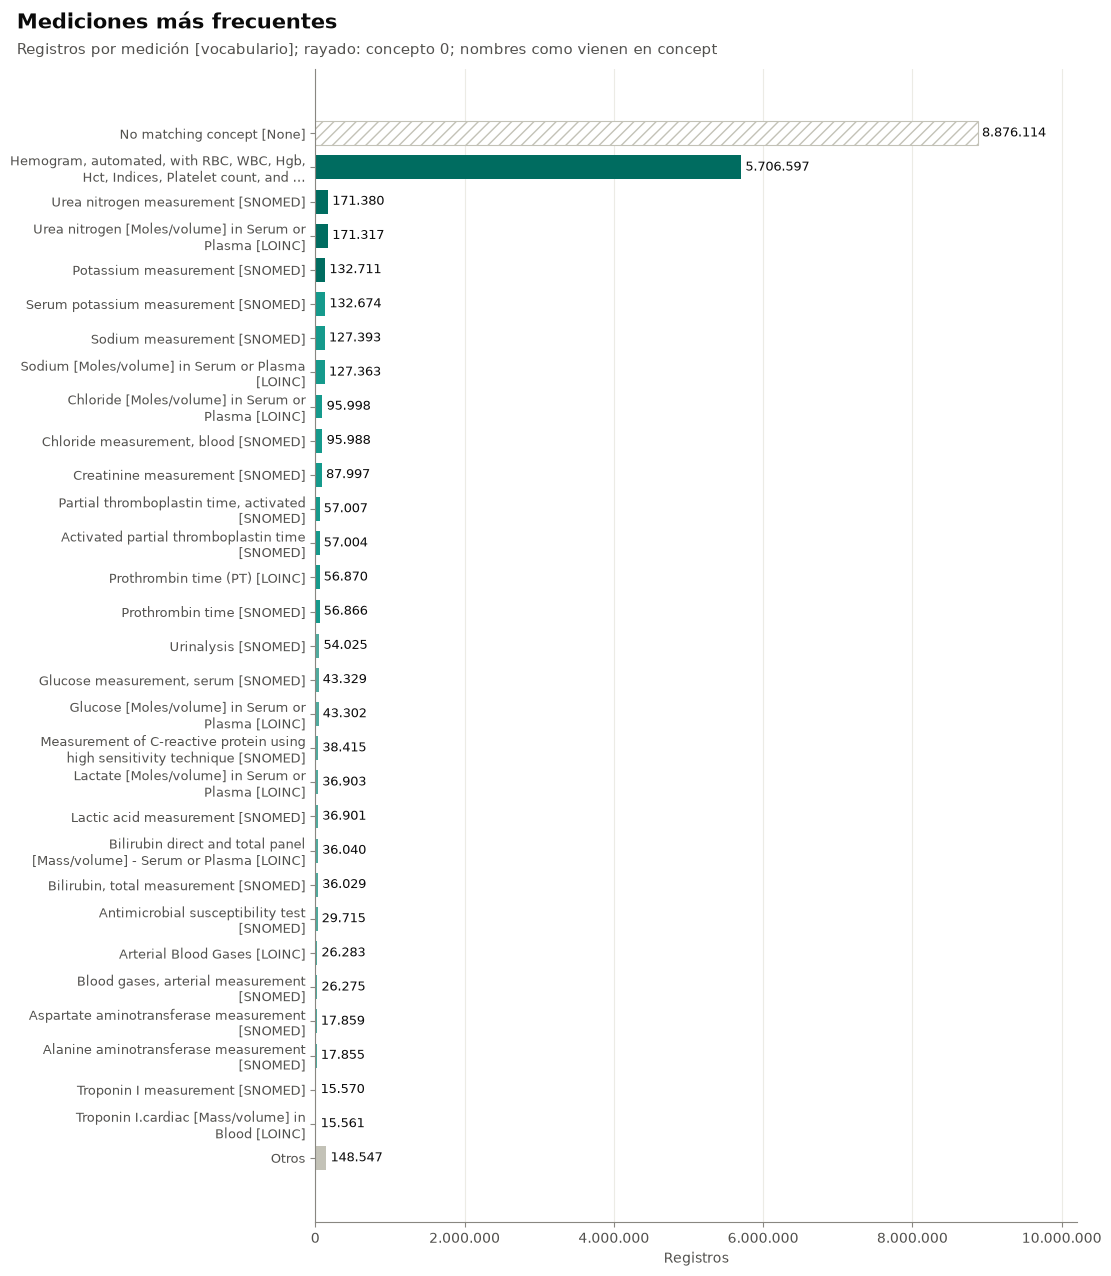

In [71]:
mediciones_top = consultar('01_mediciones_top').head(30)
mediciones_top['pct_con_valor'] = 100 * mediciones_top['n_con_valor'] / mediciones_top['n_registros']
mostrar_tabla(tabla_segura(mediciones_top.set_index(['concepto_medicion', 'medicion', 'vocabulario', 'dominio'])), 'Top 30 mediciones')
etiquetas_medicion = [f'{m} [{v}]' for m, v in zip(mediciones_top['medicion'], mediciones_top['vocabulario'])]
serie = pd.Series(mediciones_top['n_registros'].to_numpy(), index=etiquetas_medicion)
serie = enmascarar_pequenos(serie, serie)
sin_concepto = {e for e, c in zip(etiquetas_medicion, mediciones_top['concepto_medicion']) if c == 0}
fig, ax = figura_top(len(serie) + 1)
barras_top_n(ax, serie, familia='general', n=30, otros=True, total=calidad_measurement['n_filas'],
             sin_dato=sin_concepto)
ax.set_xlabel('Registros')
titulo_hallazgo(fig, 'Mediciones más frecuentes', 'Registros por medición [vocabulario]; rayado: concepto 0; nombres como vienen en concept')
guardar_figura(fig, '01_measurement_top30')
plt.show()

**value_as_number de las 10 mediciones más frecuentes con valor**

,,,n,p00,p01,p25,p50,p75,p99,p100,n_atipicos
concepto,medicion,vocabulario,,,,,,,,,
4016928,"Hemogram, automated, with RBC, WBC, Hgb, Hct, Indices, Platelet count, and automated complete WBC differential",SNOMED,3128262,0.00,0.00,1.30,8.90,29.20,333.00,1699.0,337222
4245152,Potassium measurement,SNOMED,132204,1.06,2.73,3.70,4.07,4.47,6.20,386.0,4334
4154489,Serum potassium measurement,SNOMED,132167,1.06,2.73,3.70,4.07,4.47,6.20,386.0,4330
4097430,Sodium measurement,SNOMED,126947,3.04,123.00,134.50,136.90,139.40,159.00,190.2,9889
3019550,Sodium [Moles/volume] in Serum or Plasma,LOINC,126915,3.04,123.00,134.50,136.90,139.40,159.00,190.2,9898
3014576,Chloride [Moles/volume] in Serum or Plasma,LOINC,95998,0.00,0.00,0.00,0.00,0.00,0.00,0.0,<10
4019545,"Chloride measurement, blood",SNOMED,95988,0.00,0.00,0.00,0.00,0.00,0.00,0.0,<10
4324383,Creatinine measurement,SNOMED,87765,0.02,0.50,0.88,1.08,1.41,7.95,343.0,9034
4175016,"Partial thromboplastin time, activated",SNOMED,57007,0.00,0.00,0.00,0.00,0.00,0.00,0.0,<10


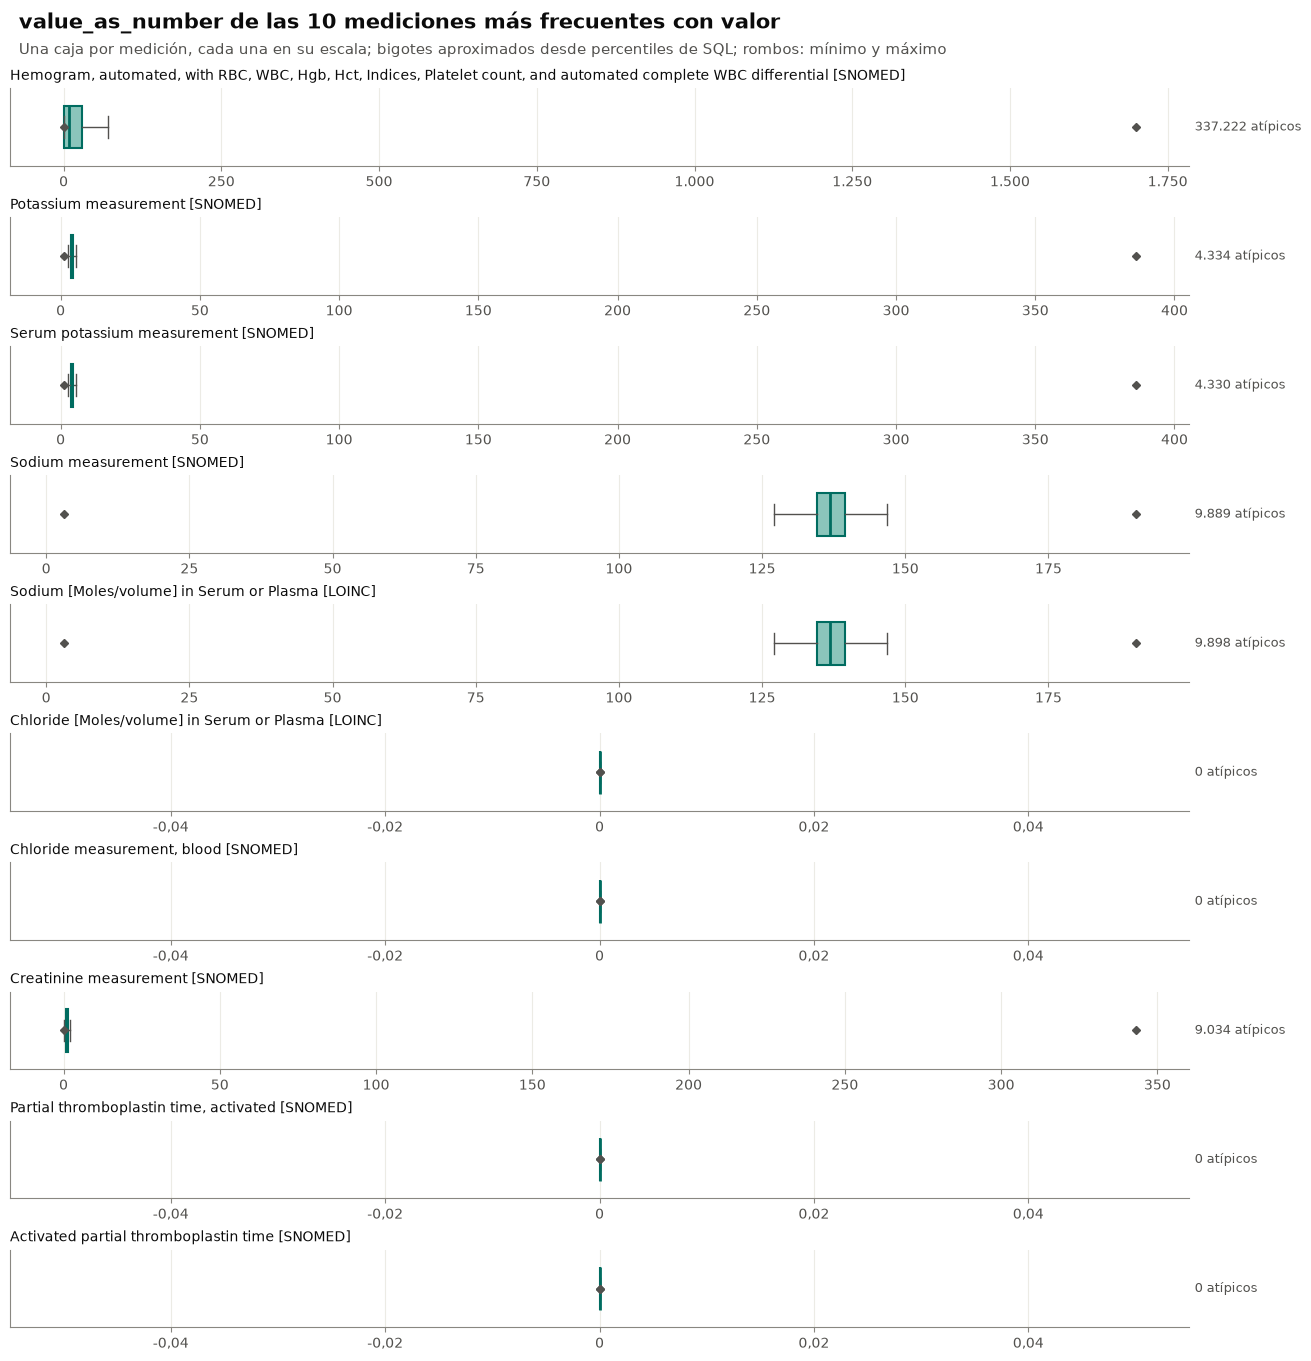

In [72]:
valores_top = consultar('01t_measurement_valor_percentiles')
mostrar_tabla(tabla_segura(valores_top.set_index(['concepto', 'medicion', 'vocabulario'])), 'value_as_number de las 10 mediciones más frecuentes con valor')
valores_top = valores_top[valores_top['n'] >= config.MIN_CELDA]
fig, ejes = plt.subplots(len(valores_top), 1, figsize=(13, 1.15 * len(valores_top) + 2), squeeze=False)
for ax, (_, fila) in zip(ejes[:, 0], valores_top.iterrows()):
    dibujar_cajas(ax, [estadisticos_caja_desde_percentiles(fila)], [''], 'general')
    ax.set_yticks([])
    ax.set_title(f"{fila['medicion']} [{fila['vocabulario']}]", fontsize=estilo.TAMANO_EJES, fontweight='normal')
titulo_hallazgo(fig, 'value_as_number de las 10 mediciones más frecuentes con valor',
                'Una caja por medición, cada una en su escala; bigotes aproximados desde percentiles de SQL; rombos: mínimo y máximo')
guardar_figura(fig, '01_measurement_valores_caja')
plt.show()

### 6.4 Bivariado

1. Mediciones por mes y vocabulario.
2. Duplicación SNOMED/LOINC: grupos de mediciones de la misma visita y la misma fecha y hora.

**Mediciones por mes y vocabulario**

vocabulario,ICD10CM,LOINC,SNOMED,concepto 0
mes,,,,
2023-01-01,19,6522,103467,313839
2023-02-01,21,5602,84607,239008
2023-03-01,32,6381,97401,272203
2023-04-01,16,6028,82932,222098
2023-05-01,27,7195,89185,230191
2023-06-01,42,7204,98969,237101
2023-07-01,43,12093,177084,250554
2023-08-01,34,13189,183959,252236
2023-09-01,26,12702,182244,245127


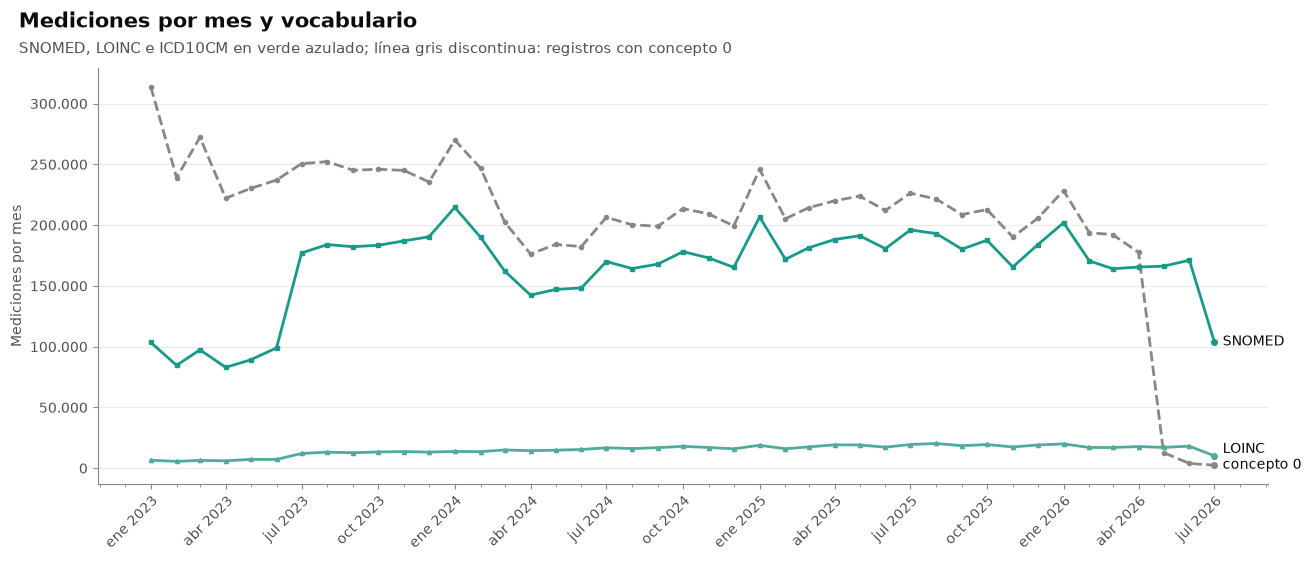

In [73]:
med_mensual = consultar('01t_measurement_mensual')
med_mensual['mes'] = pd.to_datetime(med_mensual['mes'])
matriz_med = med_mensual.pivot_table(index='mes', columns='vocabulario', values='n_registros', aggfunc='sum', fill_value=0)
mostrar_tabla(suprimir_pequenos(matriz_med, list(matriz_med.columns)), 'Mediciones por mes y vocabulario')
principales = list(matriz_med.sum().sort_values(ascending=False).index[:3])
fig, ax = plt.subplots(figsize=(13, 5.5))
for i, vocabulario in enumerate(principales):
    valores = enmascarar_pequenos(matriz_med[vocabulario], matriz_med[vocabulario])
    if vocabulario in ETIQUETAS_SIN_DATO:
        color, linea = MEDIO, '--'
    else:
        color, linea = estilo.COLOR_VOCABULARIO.get(vocabulario, VERDE), '-'
    ax.plot(valores.index, valores, marker=MARCADORES[i], markersize=3, color=color, linestyle=linea)
    etiquetas_directas(ax, valores.index, {vocabulario: (valores, color)})
ax.set_ylabel('Mediciones por mes')
titulo_hallazgo(fig, 'Mediciones por mes y vocabulario', 'SNOMED, LOINC e ICD10CM en verde azulado; línea gris discontinua: registros con concepto 0')
guardar_figura(fig, '01_measurement_mensual')
plt.show()

In [74]:
grupos_vocab = consultar('01t_measurement_grupos_vocabulario').set_index('categoria')
grupos_vocab = agregar_porcentaje(grupos_vocab, 'n_grupos')
mostrar_tabla(tabla_segura(grupos_vocab), 'Grupos (visita, fecha y hora) según los vocabularios presentes')
pares = consultar('01t_measurement_pares_snomed_loinc').set_index(['medicion_snomed', 'medicion_loinc'])
mostrar_tabla(tabla_segura(pares), 'Pares SNOMED/LOINC más frecuentes (grupos con un registro de cada vocabulario)')

**Grupos (visita, fecha y hora) según los vocabularios presentes**

,n_grupos,n_registros,n_grupos_mismo_numero,pct_grupos
categoria,,,,
1 SNOMED y LOINC,304056,1431010.0,268260,15.73
2 solo SNOMED,450644,6170947.0,<10,23.32
3 solo LOINC,17972,18558.0,<10,0.93
4 ni SNOMED ni LOINC,1159713,8646937.0,1159713,60.01


**Pares SNOMED/LOINC más frecuentes (grupos con un registro de cada vocabulario)**

,,n_pares,n_mismo_valor,pct_mismo_valor
medicion_snomed,medicion_loinc,,,
"Blood gases, arterial measurement",Arterial Blood Gases,21631,21631,100.0
Blood group antigen type - finding,ABO group [Type] in Blood,3172,3172,100.0
Thyroid stimulating hormone measurement,Thyroxine (T4) free [Moles/volume] in Serum or Plasma,249,249,100.0
Hepatitis B surface antigen in serum qualitative result,HIV 1+2 Ab and HIV1 p24 Ag panel - Serum or Plasma by Immunoassay,200,200,100.0
Urea nitrogen measurement,Urea nitrogen [Moles/volume] in Serum or Plasma,111,<10,suprimido
Sodium measurement,Sodium [Moles/volume] in Serum or Plasma,86,86,100.0
"Chloride measurement, blood",Chloride [Moles/volume] in Serum or Plasma,64,64,100.0
Alkaline phosphatase measurement,Amylase [Enzymatic activity/volume] in Serum or Plasma,55,55,100.0
Prothrombin time,Prothrombin time (PT),37,37,100.0


### 6.5 Observaciones

In [75]:
n_med = calidad_measurement['n_filas']
ambos = grupos_vocab[grupos_vocab.index.str.contains('SNOMED y LOINC')]
items = [
    ('measurement_concept_id', 'mediciones con concepto 0', calidad_measurement['chequeo__concepto_0'], n_med),
    ('measurement_source_value_extended', 'mediciones con concepto 0 que tienen texto',
     calidad_measurement['chequeo__concepto_0_con_texto'], calidad_measurement['chequeo__concepto_0']),
    ('value_as_number', 'mediciones sin valor numérico', calidad_measurement['nulos__value_as_number'], n_med),
]
if not ambos.empty:
    items.append(('measurement_concept_id', 'grupos (visita, fecha y hora) con registros SNOMED y LOINC a la vez',
                  ambos['n_grupos'].iloc[0], grupos_vocab['n_grupos'].sum()))
observar('measurement', items)

**Observaciones de measurement**

,columna,hallazgo,magnitud
0,measurement_concept_id,mediciones con concepto 0,"53,5 % (8.876.114 de 16.575.888)"
1,measurement_source_value_extended,mediciones con concepto 0 que tienen texto,"100,0 % (8.876.114 de 8.876.114)"
2,value_as_number,mediciones sin valor numérico,"38,4 % (6.373.242 de 16.575.888)"
3,measurement_concept_id,"grupos (visita, fecha y hora) con registros SNOMED y LOI...","15,7 % (304.056 de 1.932.385)"


**Interpretación del equipo:** _(completar al revisar los resultados)_

## 7. `concept` y `cups`

In [76]:
tamano_catalogos = consultar('01t_concept_tamano').set_index('tabla')
mostrar_tabla(suprimir_pequenos(tamano_catalogos, []), 'Tamaño de los catálogos concept y cups')
mostrar_tabla(suprimir_pequenos(comparar_columnas(columnas_reales, 'cups'), []), 'Columnas de cups')
uso_conceptos = consultar('01t_concept_uso').set_index(['tabla', 'dominio', 'vocabulario'])
mostrar_tabla(tabla_segura(agregar_porcentaje(uso_conceptos, 'n_registros', por='tabla')), 'Conceptos usados por tabla, dominio y vocabulario')

**Tamaño de los catálogos concept y cups**

,n_filas,distintos_codigo,distintos_dominio,distintos_vocabulario,distintos_periodo
tabla,,,,,
cups,94086,16992,NaN,NaN,7.0
concept,10004331,10004331,43.0,130.0,NaN


**Columnas de cups**

,tipo_dato,estado
columna,,
codigo,character varying,no está en el diccionario
descripcion,character varying,no está en el diccionario
periodo,character varying,no está en el diccionario


**Conceptos usados por tabla, dominio y vocabulario**

conceptos_distintos n_registros pct_registros
tabla                dominio     vocabulario                                                  
condition_occurrence Condition   SNOMED                         3814  23072557.0         59.72
                     Metadata    None                              1  14605421.0          37.8
                     Observation SNOMED                          240    790248.0          2.05
                     Procedure   SNOMED                           53    136734.0          0.35
                     Observation OMOP Extension                    3     16727.0          0.04
                     Measurement Cancer Modifier                  10     11519.0          0.03
                                 SNOMED                           24      2857.0          0.01
measurement          Metadata    None                              1   8876114.0         53.55
                     Measurement SNOMED                           49   7050159.0         42.53
                                 LOINC                            19    617689.0          3.73
                     Meas Value  LOINC                             1     26283.0          0.16
                     Condition   SNOMED                            1      3215.0          0.02
                                 ICD10CM                           1      2428.0          0.01
person (etnia)       Ethnicity   Ethnicity                         2    912205.0         100.0
person (raza)        Metadata    None                              1    867831.0         95.14
                     Race        Race                              2     44374.0          4.86
person (sexo)        Gender      Gender                            2    912076.0         99.99
                     Metadata    None                              1       129.0          0.01
procedure_occurrence Measurement SNOMED                           41  18875521.0         40.12
                                 LOINC                            20  12318823.0         26.19
                     Procedure   SNOMED                           56   8660233.0         18.41
                     Note        LOINC                             7   2604066.0          5.54
                     Observation SNOMED                           22   1814042.0          3.86
                     Meas Value  LOINC                             3   1533404.0          3.26
                     Procedure   ICD9Proc                          4    566088.0           1.2
                                 LOINC                             3    536478.0          1.14
                                 OPCS4                             1     72772.0          0.15
                                 ICD10PCS                          1     60605.0          0.13
visit_detail         Visit       Visit                             3   2129422.0         64.89
                     Measurement LOINC                             1   1152191.0         35.11
visit_occurrence     Visit       Visit                             3   1688141.0         98.95
                     Measurement LOINC                             1     17858.0          1.05
                     Metadata    None                      suprimido         <10     suprimido

## 8. Resumen de hallazgos de calidad

Todos los hallazgos de las secciones de Observaciones, con su magnitud calculada a partir de los datos.

In [77]:
resumen_hallazgos = pd.DataFrame(hallazgos).set_index(['tabla', 'columna'])
mostrar_tabla(suprimir_pequenos(resumen_hallazgos, []), 'Resumen de hallazgos de calidad')

**Resumen de hallazgos de calidad**

hallazgo                            magnitud
tabla                columna                                                                                                                           
person               year_of_birth                                         personas con año de nacimiento igual a 1               0,0 % (85 de 912.205)
                     year_of_birth                                   personas con año de nacimiento anterior a 1900               0,0 % (87 de 912.205)
                     year_of_birth                                            personas con año de nacimiento futuro                             0 casos
                     race_concept_id                    personas con raza sin información (concepto 0 o sin trad...         95,1 % (867.831 de 912.205)
                     ethnicity_concept_id                     personas en la etnia más frecuente (Hispana o latina)         99,8 % (910.140 de 912.205)
                     gender_concept_id                                            personas con sexo sin información              0,0 % (129 de 912.205)
                     edad al llegar                                          visitas de urgencias con edad negativa                           <10 casos
                     edad al llegar                                       visitas de urgencias con edad mayor a 110               0,0 % (23 de 598.088)
visit_occurrence     visit_end_datetime                                             visitas con fin igual al inicio    100,0 % (1.706.001 de 1.706.001)
                     visit_end_datetime                                          visitas con fin anterior al inicio                             0 casos
                     provider_id                                                                  valores distintos                                   1
                     visit_start_datetime                             visitas que empiezan exactamente a medianoche          0,1 % (1.136 de 1.706.001)
                     visit_start_datetime                                                           meses cubiertos              de ene 2023 a ago 2026
                     visit_detail (relación)                                 visitas de urgencias sin ninguna etapa           8,9 % (53.373 de 598.088)
visit_detail         provider_id                                                                  valores distintos                                   1
                     visit_detail_start_datetime        etapas que empiezan más de 1 h antes del inicio de su vi...       29,1 % (954.931 de 3.281.613)
                     visit_detail_end_datetime                                    etapas con fin anterior al inicio                             0 casos
                     visit_detail_end_datetime                                                etapas con duración 0     63,9 % (2.097.541 de 3.281.613)
                     visit_detail_start_datetime        Hospitalización en piso (9201): empiezan más de 1 h ante...          29,0 % (31.457 de 108.510)
                     visit_detail_start_datetime        Ingreso por urgencias (9203): empiezan más de 1 h antes ...          19,7 % (94.923 de 481.481)
                     visit_detail_start_datetime        Ingreso ambulatorio (581479): empiezan más de 1 h antes ...       31,2 % (479.784 de 1.539.339)
                     visit_detail_start_datetime        Movimiento o etapa (3045729): empiezan más de 1 h antes ...       30,3 % (348.767 de 1.152.166)
                     visit_detail_end_datetime                             Ingreso ambulatorio (581479): duración 0    100,0 % (1.539.340 de 1.539.340)
                     visit_detail_end_datetime                             Movimiento o etapa (3045729): duración 0       38,5 % (443.359 de 1.152.191)
                     visit_detail_end_datetime                             Ingreso por urgencias (9203): duración 0         23,1 % (111.309 de 481.481)
   